# WTI forecasting with two independent ML-generated factors

**Correlation-screened candidate fields → the 12 lowest individual XGBoost CV errors per target → one joint scalar factor per downstream model.** ARIMAX receives `X_ARIMAX`; VARX receives its own `X_VARX`. Each generator jointly uses exactly **12 selected raw fields**, with past 1–5 quote values per field (60 input features). The two models rank the candidate fields separately against their own targets, so their selected lists can differ. A factor may be weak; it remains visible and is compared with an explicit no-factor baseline.

| Downstream model | ML training target | Scalar regressor | No-factor comparison |
|---|---|---|---|
| Hybrid ARIMAX | Next-quote WTI dollar change | X_ARIMAX | ARIMA on WTI changes |
| VARX | Next-quote WTI residual from a causal reference VAR | X_VARX | VAR with the same WTI/Brent backbone |

Each model generates the complete recursive **60-quote path**. Mean models use WTI dollar changes, so negative WTI observations remain valid. GARCH(1,1) supplies conditional uncertainty. RMSE/MAPE use h = 1, 5, 20 and 60; other metrics and trading holding periods cover h = 1–60.

In [3]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import importlib.metadata as metadata
import importlib.util
import re
import subprocess
import sys

requirements = {
    "numpy": ("numpy", "1.26"), "pandas": ("pandas", "2.0"),
    "scipy": ("scipy", "1.11"), "matplotlib": ("matplotlib", "3.8"),
    "scikit-learn": ("sklearn", "1.3"), "statsmodels": ("statsmodels", "0.14"),
    "arch": ("arch", "6.3"), "xgboost": ("xgboost", "2.1"),
    "ipython": ("IPython", "8.0"),
}
def version_tuple(s):
    numbers = re.findall(r"\d+", s)
    return tuple(int(x) for x in numbers[:3]) + (0,) * max(0, 3-len(numbers[:3]))
needed=[]
for package,(module,minimum) in requirements.items():
    try:
        installed=metadata.version(package)
        if version_tuple(installed) < version_tuple(minimum): needed.append(package+">="+minimum)
    except metadata.PackageNotFoundError:
        needed.append(package+">="+minimum)
if needed:
    print("Installing in this kernel:",needed)
    subprocess.check_call([sys.executable,"-m","pip","install",*needed])
print("Python interpreter:",sys.executable)
print("Dependencies ready. If an older version was already imported in this kernel, restart the kernel once.")

Python interpreter: D:\Anaconda\python.exe
Dependencies ready. If an older version was already imported in this kernel, restart the kernel once.


### Model Stationarity Check

In [4]:
%run -i "WTI_Stationarity_Addon.py"

Saved-model root checks completed; no model was refitted.
Latest successful saved fits: conditional dynamics; MA invertibility is separate.


,model,origin_date,n_train,companion_radius,minimum_AR_root_modulus,AR_condition_met,integration_d,minimum_MA_root_modulus,MA_invertibility_met,MA_near_unit_boundary,conditional_dynamics_status
0,ARIMA | Expanding,2026-10-23,3197,N/A,3.91189792213,True,0.0,2.32708441604,True,False,stable
1,ARIMA | Rolling500,2026-10-23,500,N/A,1.31804590192,True,0.0,1.24751553143,True,False,stable
2,Hybrid | Expanding,2026-10-23,3197,N/A,3.88272534698,True,0.0,2.31882687873,True,False,stable
3,Hybrid | Rolling500,2026-10-23,500,N/A,1.28493075361,True,0.0,1.20774410218,True,False,stable
4,VAR | Expanding,2026-10-23,3197,0.391897673967,N/A,NaN,NaN,N/A,NaN,NaN,stable
5,VAR | Rolling500,2026-10-23,500,0.486571129214,N/A,NaN,NaN,N/A,NaN,NaN,stable
6,VARX | Expanding,2026-10-23,3197,0.391922764313,N/A,NaN,NaN,N/A,NaN,NaN,stable
7,VARX | Rolling500,2026-10-23,500,0.500747495704,N/A,NaN,NaN,N/A,NaN,NaN,stable


All-origin summary (failed/unavailable fits are retained):


,model,family,N_saved_rows,N_successful_fits,N_recomputed,N_saved_radius_only,N_stable,N_unstable,N_near_unit_boundary,N_integrated_d_positive,N_failed_fits,N_unavailable,N_MA_noninvertible,max_companion_radius,minimum_AR_root_modulus,minimum_MA_root_modulus
0,ARIMA | Expanding,ARIMA,557,557,557,0,557,0,0,0,0,0,0,NaN,3.521674,2.132577
1,ARIMA | Rolling500,ARIMA,557,557,557,0,557,0,0,0,0,0,0,NaN,1.001099,1.000001
2,Hybrid | Expanding,Hybrid,557,557,557,0,557,0,0,0,0,0,0,NaN,3.497542,2.129280
3,Hybrid | Rolling500,Hybrid,557,557,557,0,557,0,0,0,0,0,0,NaN,1.017394,1.000000
4,VAR | Expanding,VAR,557,557,557,0,557,0,0,0,0,0,0,0.431669,NaN,NaN
5,VAR | Rolling500,VAR,557,557,557,0,557,0,0,0,0,0,0,0.628386,NaN,NaN
6,VARX | Expanding,VARX,557,557,557,0,557,0,0,0,0,0,0,0.431545,NaN,NaN
7,VARX | Rolling500,VARX,557,557,557,0,557,0,0,0,0,0,0,0.630477,NaN,NaN


Historical training-series evidence: ADF H0=unit root; KPSS H0=level stationarity.


,series,window,train_end,N_finite,ADF_pvalue,KPSS_pvalue,stationarity_evidence,status
0,"WTI price level (diagnostic, not differenced m...",Expanding,2026-10-23,3197,0.2428,0.01,consistent_with_nonstationarity,ok
1,WTI one-quote change (mean-model dependent ser...,Expanding,2026-10-23,3197,0,0.1,consistent_with_level_stationarity,ok
2,"WTI price level (diagnostic, not differenced m...",Rolling500,2026-10-23,500,0.8103,0.01,consistent_with_nonstationarity,ok
3,WTI one-quote change (mean-model dependent ser...,Rolling500,2026-10-23,500,4.676e-15,0.1,consistent_with_level_stationarity,ok
4,X_ARIMAX (historical OOF signal),Expanding,2026-10-23,3197,4.525e-26,0.01,mixed_test_evidence,ok
5,X_ARIMAX (historical OOF signal),Rolling500,2026-10-23,500,0.000695,0.1,consistent_with_level_stationarity,ok
6,Brent one-quote change (VAR endogenous input),Expanding,2026-10-23,3197,4.403e-27,0.1,consistent_with_level_stationarity,ok
7,Brent one-quote change (VAR endogenous input),Rolling500,2026-10-23,500,2.457e-06,0.1,consistent_with_level_stationarity,ok
8,X_VARX (historical OOF signal),Expanding,2026-10-23,3197,1.56e-24,0.01,mixed_test_evidence,ok
9,X_VARX (historical OOF signal),Rolling500,2026-10-23,500,9.02e-05,0.1,consistent_with_level_stationarity,ok


Root conditions concern conditional mean/error dynamics. They do not establish stationarity of oil levels, generated X or the full GARCH system.
KPSS may report table-bound p-values; see warnings in the CSV. No forecasts or model choices have been changed.
Stationarity reports: D:\Study\NUS Documentation\Coursework\2026 Semester 1\QF5210\Group project\WTI_Independent_ML_Results\09_stationarity_checks


## 1. Settings and information timeline

ML input selection uses an **initial development prefix ending 31 December 2013**, with chronological validation folds inside that prefix. Field admission uses that same cutoff. The selected inputs are then frozen before the first historical factor is produced. This prevents a field choice based on later data from leaking backward into historical stacked regressors.

From the first quote after that freeze, historical factors are forward cross-fitted: the XGBoost model is fitted before each 20-quote block, then uses only lagged information available before each target. All downstream mean models share the resulting `MEAN_START`, printed after factor generation. Source observations from September 2009 support initial development and warm-up; they are not fabricated early generated regressors.

| Stage | Information allowed |
|---|---|
| ML field admission, prescreen and chronological field selection | Through ML_SELECTION_END only |
| Historical factor at target t | Frozen inputs; fitting labels before its block; predictor states before t |
| Forecast at origin t | Observed WTI, input states and labels through t only |
| Validation reference | 31 July 2024–31 July 2026 |
| Test targets | 1–23 October 2026 |

The original workflow's **test-based window/family/final selection** is retained and explicitly labelled retrospective. Validation figures and reference rankings are displayed beside the test results. ML field selection itself never uses those periods. No performance target is forced.

`RUN_MODE="full"` fits the full validation grid. `"smoke"` is a visibly reduced development run; its validation metrics do not represent a full-period backtest.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np

RUN_MODE = "full"                 # "full" or "smoke"
DATA_SOURCE = Path("Oil_Daily_65_20261023.zip")
if not DATA_SOURCE.exists() and Path("Oil_Daily_65").is_dir():
    DATA_SOURCE = Path("Oil_Daily_65")
if not DATA_SOURCE.exists():
    raise FileNotFoundError("Place the existing 65-field ZIP beside the Notebook, or set DATA_SOURCE to its ZIP/folder path. Working directory: " + str(Path.cwd()))
OUTPUT_DIR = Path.cwd() / ("WTI_Independent_ML_Results" if RUN_MODE == "full" else "WTI_Independent_ML_Smoke_Results")
cfg = {
    "H":60, "KEY_HORIZONS":[1,5,20,60], "ROLLING_WINDOW":500,
    "COMMON_START":"2009-09-21", "ML_SELECTION_END":"2013-12-31",
    "VAL_START":"2024-07-31", "VAL_END":"2026-07-31",
    "TEST_START":"2026-10-01", "TEST_END":"2026-10-23",
    "VAR_LAG":2, "COMMON_BURN":2, "ARIMAX_ORDER":[1,0,1],
    "ML_LAGS":[1,2,3,4,5], "ML_MIN_TRAIN":250, "ML_REFIT_EVERY":20,
    "ML_CV_SPLITS":3, "ML_CV_MIN_TRAIN":500, "ML_CV_WINDOWS":[500,None],
    "ML_CORR_THRESHOLD":0.1, "ML_KEEP_FIELDS":12,
    "XGB_LAGS":5, "XGB_TREES":60, "XGB_DEPTH":2, "XGB_LEARNING_RATE":0.05,
    "MAXITER":300, "ARIMAX_LBFGS_MAXFUN":2000, "ARIMAX_POWELL_MAXFUN":3000,
    "GARCH_MAXITER":300, "SEED":42, "FIT_GARCH":True,
    "POOL_MIN_UPDATES":24, "POOL_MIN_DISTINCT":20, "POOL_MAX_STALE_FRACTION":0.05,
    "DMSFE_THETA":0.9, "MIN_VALID_COVERAGE":0.8,
    "THRESHOLD":0.005, "ONE_WAY_BPS":5, "TRADE_H":5,
    "RUN_MODE":RUN_MODE, "VALIDATION_ORIGIN_STEP":1,
    "SHOW_PLOTS":True, "SHOW_VALIDATION_PLOTS":True,
    "RETRY_FAILURES":True, "PRINT_EVERY":10, "ML_PRINT_EVERY":50,
}
assert RUN_MODE in {"full", "smoke"}
assert pd.Timestamp(cfg["ML_SELECTION_END"]) < pd.Timestamp(cfg["VAL_START"]) <= pd.Timestamp(cfg["VAL_END"]) < pd.Timestamp(cfg["TEST_START"]) <= pd.Timestamp(cfg["TEST_END"])
if RUN_MODE == "smoke":
    cfg.update(ML_CV_SPLITS=2)
    print("SMOKE MODE: fewer chronological CV folds and validation origins; exactly 12 fields are still selected per generator. Not full-period performance evidence.")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Outputs:", OUTPUT_DIR.resolve())
print("ML field-selection freeze:", cfg["ML_SELECTION_END"])
print("Rolling window:", cfg["ROLLING_WINDOW"], "equation targets; Expanding starts at common OOF mean history.")

Outputs: D:\Study\NUS Documentation\Coursework\2026 Semester 1\QF5210\Group project\WTI_Independent_ML_Results
ML field-selection freeze: 2013-12-31
Rolling window: 500 equation targets; Expanding starts at common OOF mean history.


## 2. Self-contained implementation

The following cells contain data reading, independent factor selection, causal factor generation, mean/GARCH models, evaluation, combinations and trading. Implementation cells may be collapsed while reading the report.

The scalar generated regressors are **predictive ML signals**, not demonstrated structurally exogenous economic quantities. Factor prediction errors and estimated-model uncertainty are not included in the conditional GARCH intervals.

In [6]:
"""Portable 65-field data inventory and training-only feature admission.

No value is backward-filled, interpolated or replaced. The fixed quote calendar
is preserved even for rejected fields. Admission uses rows strictly before
VAL_START. Historical publication buffers and revised research vintages are
inherited from the supplied archive; they are not verified first releases.
"""

import json
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd


TARGET_DERIVED_IDS = {"F009", "F010", "F011"}
LEVEL_IDS = {"F027", "F038", "F062", "F063", "F076"}
LOG_RETURN_IDS = {"F005", "F019", "F022"}
DEFAULT_COMMON_START = "2009-09-21"
DEFAULT_VAL_START = "2024-07-31"


def field_category(field_id):
    """Economic labels are declared from definitions, not fitted correlations."""
    if field_id.startswith("F064"):
        return "Annual GDP"
    if field_id in TARGET_DERIVED_IDS:
        return "Target-derived spreads"
    if field_id in {"F001", "F002", "F003", "F004", "F022", "F039", "F040", "F041", "F042", "F043", "F044", "F045"}:
        return "Energy and commodity prices"
    if field_id in {"F008", "F038"}:
        return "Futures curve"
    if field_id in {"F027", "F028", "F029", "F030", "F031", "F068"}:
        return "Singapore hub"
    if field_id in {"F058", "F059", "F060", "F061"}:
        return "Positioning"
    if field_id in {"F062", "F063", "F076"}:
        return "News and geopolitical risk"
    if field_id in {"F005", "F006", "F007", "F019", "F020", "F021", "F065", "F066", "F067"}:
        return "Markets, FX and rates"
    if field_id in {"F053", "F054"}:
        return "Industrial activity"
    return "Inventories and physical supply"


def _intervals(index, mask):
    """Compress true row runs as inclusive dates on the fixed quote calendar."""
    index = pd.DatetimeIndex(index)
    mask = np.asarray(mask, dtype=bool)
    if len(mask) != len(index):
        raise ValueError("Quality mask length mismatch")
    result, start = [], None
    for i, flag in enumerate(mask):
        if flag and start is None:
            start = i
        if start is not None and (not flag or i == len(mask) - 1):
            stop = i if flag else i - 1
            result.append([str(index[start].date()), str(index[stop].date())])
            start = None
    return json.dumps(result, separators=(",", ":"))


def _interval_mask(index, encoded):
    """Filter all-calendar quality metadata at the caller's training cutoff."""
    index = pd.DatetimeIndex(index)
    result = np.zeros(len(index), dtype=bool)
    if encoded is None or (isinstance(encoded, float) and np.isnan(encoded)):
        return result
    intervals = json.loads(encoded) if isinstance(encoded, str) else encoded
    for first, last in intervals:
        result |= (index >= pd.Timestamp(first)) & (index <= pd.Timestamp(last))
    return result


def transform_feature(values, method):
    """Fixed semantic transforms; no transform is chosen on validation/test."""
    values = pd.to_numeric(values, errors="coerce").replace([np.inf, -np.inf], np.nan)
    if method == "diff":
        return values.diff()
    if method in {"log_return", "logreturn"}:
        # Do not mask a nonpositive value as an arbitrary positive constant.
        return 100.0 * np.log(values.where(values > 0)).diff()
    if method == "level":
        return values.copy()
    raise ValueError("Unknown feature transform: " + str(method))


def _assemble_oil_inputs(read_csv):
    """Read supplied as-of values and quality flags through one CSV backend.

    Produces exactly 65 raw factor columns plus price on the source quote
    calendar. Metadata's interval columns allow arbitrary earlier admission
    cutoffs without consulting current/end-of-sample coverage summaries.
    """
    dictionary = read_csv("metadata/field_dictionary.csv", encoding="utf-8-sig")
    x = read_csv("model_inputs/X_all65_values.csv", index_col="date", parse_dates=True)
    target = read_csv("target/WTI_target_daily.csv", index_col="date", parse_dates=True)
    ids = dictionary.field_id.astype(str).tolist()
    if len(ids) != 65 or len(set(ids)) != 65 or set(x.columns) != set(ids):
        raise ValueError("Expected exactly the supplied 65 distinct factor IDs")
    if not x.index.equals(target.index) or not x.index.is_unique or not x.index.is_monotonic_increasing:
        raise ValueError("Target and 65-field quote calendars must match")
    raw = pd.concat([target.wti_usd_per_bbl.rename("price"), x[ids]], axis=1)
    raw.index.name = "date"
    metadata = []
    for item in dictionary.itertuples(index=False):
        field_id = str(item.field_id)
        filename = str(item.filename)
        if not filename or "/" in filename or "\\" in filename or filename in {".", ".."}:
            raise ValueError("Invalid daily field filename in metadata: " + filename)
        daily = read_csv("daily_fields/" + filename, index_col="date", parse_dates=True)
        if not daily.index.equals(raw.index):
            raise ValueError("Daily field calendar differs: " + field_id)
        if not np.allclose(daily.value.to_numpy(float), raw[field_id].to_numpy(float), equal_nan=True):
            raise ValueError("Published as-of panel differs from daily field values: " + field_id)
        transform = "level" if field_id in LEVEL_IDS or str(item.original_frequency) == "A" else "logreturn" if field_id in LOG_RETURN_IDS else "diff"
        transform_reason = (
            "100 times the first difference of the logarithm of a positive market index/price; S&P500 preserves the locked baseline"
            if transform == "logreturn" else
            "Already a growth rate, binary state, sentiment/risk index or conditional standard deviation"
            if transform == "level" else
            "One-quote change in the source's native standardized units; signed values remain defined"
        )
        stale = pd.to_numeric(daily.is_stale, errors="coerce").fillna(1).ne(0)
        retrospective = pd.to_numeric(daily.is_retrospective, errors="coerce").fillna(0).ne(0)
        unavailable = daily.status.astype(str).isin(["not_yet_available", "source_discontinued", "stale_source"])
        verified = pd.to_numeric(daily.release_date_verified, errors="coerce").fillna(0).eq(1)
        metadata.append({
            "field_id": field_id, "name": str(item.name_en), "name_zh": str(item.name_zh),
            "category": field_category(field_id), "frequency": str(item.original_frequency),
            "kind": str(item.kind), "unit": str(item.unit), "transform": transform,
            "transform_reason": transform_reason, "target_derived": field_id in TARGET_DERIVED_IDS,
            "timing_verified": False,
            "first_release_vintage_verified": bool(int(item.point_in_time_vintage_verified)),
            "timing_status": "Supplied as-of publication buffers; historical first releases unverified",
            "research_vintage": True,
            "proxy_series": field_id == "F062",
            "proxy_note": "Broad US economic-news sentiment, not oil-specific sentiment" if field_id == "F062" else "",
            "source_note": str(item.source_note), "source_url": str(item.source_url),
            "source_default_model_include": bool(int(item.default_model_include)),
            "max_carry_days": int(item.max_carry_days),
            "stale_intervals_json": _intervals(raw.index, stale),
            "unavailable_intervals_json": _intervals(raw.index, unavailable),
            "retrospective_intervals_json": _intervals(raw.index, retrospective),
            "release_verified_intervals_json": _intervals(raw.index, verified),
        })
    meta = pd.DataFrame(metadata)
    return raw, meta


def load_existing_oil_data(data_source):
    """Read the existing 65-field archive or extracted folder, without writes.

    ``data_source`` may be the original ZIP, its extracted Oil_Daily_65 root,
    or the immediate parent containing that root. ZIP members are streamed
    directly with ZipFile.open; no extraction or duplicate input files occur.
    Ambiguous complete data roots and duplicate ZIP member names are rejected.
    """
    source = Path(data_source).expanduser()
    required = ("metadata/field_dictionary.csv", "model_inputs/X_all65_values.csv",
                "target/WTI_target_daily.csv")
    if not source.exists():
        raise FileNotFoundError("Existing oil data source was not found: " + str(source))
    if source.is_file():
        if not zipfile.is_zipfile(source):
            raise ValueError("Data source must be the original ZIP or an extracted data directory")
        with zipfile.ZipFile(source, "r") as archive:
            names = archive.namelist()
            if len(names) != len(set(names)):
                raise ValueError("ZIP contains duplicate member names; provide an unambiguous data archive")
            members = set(names)
            suffix = required[0]
            roots = sorted({name[:-len(suffix)] for name in names if name.endswith(suffix)
                            and (name == suffix or name[-len(suffix)-1] == "/")})
            roots = [root for root in roots if all(root + name in members for name in required)]
            if len(roots) != 1:
                raise ValueError("Expected exactly one complete 65-field data root in ZIP; found " + str(len(roots)))
            prefix = roots[0]

            def read_member(relative, **kwargs):
                member = prefix + relative
                if member not in members:
                    raise FileNotFoundError("Required data file is missing from ZIP: " + member)
                with archive.open(member, "r") as stream:
                    return pd.read_csv(stream, **kwargs)

            return _assemble_oil_inputs(read_member)
    if not source.is_dir():
        raise ValueError("Data source must be a ZIP file or directory")
    candidates = [source] + [child for child in source.iterdir() if child.is_dir()]
    roots = [candidate for candidate in candidates
             if all((candidate / name).is_file() for name in required)]
    if len(roots) != 1:
        raise ValueError("Expected exactly one complete 65-field data root in this directory or its immediate children; found " + str(len(roots)))
    root = roots[0]

    def read_local(relative, **kwargs):
        return pd.read_csv(root / relative, **kwargs)

    return _assemble_oil_inputs(read_local)


def build_frozen_inputs(source_directory, output_directory):
    """Optional compatibility exporter; notebook loading itself is read-only."""
    raw, meta = load_existing_oil_data(source_directory)
    out = Path(output_directory)
    out.mkdir(parents=True, exist_ok=True)
    raw.to_csv(out / "frozen_panel65.csv", index=True, encoding="utf-8-sig", na_rep="NA")
    meta.to_csv(out / "feature_metadata.csv", index=False, encoding="utf-8-sig", na_rep="NA")
    return raw, meta


def _as_bool(value):
    if isinstance(value, str):
        return value.strip().lower() in {"1", "true", "yes"}
    return bool(value) if pd.notna(value) else False


def prepare_feature_pool(raw, metadata, cfg, outdir=None):
    """Return (common_panel, eligible_ids, audit, transform_map).

    Admission is an audit of TRAINING rows only, strictly before VAL_START.
    The returned panel retains all factors, NaNs and dates from COMMON_START;
    it is not reduced to eligible columns or to a future-complete calendar.
    No development/validation/test data are filled. Later missing values stay
    missing for native ML routing and diagnostics; insufficient fitting support
    remains an explicit failure rather than a future-coverage selection rule.

    Required defaults: complete raw/as-of history on this fixed training
    calendar, >=20 distinct values (>=2 for binary fields), >=24 numerical
    updates and no stale/unavailable input at the training cutoff. Annual GDP
    is excluded explicitly: repeated daily values do not create daily releases.
    The 97% threshold is reported as a diagnostic, not a substitute for complete
    histories. Revised/retrospective research vintages remain declared rather
    than being misrepresented as verified historical first releases.
    """
    raw = raw.copy()
    raw.index = pd.to_datetime(raw.index).normalize()
    if raw.index.duplicated().any() or not raw.index.is_monotonic_increasing:
        raise ValueError("Frozen input dates must be sorted and unique")
    raw.index.name = "date"
    metadata = metadata.copy()
    if "field_id" not in metadata:
        raise ValueError("feature_metadata requires field_id")
    if metadata.field_id.duplicated().any():
        raise ValueError("Duplicate metadata field IDs")
    ids = metadata.field_id.astype(str).tolist()
    if len(ids) != 65 or set(raw.columns) != set(ids) | {"price"}:
        raise ValueError("Expected price plus exactly 65 metadata-backed factors")
    raw = raw[["price"] + ids].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    if raw.price.isna().any():
        raise ValueError("Every source WTI target quote must be observed")
    common_start = pd.Timestamp(cfg.get("COMMON_START", DEFAULT_COMMON_START))
    val_start = pd.Timestamp(cfg.get("VAL_START", DEFAULT_VAL_START))
    panel = raw.loc[raw.index >= common_start].copy()
    train = panel.loc[panel.index < val_start]
    if len(train) < max(150, int(cfg.get("ROLLING_WINDOW", 500)) + 10):
        raise ValueError("Insufficient fixed pre-validation training calendar")
    min_updates = int(cfg.get("POOL_MIN_UPDATES", 24))
    min_unique = int(cfg.get("POOL_MIN_DISTINCT", 20))
    diagnostic_coverage = float(cfg.get("POOL_DIAGNOSTIC_COVERAGE", 0.97))
    max_stale_fraction = float(cfg.get("POOL_MAX_STALE_FRACTION", 0.05))
    transforms, rows, eligible = {}, [], []
    for item in metadata.to_dict("records"):
        field_id = str(item["field_id"])
        method = str(item["transform"])
        values = train[field_id]
        transformed = transform_feature(values, method)
        usable_transform = transformed if method == "level" else transformed.iloc[1:]
        coverage = float(values.notna().mean())
        distinct = int(values.nunique(dropna=True))
        numeric_updates = int((values.diff().ne(0) & values.notna() & values.shift().notna()).sum())
        stale = _interval_mask(train.index, item.get("stale_intervals_json", "[]"))
        unavailable = _interval_mask(train.index, item.get("unavailable_intervals_json", "[]"))
        retrospective = _interval_mask(train.index, item.get("retrospective_intervals_json", "[]"))
        release_verified = _interval_mask(train.index, item.get("release_verified_intervals_json", "[]"))
        reasons = []
        if _as_bool(item.get("target_derived", False)):
            reasons.append("target-derived contemporaneous WTI component; excluded from external-factor pool")
        if str(item["frequency"]).upper() == "A":
            reasons.append("annual GDP: insufficient independent release frequency for this daily candidate pool")
        if values.notna().sum() == 0:
            reasons.append("wholly missing in fixed training calendar")
        elif coverage < 1.0:
            reasons.append("incomplete fixed training history; no backfill or hidden imputation")
        if values.isna().iloc[0]:
            reasons.append("no observation at fixed COMMON_START")
        if values.isna().iloc[-1] or unavailable[-1] or stale[-1]:
            reasons.append("unavailable/stale at pre-validation training cutoff")
        if distinct < (2 if str(item["kind"]) == "binary" else min_unique):
            reasons.append("too few distinct training values")
        if numeric_updates < min_updates:
            reasons.append("too few numerical updates in training")
        if len(usable_transform) == 0 or usable_transform.isna().any() or not np.isfinite(usable_transform.to_numpy(float)).all():
            reasons.append("nonfinite transformed training history")
        elif float(usable_transform.std(ddof=1)) <= 1e-12:
            reasons.append("constant transformed training signal")
        if float(stale.mean()) > max_stale_fraction:
            reasons.append("excess historical stale fraction in training")
        accepted = len(reasons) == 0
        transforms[field_id] = method
        if accepted:
            eligible.append(field_id)
        rows.append({
            **{k: item.get(k) for k in ["field_id", "name", "name_zh", "category", "frequency", "kind", "unit", "transform", "target_derived", "timing_verified", "first_release_vintage_verified", "timing_status", "research_vintage", "proxy_series", "proxy_note"]},
            "common_start": str(train.index[0].date()), "training_end": str(train.index[-1].date()),
            "VAL_START_exclusive": str(val_start.date()), "N_training_quotes": len(train),
            "training_coverage": coverage, "coverage97_diagnostic_pass": coverage >= diagnostic_coverage,
            "training_missing": int(values.isna().sum()), "training_distinct_values": distinct,
            "training_numeric_updates": numeric_updates,
            "training_stale_fraction": float(stale.mean()),
            "training_unavailable_fraction": float(unavailable.mean()),
            "training_retrospective_fraction": float(retrospective.mean()),
            "training_release_date_verified_fraction": float(release_verified.mean()),
            "eligible": accepted, "status": "eligible" if accepted else "excluded",
            "reason": "Complete fixed training history and declared timing caveats" if accepted else "; ".join(dict.fromkeys(reasons)),
        })
    audit = pd.DataFrame(rows)
    if outdir is not None:
        destination = Path(outdir)
        destination.mkdir(parents=True, exist_ok=True)
        audit.to_csv(destination / "feature_pool_admission.csv", index=False, encoding="utf-8-sig", na_rep="NA")
        (destination / "feature_pool_rules.json").write_text(json.dumps({
            "COMMON_START": str(common_start.date()), "VAL_START_exclusive": str(val_start.date()),
            "eligible_field_ids": eligible, "N_inventory": len(ids), "N_eligible": len(eligible),
            "complete_training_required": True, "diagnostic_coverage_threshold": diagnostic_coverage,
            "minimum_numeric_updates": min_updates, "minimum_distinct_values": min_unique,
            "annual_GDP_excluded": True, "target_derived_excluded": sorted(TARGET_DERIVED_IDS),
            "future_coverage_used_for_admission": False, "missing_values_filled": False,
            "publication_time_status": "Inherited assumptions and revised research vintages; first releases unverified",
            "retrospective_inputs": "Declared in admission audit, permitted as research vintages",
        }, indent=2), encoding="utf-8")
    return panel, eligible, audit, transforms

In [7]:
"""Training-only construction and selection of independent scalar ML factors.

The Hybrid factor forecasts one-step WTI dollar changes. The VARX factor
forecasts one-step residuals of a causal reference VAR. Selection is performed
on chronological folds in an initial development prefix, independently for the two
targets. These factors are predictive generated regressors, not claims of
structural economic exogeneity.
"""

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from xgboost import XGBRegressor


def mf_lags(cfg):
    requested = cfg.get("ML_LAGS", list(range(1, int(cfg.get("XGB_LAGS", 5)) + 1)))
    if isinstance(requested, int):
        requested = list(range(1, requested + 1))
    lags = sorted(set(int(x) for x in requested))
    if not lags or min(lags) < 1:
        raise ValueError("ML_LAGS must contain positive quote lags")
    return lags


def mf_lagged_features(states, fields, lags):
    """A target row t uses external states at t-1 and earlier, never state t."""
    fields = list(fields)
    if not fields or len(fields) != len(set(fields)):
        raise ValueError("A scalar ML factor requires distinct nonempty input fields")
    if any(f in {"price", "dWTI", "Hybrid", "VARX"} for f in fields):
        raise ValueError("WTI and factor targets are not external predictor fields")
    absent = set(fields).difference(states.columns)
    if absent:
        raise ValueError(f"Missing ML input states: {sorted(absent)}")
    return pd.concat(
        [states[fields].shift(int(lag)).add_suffix(f"_L{int(lag)}") for lag in lags],
        axis=1,
    ).replace([np.inf, -np.inf], np.nan)


def mf_xgb_params(cfg, seed=42):
    """Configured base tree settings, available to supporting ML routines."""
    return dict(
        n_estimators=int(cfg.get("XGB_TREES", 60)),
        max_depth=int(cfg.get("XGB_DEPTH", 2)),
        learning_rate=float(cfg.get("XGB_LEARNING_RATE", 0.05)),
        min_child_weight=float(cfg.get("ML_XGB_MIN_CHILD_WEIGHT", 5.0)),
        subsample=float(cfg.get("ML_XGB_SUBSAMPLE", 0.9)),
        colsample_bytree=float(cfg.get("ML_XGB_COLSAMPLE", 0.9)),
        reg_lambda=float(cfg.get("ML_XGB_REG_LAMBDA", 10.0)),
        objective="reg:squarederror", tree_method="hist", missing=np.nan,
        random_state=int(seed), n_jobs=1, verbosity=0,
    )


def mf_fit_predict(xtrain, ytrain, xvalid, params):
    """Scale only training target values; XGBoost routes native missing inputs."""
    y = np.asarray(ytrain, dtype=float)
    if y.ndim != 1 or not len(y) or not np.isfinite(y).all():
        raise ValueError("ML training labels must be finite one-dimensional values")
    center = float(np.mean(y))
    scale = float(np.std(y, ddof=1)) if len(y) > 1 else 1.0
    if not np.isfinite(scale) or scale < 1e-10:
        scale = 1.0
    model = XGBRegressor(**params)
    model.fit(np.asarray(xtrain, dtype=float), (y - center) / scale)
    pred = np.asarray(model.predict(np.asarray(xvalid, dtype=float)), dtype=float) * scale + center
    if pred.shape != (len(xvalid),) or not np.isfinite(pred).all():
        raise ValueError("Scalar XGBoost factor returned an invalid prediction vector")
    return pred


def make_factor_inputs(panel, eligible_fields, transforms, cfg):
    """Return semantic input states and two distinct, causal one-step targets.

    A reference VAR(2) jointly forecasts dWTI and dBrent. For target date t it
    is fitted only through t-1, with at most 500 equation targets. Its WTI
    residual at t becomes a label only once the WTI observation at t exists.
    """
    if not isinstance(panel.index, pd.DatetimeIndex):
        raise ValueError("The factor panel must have a DatetimeIndex")
    if not panel.index.is_unique or not panel.index.is_monotonic_increasing:
        raise ValueError("The factor quote calendar must be unique and increasing")
    fields = list(dict.fromkeys(eligible_fields))
    if not fields or set(fields).difference(panel.columns):
        raise ValueError("No valid admitted ML predictor fields were supplied")
    if any(f in {"price", "dWTI"} for f in fields):
        raise ValueError("WTI is not part of the external input candidate pool")
    if "F001" not in panel or "price" not in panel:
        raise ValueError("The fixed genuine VAR backbone requires WTI and Brent F001")
    states = pd.DataFrame(index=panel.index)
    for field in fields:
        values = pd.to_numeric(panel[field], errors="raise").replace([np.inf, -np.inf], np.nan)
        method = transforms.get(field)
        if method == "diff":
            states[field] = values.diff()
        elif method in {"logreturn", "log_return"}:
            states[field] = 100.0 * np.log(values.where(values > 0)).diff()
        elif method == "level":
            states[field] = values
        else:
            raise ValueError(f"No declared semantic transform for {field}")
    states = states.replace([np.inf, -np.inf], np.nan)
    states.index.name = "date"
    targets = pd.DataFrame(index=panel.index, columns=["Hybrid", "VARX"], dtype=float)
    targets["Hybrid"] = panel.price.diff()
    p = int(cfg.get("VAR_LAG", 2))
    minimum = int(cfg.get("ML_REFERENCE_MIN_TRAIN", 250))
    window = int(cfg.get("ML_REFERENCE_WINDOW", cfg.get("ROLLING_WINDOW", 500)))
    if p < 1 or minimum < p + 5 or window < minimum:
        raise ValueError("Invalid reference VAR lag/minimum/window settings")
    delta = panel[["price", "F001"]].diff().to_numpy(dtype=float)
    if not np.isfinite(delta[1:]).all():
        raise ValueError("WTI/Brent reference backbone contains a missing quote")
    index = panel.index
    reference_rows = []
    first_equation = p + 1
    for pos in range(first_equation + minimum, len(panel)):
        begin = max(first_equation, pos - window)
        train_pos = np.arange(begin, pos)
        design = np.concatenate([delta[train_pos - lag] for lag in range(1, p + 1)], axis=1)
        response = delta[train_pos]
        center = design.mean(axis=0)
        scale = design.std(axis=0, ddof=1)
        scale = np.where(scale < 1e-10, 1.0, scale)
        matrix = np.column_stack([np.ones(len(design)), (design - center) / scale])
        beta = np.linalg.lstsq(matrix, response, rcond=1e-10)[0]
        row = np.concatenate([delta[pos - lag] for lag in range(1, p + 1)])
        forecast = np.r_[1.0, (row - center) / scale] @ beta
        residual = float(delta[pos, 0] - forecast[0])
        targets.iloc[pos, targets.columns.get_loc("VARX")] = residual
        reference_rows.append(dict(
            target_date=index[pos], fit_first_target=index[begin],
            fit_last_target=index[pos - 1], last_feature_date=index[pos - 1],
            n_train=len(train_pos), reference_window=window,
            reference_prediction=float(forecast[0]), actual_change=float(delta[pos, 0]),
            residual_target=residual,
        ))
    reference_log = pd.DataFrame(reference_rows)
    if reference_log.empty:
        raise ValueError("Not enough history for causal reference VAR residual labels")
    if not (reference_log.fit_last_target < reference_log.target_date).all():
        raise AssertionError("Reference VAR used a nonhistorical target")
    targets.index.name = "date"
    return states, targets, reference_log


def mf_metadata_lookup(metadata):
    frame = metadata.copy() if isinstance(metadata, pd.DataFrame) else pd.DataFrame(metadata)
    if "field_id" not in frame:
        return {}
    name_column = "name" if "name" in frame else "field_id"
    return frame.set_index("field_id")[name_column].astype(str).to_dict()


def mf_chronological_folds(y, cfg):
    """Identical target-date folds are reused for every candidate field set."""
    dates = y.index[np.isfinite(y.to_numpy(dtype=float))]
    n_splits = int(cfg.get("ML_CV_SPLITS", 3))
    minimum = int(cfg.get("ML_CV_MIN_TRAIN", max(500, int(cfg.get("ML_MIN_TRAIN", 250)))))
    if n_splits < 1 or minimum < 50 or len(dates) < minimum + n_splits * 20:
        raise ValueError("Insufficient pre-validation history for chronological ML selection")
    edges = np.linspace(minimum, len(dates), n_splits + 1, dtype=int)
    folds = []
    for number in range(n_splits):
        train_dates = dates[:edges[number]]
        valid_dates = dates[edges[number]:edges[number + 1]]
        if not len(valid_dates) or not train_dates[-1] < valid_dates[0]:
            raise AssertionError("Invalid chronological factor-selection split")
        folds.append((number + 1, train_dates, valid_dates))
    return folds


def mf_reference_screen(raw_panel, eligible_fields, metadata, cfg):
    """Keep all training-admitted fields passing the reference correlation rule.

    The reference workbook used native-frequency correlation summaries and
    end-of-sample availability. Here correlations are recomputed on the daily
    as-of panel inside the existing initial development prefix. Truncation
    occurs BEFORE forward price shifts, so even a leading association never
    consults a price beyond the selection freeze. No rank/count cap is used.
    """
    if raw_panel is None:
        raise ValueError("raw_panel is required for the training-only reference correlation screen")
    if not isinstance(raw_panel.index, pd.DatetimeIndex) or not raw_panel.index.is_unique or not raw_panel.index.is_monotonic_increasing:
        raise ValueError("The raw screening panel needs unique increasing quote dates")
    selection_end = pd.Timestamp(cfg.get("ML_SELECTION_END", "2013-12-31"))
    raw = raw_panel.loc[raw_panel.index <= selection_end].copy()
    fields = list(dict.fromkeys(eligible_fields))
    if raw.empty or "price" not in raw or set(fields).difference(raw.columns):
        raise ValueError("Reference screening needs raw WTI and all admitted external fields")
    threshold = float(cfg.get("ML_CORR_THRESHOLD", 0.1))
    minimum_pairs = int(cfg.get("ML_CORR_MIN_PAIRS", 30))
    if not 0 <= threshold <= 1 or minimum_pairs < 3:
        raise ValueError("Invalid ML correlation threshold or minimum pair count")
    p = pd.to_numeric(raw.price, errors="coerce").replace([np.inf, -np.inf], np.nan)
    future10 = p.shift(-10)
    forward_log_return = np.log(future10.where(future10 > 0) / p.where(p > 0))
    reference_targets = {
        "contemporaneous_price": p,
        "future5_price": p.shift(-5),
        "future10_price": future10,
        "future10_log_return": forward_log_return,
    }
    records = metadata.copy() if isinstance(metadata, pd.DataFrame) else pd.DataFrame(metadata)
    lookup = records.set_index("field_id").to_dict("index") if "field_id" in records else {}
    rows = []
    for field in fields:
        item = lookup.get(field, {})
        frequency = str(item.get("frequency", item.get("original_frequency", ""))).upper()
        values = pd.to_numeric(raw[field], errors="coerce").replace([np.inf, -np.inf], np.nan)
        row = dict(field_id=field, name=str(item.get("name", field)), frequency=frequency,
                   selection_cutoff=selection_end, pass_nonannual=frequency != "A")
        finite_correlations = []
        for label, target in reference_targets.items():
            pair = pd.concat([values.rename("x"), target.rename("y")], axis=1).dropna()
            n = len(pair)
            correlation = float(pair.x.corr(pair.y, method="pearson")) if n >= minimum_pairs and pair.x.nunique() > 1 and pair.y.nunique() > 1 else np.nan
            row["r_" + label] = correlation
            row["N_" + label] = n
            if np.isfinite(correlation):
                finite_correlations.append(abs(correlation))
        maximum = max(finite_correlations) if finite_correlations else np.nan
        row["max_abs_correlation"] = maximum
        row["pass_correlation"] = bool(np.isfinite(maximum) and maximum >= threshold)
        row["keep"] = bool(row["pass_nonannual"] and row["pass_correlation"])
        row["reason"] = "KEEP: candidate for chronological ML field ranking" if row["keep"] else "ANNUAL" if not row["pass_nonannual"] else "ALL_ABS_CORRELATIONS_BELOW_THRESHOLD_OR_UNDEFINED"
        rows.append(row)
    screen = pd.DataFrame(rows)
    selected = screen.loc[screen.keep, "field_id"].tolist()
    if len(selected) < 2:
        raise ValueError(f"Only {len(selected)} fields passed the reference correlation rule; a composite ML factor needs multiple fields. No singleton fallback is used.")
    return selected, screen


def mf_reference_parameter_sets(cfg, seed):
    """The four reference tree profiles; folds, target scale and windows adapt."""
    defaults = {
        "original": dict(n_estimators=120, max_depth=3, learning_rate=.04,
                         min_child_weight=1, subsample=.85, colsample_bytree=.85,
                         reg_lambda=15, reg_alpha=0, gamma=0),
        "shallow_regularized": dict(n_estimators=260, max_depth=2, learning_rate=.03,
                         min_child_weight=5, subsample=.85, colsample_bytree=.8,
                         reg_lambda=30, reg_alpha=.5, gamma=1),
        "medium_regularized": dict(n_estimators=200, max_depth=3, learning_rate=.035,
                         min_child_weight=5, subsample=.8, colsample_bytree=.8,
                         reg_lambda=25, reg_alpha=1, gamma=1),
        "low_variance": dict(n_estimators=360, max_depth=2, learning_rate=.02,
                         min_child_weight=10, subsample=.9, colsample_bytree=.7,
                         reg_lambda=40, reg_alpha=2, gamma=2),
    }
    requested = cfg.get("ML_PARAMETER_SETS", defaults)
    if not isinstance(requested, dict) or not requested:
        raise ValueError("ML_PARAMETER_SETS must contain named XGBoost parameter dictionaries")
    result = {}
    for name, settings in requested.items():
        if not isinstance(settings, dict):
            raise ValueError("Each ML_PARAMETER_SETS entry must be a parameter dictionary")
        result[str(name)] = {**settings, "objective":"reg:squarederror", "tree_method":"hist",
                             "missing":np.nan, "random_state":int(seed), "n_jobs":1, "verbosity":0}
    return result


def select_ml_factors(states, targets, eligible_fields, metadata, cfg, outdir, raw_panel=None):
    """Rank individual field groups by chronological ML error; jointly use top K.

    The correlation screen defines the candidate pool. For each independent
    factor target, every candidate is scored with the same base XGBoost model
    and target-date folds. Exactly ML_KEEP_FIELDS (default 12) lowest-error
    fields enter the joint generator; its tree profile is then CV-selected.
    These development scores are selection criteria, not unbiased holdouts or
    a claim that individual ranking finds the globally best joint subset.
    """
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    cutoff = pd.Timestamp(cfg["VAL_START"])
    selection_end = pd.Timestamp(cfg.get("ML_SELECTION_END", "2013-12-31"))
    if selection_end >= cutoff:
        raise ValueError("ML_SELECTION_END must be strictly before VAL_START")
    if not states.index.equals(targets.index):
        raise ValueError("Input-state and factor-target calendars differ")
    if raw_panel is None or not raw_panel.index.equals(states.index):
        raise ValueError("The raw screening and transformed-state calendars must match")
    candidates, screen = mf_reference_screen(raw_panel, eligible_fields, metadata, cfg)
    if set(candidates).difference(states.columns):
        raise ValueError("The transformed input states omit a screened external field")
    keep_raw = cfg.get("ML_KEEP_FIELDS", 12)
    keep_fields = int(keep_raw)
    if keep_fields != keep_raw or keep_fields < 2:
        raise ValueError("ML_KEEP_FIELDS must be an integer of at least two")
    if len(candidates) < keep_fields:
        raise ValueError(f"Only {len(candidates)} correlation-screened fields; ML_KEEP_FIELDS={keep_fields} are required")
    screen.to_csv(outdir / "reference_field_screen.csv", index=False, encoding="utf-8-sig")
    training_states = states.loc[states.index <= selection_end].copy()
    training_targets = targets.loc[targets.index <= selection_end].copy()
    lags = mf_lags(cfg)
    usable_index = training_states.index[max(lags):]
    windows = list(cfg.get("ML_CV_WINDOWS", [int(cfg.get("ROLLING_WINDOW", 500)), None]))
    if not windows or any(w is not None and int(w) < 50 for w in windows):
        raise ValueError("ML_CV_WINDOWS must contain positive windows or None")
    seed = int(cfg.get("SEED", 42))
    ranking_params = mf_xgb_params(cfg, seed)
    parameter_sets = mf_reference_parameter_sets(cfg, seed)
    names = mf_metadata_lookup(metadata)
    choices = {}
    trial_rows, fold_rows, summary_rows, path_rows = [], [], [], []
    ranking_rows, ranking_fold_rows = [], []
    started = time.perf_counter()
    for family in ("Hybrid", "VARX"):
        y = training_targets[family].reindex(usable_index)
        folds = mf_chronological_folds(y, cfg)

        def evaluate(fields, params, profile, stage):
            design = mf_lagged_features(training_states, fields, lags)
            details, ratios, errors = [], [], []
            for number, all_train_dates, valid_dates in folds:
                for window in windows:
                    train_dates = all_train_dates[-int(window):] if window is not None else all_train_dates
                    row = dict(family=family, stage=stage, parameter_set=profile, fields="|".join(fields),
                               n_fields=len(fields), fold=number,
                               window="Expanding" if window is None else f"Rolling{int(window)}",
                               fit_first_target=train_dates[0], fit_last_target=train_dates[-1],
                               validation_first_target=valid_dates[0], validation_last_target=valid_dates[-1],
                               n_train=len(train_dates), N_expected=len(valid_dates), N_valid=0,
                               RMSE=np.nan, zero_RMSE=np.nan, mean_RMSE=np.nan,
                               ratio_to_zero=np.nan, ratio_to_mean=np.nan, status="failed", error="")
                    try:
                        if (not train_dates[-1] < valid_dates[0] or valid_dates[-1] >= cutoff
                                or valid_dates[-1] > selection_end):
                            raise AssertionError("A selection fold crossed its information cutoff")
                        yt = y.loc[train_dates].to_numpy(dtype=float)
                        actual = y.loc[valid_dates].to_numpy(dtype=float)
                        prediction = mf_fit_predict(design.loc[train_dates], yt, design.loc[valid_dates], params)
                        rmse = float(np.sqrt(np.mean((prediction - actual) ** 2)))
                        zero_rmse = float(np.sqrt(np.mean(actual ** 2)))
                        mean_rmse = float(np.sqrt(np.mean((float(np.mean(yt)) - actual) ** 2)))
                        ratio = rmse / zero_rmse if zero_rmse > 1e-12 else (1.0 if rmse <= 1e-12 else np.inf)
                        ratio_mean = rmse / mean_rmse if mean_rmse > 1e-12 else (1.0 if rmse <= 1e-12 else np.inf)
                        if not np.isfinite(ratio):
                            raise ValueError("Nonfinite normalized factor prediction loss")
                        ratios.append(ratio)
                        row.update(N_valid=len(actual), RMSE=rmse, zero_RMSE=zero_rmse,
                                   mean_RMSE=mean_rmse, ratio_to_zero=ratio,
                                   ratio_to_mean=ratio_mean, status="ok")
                    except Exception as exc:
                        row["error"] = f"{type(exc).__name__}: {exc}"
                        errors.append(row["error"])
                    details.append(row)
            eligible = len(ratios) == len(folds) * len(windows) and not errors
            return dict(profile=profile, params=params, fields=list(fields),
                        score=float(np.mean(ratios)) if eligible else np.inf,
                        eligible=eligible, details=details, errors=errors)

        print(f"{family}: ranking all {len(candidates)} candidate fields by chronological XGBoost prediction error; retaining exactly {keep_fields}.", flush=True)
        individual = []
        for number, field in enumerate(candidates, 1):
            result = evaluate([field], ranking_params, "base_field_ranking", "individual_field_ranking")
            individual.append(result)
            ranking_fold_rows.extend({**row, "field_id":field} for row in result["details"])
            every = max(1, int(cfg.get("ML_PRINT_EVERY", 50)))
            if number % every == 0 or number == len(candidates):
                print(f"{family}: ranked {number}/{len(candidates)} fields.", flush=True)
        ordered = sorted(individual, key=lambda result: (not result["eligible"], result["score"], result["fields"][0]))
        eligible = [result for result in ordered if result["eligible"]]
        if len(eligible) < keep_fields:
            pd.DataFrame(ranking_fold_rows).to_csv(outdir / "field_ranking_folds.csv", index=False, encoding="utf-8-sig")
            raise RuntimeError(f"{family}: only {len(eligible)} fields completed all chronological folds; exactly {keep_fields} are required")
        fields = [result["fields"][0] for result in eligible[:keep_fields]]
        for rank, result in enumerate(ordered, 1):
            field = result["fields"][0]
            ranking_rows.append(dict(family=family, field_id=field, name=names.get(field, field),
                                     rank=rank, selected=field in fields, eligible=result["eligible"],
                                     cv_RMSE_to_zero=result["score"],
                                     n_lag_inputs=len(lags), ranking_profile="base_field_ranking"))
        results = []
        for profile, params in parameter_sets.items():
            result = evaluate(fields, params, profile, "selected_fields_joint_parameter_comparison")
            results.append(result)
            fold_rows.extend(result["details"])
            print(f"{family}: selected {keep_fields} fields jointly | {profile} | CV RMSE/zero={result['score']:.6f}", flush=True)
        valid = [result for result in results if result["eligible"]]
        if not valid:
            pd.DataFrame(fold_rows).to_csv(outdir / "cv_folds.csv", index=False, encoding="utf-8-sig")
            raise RuntimeError(f"{family}: no joint {keep_fields}-field parameter candidate completed every chronological fold")
        chosen = min(valid, key=lambda result: (result["score"], result["profile"]))
        for result in results:
            trial_rows.append(dict(family=family, stage="selected_fields_joint_parameter_comparison",
                                   parameter_set=result["profile"], fields="|".join(fields),
                                   n_candidate_fields=len(candidates), n_fields=len(fields), n_inputs=len(fields) * len(lags),
                                   score=result["score"], eligible=result["eligible"], accepted=result is chosen))
        path_rows.append(dict(family=family, stage="top_fields_retained_without_further_pruning",
                              parameter_set=chosen["profile"], fields="|".join(fields),
                              n_candidate_fields=len(candidates), n_fields=len(fields), score=chosen["score"]))
        last_target = max(fold[2][-1] for fold in folds)
        mean_ratio = float(np.mean([row["ratio_to_mean"] for row in chosen["details"]]))
        saved_params = {key:value for key,value in chosen["params"].items() if key != "missing"}
        choices[family] = dict(
            fields=list(fields), lags=lags, xgb_params=saved_params, parameter_set=chosen["profile"],
            target="one-step WTI dollar change" if family == "Hybrid" else "one-step causal reference VAR WTI residual",
            factor_name="X_ARIMAX" if family == "Hybrid" else "X_VARX",
            selection_cutoff=str(last_target.date()),
            selection_information="field ranking and joint parameter selection use initial development targets on/before ML_SELECTION_END, strictly before VAL_START",
            cv_metric_scope="development selection score; not an independent holdout or globally optimal joint-subset guarantee",
            cv_score=float(chosen["score"]), cv_mean_baseline_ratio=mean_ratio if np.isfinite(mean_ratio) else None,
            beats_zero_baseline=bool(chosen["score"] < 1), beats_mean_baseline=bool(mean_ratio < 1),
            nonempty_required=True, multi_field_required=True, min_fields=keep_fields,
            field_selection="lowest individual-field chronological CV RMSE/zero; jointly retain exactly the requested top fields, without later pruning",
            field_ranking_parameters={key:value for key,value in ranking_params.items() if key != "missing"},
            selected_field_ranking=list(fields), ML_KEEP_FIELDS=keep_fields, requested_keep_fields=keep_fields,
            correlation_threshold=float(cfg.get("ML_CORR_THRESHOLD", .1)),
            n_screened=len(eligible_fields), n_candidate_fields=len(candidates), n_retained_fields=len(fields),
            n_parameter_candidates=len(parameter_sets), n_output_factors=1,
            input_design="selected external semantic states at declared quote lags; one scalar learned from the selected fields jointly",
            windows=["Expanding" if window is None else f"Rolling{int(window)}" for window in windows],
        )
        summary_rows.append(dict(
            family=family, factor=choices[family]["factor_name"], parameter_set=chosen["profile"],
            fields="|".join(fields), n_candidate_fields=len(candidates), n_fields=len(fields), n_inputs=len(fields) * len(lags),
            n_output_factors=1, n_parameter_candidates=len(parameter_sets),
            cv_RMSE_to_zero=float(chosen["score"]), cv_RMSE_to_mean=mean_ratio,
            beats_zero_baseline=bool(chosen["score"] < 1), selection_cutoff=last_target,
            status="top-field ML factor retained; benchmark advantage not established" if chosen["score"] >= 1 else "top-field ML factor retained; lower CV error than zero factor",
        ))
        print(f"{family}: selected exactly {len(fields)} fields {fields} -> ONE scalar {choices[family]['factor_name']} | elapsed {time.perf_counter()-started:.1f}s", flush=True)
    report = dict(prescreen=screen, field_ranking=pd.DataFrame(ranking_rows),
                  field_ranking_folds=pd.DataFrame(ranking_fold_rows), trials=pd.DataFrame(trial_rows),
                  cv_folds=pd.DataFrame(fold_rows), selected_path=pd.DataFrame(path_rows), summary=pd.DataFrame(summary_rows))
    for name, frame in report.items():
        frame.to_csv(outdir / f"{name}.csv", index=False, encoding="utf-8-sig")
    (outdir / "selected_ml_inputs.json").write_text(json.dumps(choices, indent=2, allow_nan=False), encoding="utf-8")
    protocol = dict(
        VAL_START=str(cutoff.date()), ML_SELECTION_END=str(selection_end.date()),
        selection_last_target=str(training_states.index[-1].date()),
        method="reference four-Pearson-correlation candidate screen; individual grouped-field chronological XGBoost CV ranking; jointly retain exact top K; independent joint tree-profile CV selection",
        ML_KEEP_FIELDS=keep_fields, further_subset_pruning=False,
        field_ranking_metric="mean per-fold/per-window RMSE relative to zero on identical target dates; all declared lags of one raw field form a ranking group",
        ranking_parameters={key:value for key,value in ranking_params.items() if key != "missing"},
        correlation_threshold=float(cfg.get("ML_CORR_THRESHOLD", .1)),
        correlation_scope="daily as-of raw values; truncate before forward shifts; all matched prices within initial development prefix",
        availability_scope="existing training-only field admission; future availability never revises the frozen field list",
        parameter_profiles="four reference tree profiles by default for the joint selected-field generator",
        input_design="existing semantic transforms and quote lags; only selected top fields enter downstream factor generators",
        CV="chronological expanding folds, evaluated under each declared factor-training window on identical target dates",
        missing="native XGBoost missing-input routing; no backward filling or interpolation",
        output="exact top K fields jointly -> one scalar XGBoost generated regressor per family; field rankings and target models are independent",
        validation_and_test_used_for_selection=False,
        CV_metric_scope="development scores used for field and parameter selection; not an unbiased holdout or globally optimal subset claim",
        selection_seconds=time.perf_counter()-started,
    )
    (outdir / "selection_protocol.json").write_text(json.dumps(protocol, indent=2), encoding="utf-8")
    return choices, report

In [8]:
"""Causal scalar XGBoost factors and recursively forecast future factor paths.

The two scalar generated regressors have independently selected input fields.
Historical values are forward cross-fitted after the feature-selection freeze.
All fits used for a future path are restricted to the supplied origin prefix.
Unknown future auxiliary inputs are forecast; their realized future values are
never read. Intervals fitted elsewhere condition on this generated factor path.
"""

import hashlib
import json
import os
import pickle
import time
from pathlib import Path

import numpy as np
import pandas as pd
from xgboost import XGBRegressor


FACTOR_ENGINE_VERSION = "independent-scalar-factor-v3-broad-inputs"
MFE_FACTOR_NAMES = {"Hybrid": "X_ARIMAX", "VARX": "X_VARX"}


def mfe_choice(choices, family, cfg):
    if family not in MFE_FACTOR_NAMES or family not in choices:
        raise ValueError("A separately selected Hybrid or VARX factor is required.")
    choice = dict(choices[family])
    fields = list(choice.get("fields", []))
    lags = list(choice.get("lags", cfg.get("ML_LAGS", [1, 2, 3, 4, 5])))
    if not fields or len(fields) != len(set(fields)):
        raise ValueError(f"{family}: a nonempty, distinct external input list is required.")
    minimum_fields = max(int(choice.get("min_fields", 1)), int(cfg.get("ML_MIN_FIELDS", 1)))
    if minimum_fields < 1 or len(fields) < minimum_fields:
        raise ValueError(f"{family}: at least {minimum_fields} selected external input fields are required.")
    if any(f in {"price", "dWTI", "Hybrid", "VARX"} for f in fields):
        raise ValueError("Factor generator inputs must be external fields, excluding WTI labels.")
    if not lags or len(lags) != len(set(lags)) or any(int(j) != j or j < 1 for j in lags):
        raise ValueError("Factor-generator lags must be distinct positive integers.")
    lags = [int(j) for j in lags]
    cutoff = choice.get("selection_cutoff", cfg.get("ML_SELECTION_END"))
    if cutoff is None:
        raise ValueError("An explicit historical ML field-selection cutoff is required.")
    cutoff = pd.Timestamp(cutoff).normalize()
    if cutoff >= pd.Timestamp(cfg["VAL_START"]):
        raise ValueError("ML field choices must be frozen strictly before validation.")
    return choice, fields, lags, cutoff


def mfe_lagged_features(states, fields, lags):
    missing = set(fields).difference(states.columns)
    if missing:
        raise ValueError(f"Selected factor inputs absent: {sorted(missing)}")
    return pd.concat(
        [states[fields].shift(j).add_suffix(f"_L{j}") for j in lags], axis=1
    ).replace([np.inf, -np.inf], np.nan)


def mfe_xgb_parameters(cfg, choice=None, seed=42):
    parameters = dict(
        n_estimators=int(cfg.get("XGB_TREES", 60)),
        max_depth=int(cfg.get("XGB_DEPTH", 2)),
        learning_rate=float(cfg.get("XGB_LEARNING_RATE", 0.05)),
        min_child_weight=float(cfg.get("ML_MIN_CHILD_WEIGHT", 5)),
        subsample=float(cfg.get("ML_SUBSAMPLE", 0.9)),
        colsample_bytree=float(cfg.get("ML_COLSAMPLE", 0.9)),
        reg_lambda=float(cfg.get("ML_REG_LAMBDA", 10.0)),
        objective="reg:squarederror", tree_method="hist", random_state=int(seed),
        n_jobs=1, verbosity=0, missing=np.nan,
    )
    if choice:
        parameters.update(choice.get("xgb_params", {}))
    # Reproducible and compatible one-step regressors are required in both roles.
    parameters.update(objective="reg:squarederror", n_jobs=1, random_state=int(seed),
                      tree_method="hist", missing=np.nan)
    return parameters


def mfe_signature(states, target, fields, lags, parameters, extra):
    digest = hashlib.sha256()
    digest.update(FACTOR_ENGINE_VERSION.encode())
    digest.update(pd.util.hash_pandas_object(states[fields], index=True).values.tobytes())
    if target is not None:
        digest.update(pd.util.hash_pandas_object(target, index=True).values.tobytes())
    digest.update(json.dumps(
        {"fields": fields, "lags": lags, "parameters": parameters, "extra": extra},
        sort_keys=True, default=str, allow_nan=True,
    ).encode())
    return digest.hexdigest()


def mfe_fit_scalar(features, target, train_positions, parameters, minimum):
    positions = np.asarray(train_positions, dtype=int)
    positions = positions[np.isfinite(target.iloc[positions].to_numpy(dtype=float))]
    if len(positions) < minimum:
        raise ValueError(f"Only {len(positions)} observed factor labels; need {minimum}.")
    y = target.iloc[positions].to_numpy(dtype=float)
    center = float(np.mean(y))
    scale = float(np.std(y, ddof=1))
    if not np.isfinite(scale) or scale < 1e-10:
        scale = 1.0
    model = XGBRegressor(**parameters)
    # Missing predictors remain missing and use native tree routing; no filling.
    model.fit(features.iloc[positions].to_numpy(dtype=float), (y - center) / scale)
    return model, center, scale, positions


def mfe_field_usage(model, feature_columns, fields):
    """Report actual scalar-generator splits, grouped by original input field.

    Input columns are passed to XGBoost as an ndarray, so its feature IDs are
    usually f0, f1, ... . Map those IDs back through the exact lagged design
    columns; input admission alone does not establish that a field was used.
    Gain shares describe fitted tree splits, not causal effects or validation
    improvement, and they never alter field selection or factor predictions.
    """
    columns = list(feature_columns)
    columns_by_id = {f"f{i}": column for i, column in enumerate(columns)}
    columns_by_id.update({str(column): column for column in columns})
    split_counts = {field: 0 for field in fields}
    total_gains = {field: 0.0 for field in fields}
    booster = model.get_booster()
    for feature_id, value in booster.get_score(importance_type="weight").items():
        column = columns_by_id.get(feature_id)
        if column is None:
            raise ValueError(f"Unmapped XGBoost feature ID in field-usage audit: {feature_id}")
        field = str(column).rsplit("_L", 1)[0]
        if field not in split_counts:
            raise ValueError(f"Unmapped raw field in lagged scalar-generator design: {column}")
        split_counts[field] += int(value)
    for feature_id, value in booster.get_score(importance_type="total_gain").items():
        column = columns_by_id.get(feature_id)
        if column is None:
            raise ValueError(f"Unmapped XGBoost feature ID in field-usage audit: {feature_id}")
        total_gains[str(column).rsplit("_L", 1)[0]] += float(value)
    gain_sum = float(sum(total_gains.values()))
    active_fields = [field for field in fields if split_counts[field] > 0]
    return {
        "factor_selected_field_count": len(fields),
        "factor_active_split_field_count": len(active_fields),
        "factor_active_split_fields": active_fields,
        "factor_field_split_counts": split_counts,
        "factor_field_total_gain": total_gains,
        "factor_field_gain_share": {
            field: (total_gains[field] / gain_sum if gain_sum > 0 else 0.0)
            for field in fields
        },
        "factor_field_usage_scope": "origin-fitted scalar generator; tree splits only, not causal effects or incremental validation gains",
    }


def mfe_validate_oof(frame, cutoff):
    needed = {"factor", "fit_last_target", "last_feature_date", "n_train", "missing_features"}
    if not needed.issubset(frame.columns):
        raise ValueError("OOF checkpoint columns do not match this factor engine.")
    good = frame["factor"].notna()
    if good.any():
        target_dates = frame.index[good]
        if not (target_dates > cutoff).all():
            raise AssertionError("OOF factors predate the frozen ML field choice.")
        fitted = pd.to_datetime(frame.loc[good, "fit_last_target"])
        feature_dates = pd.to_datetime(frame.loc[good, "last_feature_date"])
        if not (fitted.to_numpy() < target_dates.to_numpy()).all():
            raise AssertionError("A factor model was fitted using its own target date.")
        if not (feature_dates.to_numpy() < target_dates.to_numpy()).all():
            raise AssertionError("A factor uses a contemporaneous or future input.")


def build_factor_store(states, targets, choices, cfg, outdir):
    """Build four dated, causal generated-regressor histories after selection.

    Feature choices must be frozen on an initial historical development prefix.
    A training-target cutoff strictly before a block's first target is recorded
    for every prediction. Block application can use newly observed lagged input
    values, just as real one-step forecasts can between scheduled model refits.
    """
    states = states.copy().replace([np.inf, -np.inf], np.nan)
    targets = targets.copy()
    if not isinstance(states.index, pd.DatetimeIndex):
        raise ValueError("Factor inputs must have a DatetimeIndex.")
    if not states.index.equals(targets.index):
        raise ValueError("Factor states and labels must share the exact quote calendar.")
    if not states.index.is_unique or not states.index.is_monotonic_increasing:
        raise ValueError("Factor quote dates must be unique and increasing.")
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    cache_dir = outdir / "oof_checkpoints"
    cache_dir.mkdir(parents=True, exist_ok=True)
    minimum = int(cfg.get("ML_MIN_TRAIN", 250))
    refit = int(cfg.get("ML_REFIT_EVERY", 20))
    rolling = int(cfg.get("ROLLING_WINDOW", 500))
    if minimum < 20 or refit < 1 or rolling < minimum:
        raise ValueError("Invalid ML minimum training size, rolling window or refit stride.")
    store = {"states": states, "targets": targets, "choices": choices,
             "oof": {}, "signatures": {}, "selection_cutoffs": {}, "failures": []}
    audit_rows = []
    for family in ("Hybrid", "VARX"):
        choice, fields, lags, cutoff = mfe_choice(choices, family, cfg)
        if family not in targets.columns:
            raise ValueError(f"Missing {family} factor target.")
        features = mfe_lagged_features(states, fields, lags)
        target = pd.to_numeric(targets[family], errors="coerce")
        finite_target = np.isfinite(target.to_numpy(dtype=float))
        parameters = mfe_xgb_parameters(cfg, choice, seed=int(cfg.get("SEED", 42)))
        store["selection_cutoffs"][family] = cutoff
        for window_label, window in (("Rolling500", rolling), ("Expanding", None)):
            extra = {"family": family, "window": window, "minimum": minimum,
                     "refit": refit, "selection_cutoff": cutoff,
                     "code_version": cfg.get("FACTOR_CODE_SHA", cfg.get("CODE_VERSION", ""))}
            signature = mfe_signature(states, target, fields, lags, parameters, extra)
            cache_file = cache_dir / f"{family}_{window_label}_{signature[:20]}.pkl"
            frame, failures = None, []
            if cache_file.exists():
                with cache_file.open("rb") as stream:
                    saved = pickle.load(stream)
                retry_failed = bool(saved.get("failures")) and cfg.get("RETRY_FAILURES", True)
                if (not retry_failed and saved.get("signature") == signature
                        and saved["frame"].index.equals(states.index)):
                    frame = saved["frame"].copy()
                    failures = list(saved.get("failures", []))
                    mfe_validate_oof(frame, cutoff)
            if frame is None:
                frame = pd.DataFrame(index=states.index)
                frame.index.name = "target_date"
                frame["factor"] = np.nan
                frame["fit_last_target"] = pd.NaT
                frame["last_feature_date"] = pd.NaT
                frame["n_train"] = 0
                frame["missing_features"] = features.isna().sum(axis=1).astype(int)
                eligible_starts = np.flatnonzero(
                    (states.index > cutoff) &
                    (np.cumsum(finite_target) - finite_target.astype(int) >= minimum) &
                    (np.arange(len(states)) >= max(lags))
                )
                if not len(eligible_starts):
                    raise ValueError(f"{family}: no post-selection OOF date has {minimum} past labels.")
                first = int(eligible_starts[0])
                block_starts = range(first, len(states), refit)
                started = time.perf_counter()
                n_blocks = (len(states) - first + refit - 1) // refit
                for number, pos in enumerate(block_starts, 1):
                    stop = min(len(states), pos + refit)
                    available = np.flatnonzero(finite_target[:pos])
                    if window is not None:
                        available = available[-window:]
                    try:
                        model, center, scale, fitted_positions = mfe_fit_scalar(
                            features, target, available, parameters, minimum)
                        block_prediction = np.asarray(model.predict(
                            features.iloc[pos:stop].to_numpy(dtype=float)), dtype=float).reshape(-1)
                        block_prediction = block_prediction * scale + center
                        if block_prediction.shape != (stop - pos,) or not np.isfinite(block_prediction).all():
                            raise ValueError("Nonfinite or incomplete OOF factor block.")
                        frame.iloc[pos:stop, frame.columns.get_loc("factor")] = block_prediction
                        frame.iloc[pos:stop, frame.columns.get_loc("fit_last_target")] = states.index[fitted_positions[-1]]
                        positions = np.arange(pos, stop) - min(lags)
                        frame.iloc[pos:stop, frame.columns.get_loc("last_feature_date")] = states.index[positions].to_numpy()
                        frame.iloc[pos:stop, frame.columns.get_loc("n_train")] = len(fitted_positions)
                    except Exception as exc:
                        failures.append({"family": family, "window": window_label,
                                         "block_start": str(states.index[pos].date()),
                                         "block_end": str(states.index[stop - 1].date()),
                                         "error": f"{type(exc).__name__}: {exc}"})
                    if number == 1 or number % int(cfg.get("ML_PRINT_EVERY", 50)) == 0 or number == n_blocks:
                        print(f"OOF {family} | {window_label}: block {number}/{n_blocks} | "
                              f"elapsed {time.perf_counter() - started:.1f}s", flush=True)
                mfe_validate_oof(frame, cutoff)
                payload = {"signature": signature, "frame": frame, "failures": failures}
                temporary = cache_file.with_suffix(".tmp")
                with temporary.open("wb") as stream:
                    pickle.dump(payload, stream, protocol=pickle.HIGHEST_PROTOCOL)
                os.replace(temporary, cache_file)
            good = frame.factor.notna()
            if not good.any():
                raise RuntimeError(f"{family} | {window_label}: every OOF factor fit failed.")
            frame.to_csv(outdir / f"oof_factor_{family}_{window_label}.csv", encoding="utf-8-sig")
            store["oof"][(family, window_label)] = frame
            store["signatures"][(family, window_label)] = signature
            store["failures"].extend(failures)
            audit_rows.append({"family": family, "window": window_label,
                               "factor_name": MFE_FACTOR_NAMES[family],
                               "fields": " | ".join(fields), "lags": " | ".join(map(str, lags)),
                               "selection_cutoff": cutoff,
                               "first_oof_target": frame.index[good][0],
                               "last_oof_target": frame.index[good][-1],
                               "n_oof": int(good.sum()), "failed_blocks": len(failures),
                               "refit_every_quotes": refit, "minimum_train": minimum,
                               "native_missing_feature_rows": int((frame.loc[good, "missing_features"] > 0).sum()),
                               "signature": signature})
    first_dates = [frame.factor.first_valid_index() for frame in store["oof"].values()]
    cfg["MEAN_START"] = str(max(first_dates).date())
    cfg["_FACTOR_STORE"] = store
    pd.DataFrame(audit_rows).to_csv(outdir / "factor_history_audit.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame(store["failures"], columns=["family", "window", "block_start", "block_end", "error"]).to_csv(
        outdir / "oof_factor_failures.csv", index=False, encoding="utf-8-sig")
    (outdir / "factor_protocol.json").write_text(json.dumps({
        "engine_version": FACTOR_ENGINE_VERSION, "common_mean_start": cfg["MEAN_START"],
        "selection_cutoffs": {k: str(v.date()) for k, v in store["selection_cutoffs"].items()},
        "historical_factor": "forward block cross-fit after selection freeze; past target labels only",
        "future_factor": "origin-fitted XGBoost factor applied to observed/predicted auxiliary state lags",
        "missing_inputs": "retained; native XGBoost missing routing, no filling",
        "factor_interpretation": "generated predictive regressor, not a claim of structural exogeneity",
        "conditional_risk": "future factor and ML parameter uncertainty excluded",
    }, indent=2), encoding="utf-8")
    if store["failures"]:
        print(f"WARNING: {len(store['failures'])} OOF factor blocks failed; "
              "NaNs retained, no zero-factor replacement. See oof_factor_failures.csv.")
    print("Common mean-model equation start:", cfg["MEAN_START"])
    return store


def get_factor_history(family, window, cfg, end):
    """Return only factor target dates at or before the requested origin."""
    if family not in MFE_FACTOR_NAMES:
        raise ValueError("Generated factors exist only for Hybrid and VARX.")
    store = cfg.get("_FACTOR_STORE")
    if store is None:
        raise ValueError("Build the cross-fitted factor store before fitting mean models.")
    label = "Expanding" if window is None else "Rolling500"
    if window is not None and int(window) != int(cfg.get("ROLLING_WINDOW", 500)):
        raise ValueError("Factor and mean-model rolling windows must match.")
    frame = store["oof"][(family, label)].loc[:pd.Timestamp(end)]
    result = frame["factor"].copy()
    result.name = MFE_FACTOR_NAMES[family]
    return result


def forecast_ml_factor(history, family, cfg, seed=42):
    """Forecast one scalar factor recursively for every step of the H path.

    The store can contain later observations for backtesting efficiency. Both
    states and labels are sliced to the origin before any transformation, fit,
    training-window selection, lag construction or state initialization.
    """
    store = cfg.get("_FACTOR_STORE")
    if store is None or history.empty:
        raise ValueError("A built factor store and nonempty observed history are required.")
    if not isinstance(history.index, pd.DatetimeIndex) or not history.index.is_monotonic_increasing:
        raise ValueError("Observed history needs increasing quote dates.")
    choice, fields, lags, cutoff = mfe_choice(store["choices"], family, cfg)
    origin = pd.Timestamp(history.index[-1])
    if not cutoff < origin:
        raise ValueError("The forecast origin must follow the ML field-selection freeze.")
    states = store["states"].loc[:origin, fields].copy().replace([np.inf, -np.inf], np.nan)
    target = pd.to_numeric(store["targets"].loc[:origin, family], errors="coerce")
    if states.empty or states.index[-1] != origin or not states.index.equals(target.index):
        raise ValueError("The factor store does not contain the supplied quote origin.")
    features = mfe_lagged_features(states, fields, lags)
    horizon = int(cfg.get("H", 60))
    minimum = int(cfg.get("ML_MIN_TRAIN", 250))
    window = cfg.get("WINDOW")
    if window is not None:
        window = int(window)
        if window != int(cfg.get("ROLLING_WINDOW", 500)):
            raise ValueError("Future factor and mean-model rolling windows must match.")
    parameters = mfe_xgb_parameters(cfg, choice, seed)
    # The scalar generator is CV-tuned. Supporting state forecasters retain
    # the separately declared auxiliary settings instead of inheriting up to
    # 360 trees from the scalar factor's selected parameter configuration.
    auxiliary_parameters = mfe_xgb_parameters(cfg, choice=None, seed=seed)
    extra = {"family": family, "window": window, "horizon": horizon,
             "origin": origin, "minimum": minimum, "selection_cutoff": cutoff,
             "auxiliary_parameters": auxiliary_parameters,
             "auxiliary_window_policy": "last observed target labels per field",
             "code_version": cfg.get("FACTOR_CODE_SHA", cfg.get("CODE_VERSION", ""))}
    key = "ML_FACTOR:" + mfe_signature(states, target, fields, lags, parameters, extra)
    cache = cfg.setdefault("_X_CACHE", {})
    if key in cache:
        future, info = cache[key]
        return future.copy(), dict(info)
    available = np.flatnonzero(np.isfinite(target.to_numpy(dtype=float)))
    if window is not None:
        available = available[-window:]
    generator, ycenter, yscale, fitted_positions = mfe_fit_scalar(
        features, target, available, parameters, minimum)
    generator_field_usage = mfe_field_usage(generator, features.columns, fields)

    # Auxiliary forecasts depend on observed states, not on the scalar target.
    # Reuse them across families only when the complete origin prefix, fields,
    # lags, auxiliary parameters and training window are exactly the same.
    auxiliary_extra = {"window": window, "horizon": horizon, "origin": origin,
                       "minimum": minimum,
                       "code_version": cfg.get("FACTOR_CODE_SHA", cfg.get("CODE_VERSION", ""))}
    auxiliary_key = "ML_AUXILIARY:" + mfe_signature(
        states, None, fields, lags, auxiliary_parameters, auxiliary_extra)
    if auxiliary_key in cache:
        future_features, auxiliary_info = cache[auxiliary_key]
        future_features = future_features.copy()
        auxiliary_info = dict(auxiliary_info)
    else:
        state_targets = states.to_numpy(dtype=float)
        feature_values = features.to_numpy(dtype=float)
        candidates = np.arange(max(lags), len(states))
        recent_candidates = candidates[-window:] if window is not None else candidates
        state_models, state_center, state_scale = [], [], []
        state_train_counts, state_fit_starts, state_fit_ends = {}, {}, {}
        state_dropped, state_fit_ages, state_recent_observed = {}, {}, {}
        for column, field in enumerate(fields):
            # A field that later stops reporting remains an input. Fit its
            # helper on its own last observed target labels through origin;
            # do not consult future coverage, fill missing states, or discard
            # fresh observations of other fields on a complete-case calendar.
            finite = np.isfinite(state_targets[candidates, column])
            positions = candidates[finite]
            if window is not None:
                positions = positions[-window:]
            if len(positions) < minimum:
                raise ValueError(f"{family}: auxiliary state {field} has only {len(positions)} "
                                 f"observed past target rows; need {minimum}.")
            state_y = state_targets[positions, column]
            center = float(np.mean(state_y))
            scale = float(np.std(state_y, ddof=1))
            if not np.isfinite(scale) or scale < 1e-10:
                scale = 1.0
            model = XGBRegressor(**auxiliary_parameters)
            model.fit(feature_values[positions], (state_y - center) / scale)
            state_models.append(model)
            state_center.append(center)
            state_scale.append(scale)
            state_train_counts[field] = len(positions)
            state_fit_starts[field] = str(states.index[positions[0]].date())
            state_fit_ends[field] = str(states.index[positions[-1]].date())
            state_fit_ages[field] = int((origin - states.index[positions[-1]]).days)
            state_dropped[field] = int((~finite).sum())
            state_recent_observed[field] = int(np.isfinite(state_targets[recent_candidates, column]).sum())
        state_center = np.asarray(state_center)
        state_scale = np.asarray(state_scale)
        state_history = [r.copy() for r in state_targets[-max(lags):]]
        boosters = [model.get_booster() for model in state_models]
        future_rows = []
        for step in range(horizon):
            # The same lag state feeds every one-step helper. New predicted
            # states enter history only after this target's row is recorded.
            row = np.concatenate([state_history[-j] for j in lags])[None, :]
            future_rows.append(row[0].copy())
            auxiliary = np.asarray([
                float(np.asarray(booster.inplace_predict(row), dtype=float).reshape(-1)[0])
                for booster in boosters
            ])
            auxiliary = auxiliary * state_scale + state_center
            if auxiliary.shape != (len(fields),) or not np.isfinite(auxiliary).all():
                raise ValueError(f"Invalid auxiliary prediction at h={step + 1}.")
            state_history.append(auxiliary)
        future_features = np.asarray(future_rows, dtype=float)
        auxiliary_info = {
            "auxiliary_state_model_count": len(state_models),
            "auxiliary_state_n_train": min(state_train_counts.values()),
            "auxiliary_state_fit_last_target": max(state_fit_ends.values()),
            "auxiliary_state_training_target_rows_dropped": max(state_dropped.values()),
            "auxiliary_state_n_train_by_field": state_train_counts,
            "auxiliary_state_fit_first_target_by_field": state_fit_starts,
            "auxiliary_state_fit_last_target_by_field": state_fit_ends,
            "auxiliary_state_last_target_age_days_by_field": state_fit_ages,
            "auxiliary_state_observed_targets_in_recent_calendar_window_by_field": state_recent_observed,
            "auxiliary_state_training_target_rows_dropped_by_field": state_dropped,
            "auxiliary_state_window_policy": "last 500 observed target labels per field" if window is not None else "all observed past target labels per field",
            "auxiliary_state_parameter_settings": {k:v for k,v in auxiliary_parameters.items() if k != "missing"},
            "auxiliary_state_stale_training_fields": [f for f in fields if state_fit_ages[f] > 0],
        }
        cache[auxiliary_key] = (future_features.copy(), dict(auxiliary_info))
    # Scalar factor predictions do not feed the auxiliary states, so batching
    # the already causal rows is equivalent to predicting each step in turn.
    output = np.asarray(generator.get_booster().inplace_predict(future_features), dtype=float)
    output = output * yscale + ycenter
    if output.shape != (horizon,) or not np.isfinite(output).all():
        raise ValueError("Invalid generated scalar factor path.")
    future = pd.DataFrame({MFE_FACTOR_NAMES[family]: output},
                          index=pd.RangeIndex(1, horizon + 1, name="horizon"))
    info = {
        "factor_family": family, "factor_name": MFE_FACTOR_NAMES[family],
        "factor_input_fields": fields, "factor_input_lags": lags,
        "factor_input_count": len(fields) * len(lags),
        "factor_generator_target": "next WTI dollar change" if family == "Hybrid" else "next causal reference-VAR WTI residual",
        "factor_selection_cutoff": str(cutoff.date()),
        "factor_fit_last_target": str(states.index[fitted_positions[-1]].date()),
        "factor_n_train": len(fitted_positions),
        "factor_window": "Expanding" if window is None else f"Rolling{window}",
        **auxiliary_info,
        "latest_missing_auxiliary_features": int(np.isnan(future_features[0]).sum()),
        "future_factor_method": "scalar XGBoost applied to recursively predicted auxiliary state lags",
        "future_factor_uses_actual_future_inputs": False,
        "factor_structural_exogeneity_claim": False,
        "ML_factor_uncertainty": "not included in conditional GARCH intervals",
        **generator_field_usage,
    }
    if pd.Timestamp(info["factor_fit_last_target"]) > origin or pd.Timestamp(info["auxiliary_state_fit_last_target"]) > origin:
        raise AssertionError("Future factor fit used information after its origin.")
    cache[key] = (future.copy(), dict(info))
    return future, info

In [9]:
"""Recursive VAR / VARX / ARIMAX with independently learned scalar ML factors.

Mean training uses cross-fitted historical generated regressors. At an origin,
unknown future factors are generated by the factor engine using that origin's
information only. All means model dollar changes and are cumulatively mapped
to WTI price levels. GARCH uncertainty conditions on the estimated factor path
and mean parameters; it does not include ML or parameter uncertainty.
"""
import warnings
import time
import numpy as np
import pandas as pd
from arch import arch_model
from statsmodels.tsa.statespace.sarimax import SARIMAX


def transformed_history(history, cfg=None, fields=None):
    """WTI changes and the fixed dBrent endogenous backbone, no raw X exog."""
    fields = [] if fields is None else list(fields)
    if any(f != "F001" for f in fields):
        raise ValueError("The declared VAR backbone is WTI and Brent (F001)")
    if not isinstance(history.index, pd.DatetimeIndex):
        raise ValueError("history must have a DatetimeIndex")
    if not history.index.is_unique or not history.index.is_monotonic_increasing:
        raise ValueError("history dates must be unique and increasing")
    required = ["price"] + fields
    missing = set(required) - set(history.columns)
    if missing:
        raise ValueError(f"Missing required mean-model inputs: {sorted(missing)}")
    if not np.isfinite(history[required].to_numpy(float)).all():
        raise ValueError("Nonfinite WTI or required Brent historical levels")
    out = pd.DataFrame(index=history.index)
    out["dWTI"] = history.price.diff()
    if "F001" in fields:
        out["F001"] = history.F001.diff()
    return out.iloc[1:]


def _windowed(frame, cfg):
    window = cfg.get("WINDOW")
    if window is not None:
        if int(window) != int(cfg.get("ROLLING_WINDOW", 500)):
            raise ValueError("Use the declared rolling length for both ML and mean models")
        if int(window) < 100 or len(frame) < int(window):
            raise ValueError(f"Need {window} complete mean-equation targets; got {len(frame)}")
        frame = frame.iloc[-int(window):]
    if len(frame) < 100:
        raise ValueError("At least 100 mean-equation targets are required")
    return frame


def _scale(values):
    a = np.asarray(values, dtype=float)
    center = a.mean(axis=0)
    scale = a.std(axis=0, ddof=1)
    if not np.isfinite(center).all() or not np.isfinite(scale).all():
        raise ValueError("Invalid training-only scaling moments")
    return center, np.where(scale < 1e-10, 1.0, scale)


def _mean_history(frame, cfg):
    if not cfg.get("MEAN_START"):
        raise ValueError("Build cross-fitted ML factors and set MEAN_START first")
    start = pd.Timestamp(cfg["MEAN_START"])
    selected = frame.loc[frame.index >= start]
    return _windowed(selected, cfg)


def _factor_name(family):
    return {"Hybrid": "X_ARIMAX", "VARX": "X_VARX"}[family]


def _factor_training_series(family, target_dates, history, cfg):
    """Align every required OOF signal; unavailable rows are errors, not dropped."""
    origin = history.index[-1]
    factor = get_factor_history(family, cfg.get("WINDOW"), cfg, origin)
    if not isinstance(factor, pd.Series) or not factor.index.is_unique:
        raise ValueError("Factor history must be a uniquely dated Series")
    if len(factor) and factor.index.max() > origin:
        raise ValueError("Factor history includes future dates")
    factor = factor.reindex(target_dates).rename(_factor_name(family))
    bad = ~np.isfinite(factor.to_numpy(float))
    if bad.any():
        first_bad = [str(t.date()) for t in factor.index[bad][:3]]
        raise ValueError(f"Missing cross-fitted {factor.name} mean-training rows: {first_bad}")
    store = cfg.get("_FACTOR_STORE", {})
    label = "Expanding" if cfg.get("WINDOW") is None else "Rolling500"
    provenance = store.get("oof", {}).get((family, label))
    if provenance is None:
        raise ValueError("Cross-fitted factor provenance is required")
    proof = provenance.reindex(target_dates)
    if not {"fit_last_target", "last_feature_date"}.issubset(proof.columns):
        raise ValueError("Factor provenance lacks fit/feature timestamps")
    fitted_through = pd.to_datetime(proof.fit_last_target)
    features_through = pd.to_datetime(proof.last_feature_date)
    if (fitted_through.isna().any() or features_through.isna().any()
            or not (fitted_through.to_numpy() < target_dates.to_numpy()).all()
            or not (features_through.to_numpy() < target_dates.to_numpy()).all()):
        raise ValueError("Generated regressor is not strictly forward cross-fitted")
    return factor


def _factor_future(family, history, cfg, seed):
    future, info = forecast_ml_factor(history, family, cfg, seed=seed)
    expected = _factor_name(family)
    if (not isinstance(future, pd.DataFrame) or future.shape != (int(cfg.get("H",60)),1)
            or list(future.columns) != [expected]
            or not np.isfinite(future.to_numpy(float)).all()):
        raise ValueError(f"Expected a complete scalar {expected} future path")
    return future, info


def _mean_field_metadata(family, cfg):
    fields = ["F001"] if family in {"VAR", "VARX"} else []
    generated = [_factor_name(family)] if family in {"VARX", "Hybrid"} else []
    choice = cfg.get("_FACTOR_STORE", {}).get("choices", {}).get(family, {})
    return {
        "selected_endogenous_fields": fields,
        "selected_exogenous_fields": generated,
        "field_transforms": {f:"diff" for f in fields},
        "generated_factor_predictor_fields": list(choice.get("fields", [])),
        "generated_factor_count": len(generated),
        "generated_regressor_training": "strictly forward cross-fitted historical signals",
        "structural_exogeneity_claimed": False,
    }


def fit_garch_variance(residuals, cfg):
    """Zero-mean Gaussian GARCH(1,1), with explicit convergence checks."""
    residuals = pd.Series(residuals).dropna().astype(float)
    if len(residuals) < 80 or not np.isfinite(residuals).all():
        raise ValueError("GARCH requires at least 80 finite mean residuals")
    base_scale = float(residuals.std(ddof=1))
    if not np.isfinite(base_scale) or base_scale < 1e-10:
        raise ValueError("mean residuals have zero variance; cannot estimate GARCH")
    captured = []
    # Extreme WTI shocks can make the optimizer's automatic starting point
    # numerically awkward. Retry the SAME model from feasible parameter sets.
    # If all unit-standard-deviation fits fail near the IGARCH boundary, fit
    # the identical model in equivalent 10x residual units. Only omega changes
    # units; variances and omega are converted back before they leave here.
    plans = [(1.0, None), (1.0, np.array([0.05, 0.10, 0.85])),
             (1.0, np.array([0.15, 0.05, 0.80])),
             (10.0, np.array([0.10, 0.08, 0.919])),
             (10.0, np.array([1.00, 0.20, 0.799]))]
    fitted = None
    attempts = 0
    for normalization_std, start in plans:
        attempts += 1
        scale = base_scale / normalization_std
        model = arch_model(residuals / scale, mean="Zero", vol="GARCH", p=1, q=1,
                           dist="normal", rescale=False)
        with warnings.catch_warnings(record=True) as ws:
            warnings.simplefilter("always")
            fitted = model.fit(starting_values=start, disp="off", show_warning=False,
                               options={"maxiter": int(cfg.get("GARCH_MAXITER", 300)) * attempts,
                                        "ftol": 1e-8 if attempts == 1 else 1e-7})
            captured.extend(str(w.message) for w in ws)
        if int(fitted.convergence_flag) == 0 and np.isfinite(np.asarray(fitted.params)).all():
            break
    if int(fitted.convergence_flag) != 0:
        raise RuntimeError(f"GARCH optimizer failed: {fitted.optimization_result.message}")
    variance = np.asarray(fitted.forecast(horizon=int(cfg.get("H", 60)), reindex=False)
                          .residual_variance.iloc[-1], dtype=float) * scale ** 2
    if not np.isfinite(variance).all() or (variance <= 0).any():
        raise ValueError("GARCH produced a nonpositive or nonfinite innovation variance")
    params = fitted.params
    info = {"garch_n_residuals": int(len(residuals)), "garch_converged": True,
            "garch_optimizer_attempts": attempts,
            "garch_normalization_std": normalization_std,
            "garch_omega_dollar2": float(params["omega"] * scale ** 2),
            "garch_alpha": float(params["alpha[1]"]), "garch_beta": float(params["beta[1]"]),
            "garch_distribution": "normal", "garch_warnings": captured}
    return variance, info


def _garch_or_defer(residuals, cfg):
    if not cfg.get("FIT_GARCH", True):
        return np.full(int(cfg.get("H", 60)), np.nan), {
            "garch_deferred": True, "garch_converged": None,
            "garch_n_residuals": int(len(residuals)), "garch_distribution": "normal",
            "uncertainty": "not estimated during mean-only feature selection",
        }
    variance, info = fit_garch_variance(residuals, cfg)
    return variance, {"garch_deferred": False, **info}


def _var_irfs(coefficients, horizon):
    """Psi_j such that z[t+h] = ... + sum Psi_j epsilon[t+h-j]."""
    lag, k, _ = coefficients.shape
    psi = np.zeros((horizon, k, k))
    psi[0] = np.eye(k)
    for j in range(1, horizon):
        for ell in range(1, min(lag, j) + 1):
            psi[j] += coefficients[ell - 1] @ psi[j - ell]
    return psi


def _var_price_variance(coefficients, covariance, innovation_variance):
    """Propagate heteroskedastic vector shocks into cumulative WTI changes.

    Only the WTI shock variance follows GARCH. Other shock variances and the
    residual correlation matrix are held at their training estimates.
    """
    horizon = len(innovation_variance)
    cumulative_wti = _var_irfs(coefficients, horizon).cumsum(axis=0)[:, 0, :]
    base = float(covariance[0, 0])
    if base <= 0 or not np.isfinite(covariance).all():
        raise ValueError("invalid fitted VAR residual covariance")
    variances = np.empty(horizon)
    covariances = []
    for v in innovation_variance:
        ratio = np.ones(len(covariance))
        ratio[0] = np.sqrt(v / base)
        covariances.append(covariance * np.outer(ratio, ratio))
    for h in range(1, horizon + 1):
        variances[h - 1] = sum(
            cumulative_wti[h - k] @ covariances[k - 1] @ cumulative_wti[h - k]
            for k in range(1, h + 1)
        )
    return variances


def _fit_var(family, history, cfg, seed):
    zcolumns = ["dWTI", "F001"]
    transformed = transformed_history(history, cfg, ["F001"])
    lag = int(cfg.get("VAR_LAG", 2))
    if lag < 1:
        raise ValueError("VAR_LAG must be positive")
    lag_design = pd.concat([transformed[zcolumns].shift(j).add_suffix(f"_L{j}")
                           for j in range(1,lag+1)],axis=1)
    complete = lag_design.notna().all(axis=1)
    complete.iloc[:int(cfg.get("COMMON_BURN", lag))] = False
    targets = _mean_history(transformed.loc[complete,zcolumns], cfg)
    target_dates = targets.index
    design = lag_design.loc[target_dates].copy()
    if family == "VARX":
        design[_factor_name(family)] = _factor_training_series(family,target_dates,history,cfg)
    xcenter,xscale = _scale(design.to_numpy())
    ycenter,yscale = _scale(targets.to_numpy())
    x = np.column_stack([np.ones(len(design)),(design.to_numpy()-xcenter)/xscale])
    y = (targets.to_numpy()-ycenter)/yscale
    beta,_,rank,singular = np.linalg.lstsq(x,y,rcond=1e-10)
    if int(rank) < x.shape[1]:
        raise ValueError("Rank-deficient VAR/VARX equation design; generated factor was not dropped")
    fitted = (x@beta)*yscale+ycenter
    residual_matrix = targets.to_numpy()-fitted
    residuals = pd.Series(residual_matrix[:,0],index=target_dates,name="residual")
    innovation_variance,garch_info = _garch_or_defer(residuals,cfg)
    raw_beta = beta[1:,:]*yscale[None,:]/xscale[:,None]
    raw_intercept = ycenter+yscale*beta[0]-xcenter@raw_beta
    k = len(zcolumns)
    coefficients = raw_beta[:lag*k].reshape(lag,k,k).transpose(0,2,1)
    companion = np.zeros((lag*k,lag*k))
    companion[:k] = np.concatenate(coefficients,axis=1)
    if lag>1:
        companion[k:,:-k] = np.eye((lag-1)*k)
    radius = float(np.max(np.abs(np.linalg.eigvals(companion))))
    horizon = int(cfg.get("H",60))
    xfuture = pd.DataFrame(index=pd.RangeIndex(1,horizon+1,name="horizon"))
    xinfo = {"future_X_method":"joint endogenous VAR recursion; no generated factor"}
    if family == "VARX":
        xfuture,xinfo = _factor_future(family,history,cfg,seed)
    state = [row.copy() for row in transformed[zcolumns].to_numpy()[-lag:]]
    future_z=[]
    for h in range(horizon):
        row = np.concatenate([state[-j] for j in range(1,lag+1)])
        if family == "VARX":
            row = np.r_[row,xfuture.iloc[h].to_numpy(float)]
        value = (np.r_[1.,(row-xcenter)/xscale]@beta)*yscale+ycenter
        state.append(value);future_z.append(value)
    mean = float(history.price.iloc[-1])+np.asarray(future_z)[:,0].cumsum()
    covariance = residual_matrix.T@residual_matrix/max(1,len(targets)-x.shape[1])
    if cfg.get("FIT_GARCH",True):
        variance = _var_price_variance(coefficients,covariance,innovation_variance)
        innovation_matrix = np.tile(np.diag(covariance),(horizon,1))
        innovation_matrix[:,0] = innovation_variance
    else:
        variance = np.full(horizon,np.nan)
        innovation_matrix = np.full((horizon,k),np.nan)
    impulse_cumulative = _var_irfs(coefficients,horizon).cumsum(axis=0)[:,0,:]
    info = {
        "family":family,"train_start":str(target_dates[0].date()),"train_end":str(target_dates[-1].date()),
        "mean_history_start":str(pd.Timestamp(cfg["MEAN_START"]).date()),"lag":lag,
        "companion_radius":radius,"stable_VAR":bool(radius<1.),
        "design_rank":int(rank),"design_columns":int(x.shape[1]),
        "condition_number":float(singular[0]/singular[-1]),
        "mean_parameters":{
            target:{"intercept":float(raw_intercept[j]),
                    **{name:float(raw_beta[i,j]) for i,name in enumerate(design.columns)}}
            for j,target in enumerate(zcolumns)},
        "effective_mean_model":f"{family}({lag}), 2 endogenous equations"+(" + one independent ML factor" if family=="VARX" else ""),
        **_mean_field_metadata(family,cfg),**xinfo,**garch_info,
        "uncertainty":"WTI GARCH shocks with vector propagation; other shock covariance fixed; conditional on generated factor path and parameters",
    }
    return {"mean":mean,"variance":variance,"residuals":residuals,
            "residual_matrix":pd.DataFrame(residual_matrix,index=target_dates,columns=zcolumns),
            "impulse_cumulative":impulse_cumulative,"innovation_variance":innovation_matrix,
            "n_train":int(len(targets)),"info":info,"x_future":xfuture}


def _fit_sarimax_checked(y, x, cfg):
    order = tuple(cfg.get("ARIMAX_ORDER", (1, 0, 1)))
    if len(order) != 3 or int(order[1]) != 0:
        raise ValueError("ARIMAX models one-step WTI differences; use d=0 here")
    model = SARIMAX(y, exog=x, order=order, trend="c", enforce_stationarity=True,
                    enforce_invertibility=True)
    maxiter = int(cfg.get("MAXITER", 300))
    lbfgs_maxfun = int(cfg.get("ARIMAX_LBFGS_MAXFUN", 2000))
    powell_maxfun = int(cfg.get("ARIMAX_POWELL_MAXFUN", 3000))
    if min(maxiter, lbfgs_maxfun, powell_maxfun) < 1:
        raise ValueError("ARIMAX optimizer iteration/function-evaluation caps must be positive")
    messages = []
    attempts = []
    fitted = None
    # statsmodels forwards `maxfun` to both optimizers. In particular, Powell
    # maxiter alone does not bound its potentially expensive line searches.
    # These numerical caps work on Windows as well as Linux; no signal timer.
    for method, maxfun in [("lbfgs", lbfgs_maxfun), ("powell", powell_maxfun)]:
        started = time.perf_counter()
        start = None if fitted is None else np.asarray(fitted.params)
        with warnings.catch_warnings(record=True) as ws:
            warnings.simplefilter("always")
            fitted = model.fit(start_params=start, method=method, maxiter=maxiter,
                               maxfun=maxfun, cov_type='none', disp=False)
            messages.extend(str(w.message) for w in ws)
        ret = fitted.mle_retvals
        converged = bool(ret.get("converged", False))
        finite = bool(np.isfinite(np.asarray(fitted.params)).all())
        attempts.append({"solver": method, "maxiter": maxiter, "maxfun": maxfun,
                         "fcalls": int(ret.get("fcalls", 0)),
                         "iterations": int(ret.get("iterations", 0)),
                         "converged": converged, "finite_parameters": finite,
                         "warnflag": int(ret.get("warnflag", -1)),
                         "seconds": float(time.perf_counter() - started)})
        if converged and finite:
            return fitted, messages, attempts
    raise RuntimeError("ARIMAX optimizer failed within explicit function-evaluation budgets: "
                       + "; ".join(f"{a['solver']} converged={a['converged']} "
                                   f"finite={a['finite_parameters']} fcalls={a['fcalls']} "
                                   f"maxfun={a['maxfun']} iterations={a['iterations']}"
                                   for a in attempts))


def _fit_hybrid(history, cfg, seed):
    transformed = transformed_history(history,cfg,[])
    transformed = transformed.iloc[int(cfg.get("COMMON_BURN",cfg.get("VAR_LAG",2))):]
    train = _mean_history(transformed,cfg)
    factor = _factor_training_series("Hybrid",train.index,history,cfg).to_frame()
    xfuture,xinfo = _factor_future("Hybrid",history,cfg,seed)
    xcenter,xscale = _scale(factor.to_numpy())
    x = (factor.to_numpy()-xcenter)/xscale
    predicted_x = (xfuture.to_numpy()-xcenter)/xscale
    yscale = float(train.dWTI.std(ddof=1))
    if not np.isfinite(yscale) or yscale<1e-10:
        raise ValueError("Constant WTI changes in ARIMAX training window")
    fitted,messages,attempts = _fit_sarimax_checked(train.dWTI.to_numpy()/yscale,x,cfg)
    horizon = int(cfg.get("H",60))
    changes = np.asarray(fitted.forecast(steps=horizon,exog=predicted_x),dtype=float)*yscale
    mean = float(history.price.iloc[-1])+changes.cumsum()
    burn = max(10,int(fitted.loglikelihood_burn),max(tuple(cfg.get("ARIMAX_ORDER",(1,0,1)))))
    residuals = pd.Series(np.asarray(fitted.resid)[burn:]*yscale,index=train.index[burn:],name="residual")
    innovation_variance,garch_info = _garch_or_defer(residuals,cfg)
    impulse = np.asarray(fitted.impulse_responses(steps=horizon-1),dtype=float).reshape(-1)
    if len(impulse)!=horizon:
        raise ValueError("Unexpected SARIMAX impulse-response length")
    cumulative = impulse.cumsum()
    variance = np.array([np.dot(cumulative[:h][::-1]**2,innovation_variance[:h]) for h in range(1,horizon+1)])
    info = {
        "family":"Hybrid","train_start":str(train.index[0].date()),"train_end":str(train.index[-1].date()),
        "mean_history_start":str(pd.Timestamp(cfg["MEAN_START"]).date()),
        "arimax_order":list(cfg.get("ARIMAX_ORDER",(1,0,1))),"arimax_converged":True,
        "arimax_warnings":messages,"residual_burn":burn,"arimax_optimizer_attempts":attempts,
        "arimax_parameter_covariance":"not estimated; unused for point forecasts and residual GARCH",
        "mean_parameters":{name:float(value) for name,value in zip(fitted.param_names,np.asarray(fitted.params))},
        "mean_parameters_units":"WTI changes divided by arimax_y_scale; one cross-fitted ML factor standardized on mean training rows",
        "arimax_y_scale":yscale,"arimax_X_center":{"X_ARIMAX":float(xcenter[0])},
        "arimax_X_scale":{"X_ARIMAX":float(xscale[0])},"arimax_X_parameter_fields":{"x1":"X_ARIMAX"},
        "effective_mean_model":"ARIMAX on WTI changes with one independently generated X_ARIMAX",
        **_mean_field_metadata("Hybrid",cfg),**xinfo,**garch_info,
        "uncertainty":"Cumulative ARMA impulse propagation of GARCH shocks; conditional on generated factor path and parameters",
    }
    return {"mean":mean,"variance":variance,"residuals":residuals,
            "residual_matrix":residuals.to_frame("dWTI"),"impulse_cumulative":cumulative[:,None],
            "innovation_variance":innovation_variance[:,None],"n_train":int(len(train)),
            "info":info,"x_future":xfuture}


def _validate_forecast(result, cfg):
    horizon = int(cfg.get("H", 60))
    for key in ["mean", "variance"]:
        value = np.asarray(result[key], dtype=float)
        require_finite = key == "mean" or cfg.get("FIT_GARCH", True)
        if value.shape != (horizon,) or (require_finite and not np.isfinite(value).all()):
            raise ValueError(f"invalid {key} forecast shape or nonfinite path")
        result[key] = value
    if cfg.get("FIT_GARCH", True) and (result["variance"] <= 0).any():
        raise ValueError("forecast price variances must be positive")
    if not cfg.get("FIT_GARCH", True):
        if not np.isnan(result["variance"]).all() or not result["info"].get("garch_deferred", False):
            raise ValueError("mean-only selection must explicitly defer all risk estimates")
    return result


def _fit_arima(history, cfg):
    """Explicit no-ML ablation baseline; never substituted for Hybrid."""
    transformed = transformed_history(history,cfg,[])
    transformed = transformed.iloc[int(cfg.get("COMMON_BURN",cfg.get("VAR_LAG",2))):]
    train = _mean_history(transformed,cfg)
    yscale = float(train.dWTI.std(ddof=1))
    if not np.isfinite(yscale) or yscale<1e-10:
        raise ValueError("Constant WTI changes in ARIMA baseline training window")
    fitted,messages,attempts = _fit_sarimax_checked(train.dWTI.to_numpy()/yscale,None,cfg)
    horizon = int(cfg.get("H",60))
    changes = np.asarray(fitted.forecast(steps=horizon),dtype=float)*yscale
    mean = float(history.price.iloc[-1])+changes.cumsum()
    burn = max(10,int(fitted.loglikelihood_burn),max(tuple(cfg.get("ARIMAX_ORDER",(1,0,1)))))
    residuals = pd.Series(np.asarray(fitted.resid)[burn:]*yscale,index=train.index[burn:],name="residual")
    innovation_variance,garch_info = _garch_or_defer(residuals,cfg)
    impulse = np.asarray(fitted.impulse_responses(steps=horizon-1),dtype=float).reshape(-1)
    if len(impulse)!=horizon:
        raise ValueError("Unexpected ARIMA baseline impulse-response length")
    cumulative = impulse.cumsum()
    variance = np.array([np.dot(cumulative[:h][::-1]**2,innovation_variance[:h]) for h in range(1,horizon+1)])
    info = {
        "family":"ARIMA","train_start":str(train.index[0].date()),"train_end":str(train.index[-1].date()),
        "arimax_order":list(cfg.get("ARIMAX_ORDER",(1,0,1))),"arimax_converged":True,
        "arimax_warnings":messages,"arimax_optimizer_attempts":attempts,"residual_burn":burn,
        "mean_parameters":{name:float(value) for name,value in zip(fitted.param_names,np.asarray(fitted.params))},
        "arimax_y_scale":yscale,"selected_endogenous_fields":[],"selected_exogenous_fields":[],
        "generated_factor_count":0,"factor_generator_called":False,
        "effective_mean_model":"Separate ARIMA no-ML ablation baseline: ARMA on WTI changes",
        "future_X_method":"No factor by explicit baseline specification; not a Hybrid fallback",
        "uncertainty":"Cumulative ARMA impulse propagation of GARCH shocks; conditional on parameters",
        **garch_info,
    }
    return {"mean":mean,"variance":variance,"residuals":residuals,
            "residual_matrix":residuals.to_frame("dWTI"),"impulse_cumulative":cumulative[:,None],
            "innovation_variance":innovation_variance[:,None],"n_train":int(len(train)),
            "info":info,"x_future":pd.DataFrame()}


def fit_predict_model(family, history, cfg, seed=42):
    """Fit on past observations, then produce one complete recursive H-step path."""
    if family not in {"VAR","VARX","Hybrid","ARIMA"}:
        raise ValueError("family must be VAR, VARX, Hybrid, or ARIMA")
    if family in {"VAR","VARX"}:
        result = _fit_var(family,history,cfg,seed)
    elif family == "Hybrid":
        result = _fit_hybrid(history,cfg,seed)
    else:
        result = _fit_arima(history,cfg)
    return _validate_forecast(result,cfg)


def fit_rw_garch(history, cfg):
    """Zero-drift RW; variance history shares the declared mean-target calendar."""
    transformed = transformed_history(history,cfg,[])
    transformed = transformed.iloc[int(cfg.get("COMMON_BURN",cfg.get("VAR_LAG",2))):]
    changes = _mean_history(transformed,cfg).dWTI
    variance,info = _garch_or_defer(changes,cfg)
    horizon = int(cfg.get("H",60))
    result = {
        "mean":np.repeat(float(history.price.iloc[-1]),horizon),"variance":variance.cumsum(),
        "residuals":changes.rename("residual"),"residual_matrix":changes.to_frame("dWTI"),
        "impulse_cumulative":np.ones((horizon,1)),"innovation_variance":variance[:,None],
        "n_train":int(len(changes)),"x_future":pd.DataFrame(),
        "info":{"family":"RW","train_start":str(changes.index[0].date()),
                "train_end":str(changes.index[-1].date()),"drift":0.,"mean_parameters":{"drift":0.},
                "selected_endogenous_fields":[],"selected_exogenous_fields":[],
                "generated_factor_count":0,
                "uncertainty":"Random-walk cumulative GARCH innovation variance",**info},
    }
    return _validate_forecast(result,cfg)

In [10]:
"""Matched-sample evaluation and staged figures for recursive WTI forecasts.

RMSE and MAPE are reported only at 1, 5, 20 and 60 quote observations.
All other metrics retain every recursive horizon. Percentage metrics use 0--100.
"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score


KEY_HORIZONS = (1, 5, 20, 60)
REGIMES = ("Overall", "High", "Low")
FORECAST_KEYS = ["origin_date", "target_date", "horizon"]


def paired_metrics(predictions, models, split="test", horizons=range(1, 61),
                   key_horizons=KEY_HORIZONS, mape_epsilon=1e-8):
    """Score candidates on identical finite point-forecast records.

    N_expected is the union of observed forecast keys in the requested split;
    NaN prediction rows must therefore be retained by the forecasting engine.
    n_available counts each model's own valid forecasts; N is the common count.
    Interval comparisons use a further common subset with valid intervals for
    every candidate, recorded as n_interval. n_interval_available counts each
    model's own valid point-and-interval rows; interval_status explains absent
    or partial risk comparisons separately from the point-metric status.
    Empty regimes are explicit rows.
    DA uses price changes relative to the origin. F1 is binary up/non-up macro F1.
    """
    models = list(dict.fromkeys(models))
    if not models:
        raise ValueError("At least one candidate model is required.")
    required = set(FORECAST_KEYS + ["model", "split", "actual", "origin_price",
                                    "pred", "lower95", "upper95", "regime"])
    missing = required.difference(predictions.columns)
    if missing:
        raise ValueError(f"Prediction columns missing: {sorted(missing)}")
    frame = predictions.loc[predictions["split"].eq(split) &
                            predictions["model"].isin(models)].copy()
    for column in ("origin_date", "target_date"):
        frame[column] = pd.to_datetime(frame[column])
    if frame.duplicated(["model"] + FORECAST_KEYS).any():
        raise ValueError("Duplicate model / origin / target / horizon forecast rows.")
    for column in ("actual", "origin_price", "pred", "lower95", "upper95"):
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    # Conflicting actuals or regime labels would invalidate a matched comparison.
    if len(frame):
        for column in ("actual", "origin_price"):
            checks = frame.groupby(FORECAST_KEYS, dropna=False)[column].agg(["min", "max"])
            if ((checks["max"] - checks["min"]).abs() > 1e-8).any():
                raise ValueError(f"Inconsistent {column} across candidate models.")
        if frame.groupby(FORECAST_KEYS, dropna=False)["regime"].nunique().gt(1).any():
            raise ValueError("Regime labels differ between candidate models.")
    observed = frame.loc[np.isfinite(frame["actual"]) &
                         np.isfinite(frame["origin_price"])].copy()
    keys = observed[FORECAST_KEYS].drop_duplicates()
    metadata = observed.drop_duplicates(FORECAST_KEYS).set_index(FORECAST_KEYS)[
        ["actual", "origin_price", "regime"]]
    if len(keys):
        full_index = pd.MultiIndex.from_frame(keys)
        point = observed.pivot(index=FORECAST_KEYS, columns="model", values="pred").reindex(
            index=full_index, columns=models)
        low = observed.pivot(index=FORECAST_KEYS, columns="model", values="lower95").reindex(
            index=full_index, columns=models)
        high = observed.pivot(index=FORECAST_KEYS, columns="model", values="upper95").reindex(
            index=full_index, columns=models)
        metadata = metadata.reindex(full_index)
    else:
        full_index = pd.MultiIndex.from_arrays([[], [], []], names=FORECAST_KEYS)
        point = pd.DataFrame(index=full_index, columns=models, dtype=float)
        low = point.copy()
        high = point.copy()
        metadata = pd.DataFrame(index=full_index, columns=["actual", "origin_price", "regime"])
    common_point = np.isfinite(point.to_numpy(dtype=float)).all(axis=1)
    common_interval = (common_point & np.isfinite(low.to_numpy(dtype=float)).all(axis=1)
                       & np.isfinite(high.to_numpy(dtype=float)).all(axis=1)
                       & (high.to_numpy(dtype=float) >= low.to_numpy(dtype=float)).all(axis=1))
    out = []
    for horizon in horizons:
        h_mask = full_index.get_level_values("horizon").to_numpy() == horizon
        for regime in REGIMES:
            mask = h_mask.copy()
            if regime != "Overall":
                mask &= metadata["regime"].to_numpy() == regime
            common = mask & common_point
            intervals = mask & common_interval
            n_expected, n_common = int(mask.sum()), int(common.sum())
            y = metadata.loc[common, "actual"].to_numpy(dtype=float)
            base = metadata.loc[common, "origin_price"].to_numpy(dtype=float)
            denom_valid = np.abs(y) > mape_epsilon
            for model in models:
                n_available = int((mask & np.isfinite(point[model].to_numpy(dtype=float))).sum())
                own_interval = (np.isfinite(point[model].to_numpy(dtype=float)) &
                                np.isfinite(low[model].to_numpy(dtype=float)) &
                                np.isfinite(high[model].to_numpy(dtype=float)) &
                                (high[model].to_numpy(dtype=float) >= low[model].to_numpy(dtype=float)))
                n_interval_available = int((mask & own_interval).sum())
                n_interval = int(intervals.sum())
                own_missing_intervals = n_available - n_interval_available
                if n_expected == 0:
                    interval_status = "no observations"
                elif n_common == 0:
                    interval_status = "no common valid point forecasts"
                elif n_interval_available == 0:
                    interval_status = "no valid intervals for this model"
                elif n_interval == 0:
                    interval_status = ("no common valid intervals; this model also has missing intervals"
                                       if own_missing_intervals else
                                       "no common valid intervals: other candidates lack intervals")
                elif n_interval < n_common:
                    interval_status = ("partial common interval coverage; this model has missing intervals"
                                       if own_missing_intervals else
                                       "partial common interval coverage: other candidates lack intervals")
                else:
                    interval_status = "ok"
                row = dict(split=split, model=model, horizon=int(horizon), regime=regime,
                           N=n_common, N_expected=n_expected, n_available=n_available,
                           n_missing=n_expected - n_available,
                           n_excluded_common=n_available - n_common,
                           n_interval=n_interval, n_interval_available=n_interval_available,
                           interval_status=interval_status, n_mape=int(denom_valid.sum()),
                           RMSE=np.nan, MAPE=np.nan, MAE=np.nan, DA=np.nan, F1=np.nan,
                           Coverage95=np.nan, Width95=np.nan,
                           status=("no observations" if n_expected == 0 else
                                   "no common valid forecasts" if n_common == 0 else "ok"))
                if n_common:
                    pred = point.loc[common, model].to_numpy(dtype=float)
                    error = pred - y
                    row["MAE"] = float(np.mean(np.abs(error)))
                    true_up = (y > base).astype(int)
                    pred_up = (pred > base).astype(int)
                    row["DA"] = 100.0 * float(np.mean(true_up == pred_up))
                    row["F1"] = float(f1_score(true_up, pred_up, labels=[0, 1],
                                               average="macro", zero_division=0))
                    if horizon in key_horizons:
                        row["RMSE"] = float(np.sqrt(np.mean(error ** 2)))
                        if denom_valid.any():
                            row["MAPE"] = 100.0 * float(np.mean(
                                np.abs(error[denom_valid] / y[denom_valid])))
                if intervals.any():
                    actual_i = metadata.loc[intervals, "actual"].to_numpy(dtype=float)
                    lower_i = low.loc[intervals, model].to_numpy(dtype=float)
                    upper_i = high.loc[intervals, model].to_numpy(dtype=float)
                    row["Coverage95"] = 100.0 * float(np.mean(
                        (actual_i >= lower_i) & (actual_i <= upper_i)))
                    row["Width95"] = float(np.mean(upper_i - lower_i))
                out.append(row)
    return pd.DataFrame(out)


def ranking_table(metrics, models, rw_model="RW", min_coverage=0.8,
                  key_horizons=KEY_HORIZONS):
    """Average matched RMSE/RW across key horizons; smaller scores rank first.

    Candidates lacking any key horizon or adequate common/own coverage are
    ineligible. Every row must come from one paired comparison and one split.
    """
    focus = metrics.loc[metrics["regime"].eq("Overall") &
                        metrics["horizon"].isin(key_horizons)].copy()
    if focus["split"].nunique() > 1:
        raise ValueError("Rank one split at a time.")
    if focus.duplicated(["model", "horizon"]).any():
        raise ValueError("Ranking input contains duplicate model/horizon rows.")
    baseline = focus.loc[focus["model"].eq(rw_model)].set_index("horizon")["RMSE"]
    rows = []
    for model in models:
        part = focus.loc[focus["model"].eq(model)].set_index("horizon").reindex(key_horizons)
        expected = part["N_expected"].to_numpy(dtype=float)
        common = part["N"].to_numpy(dtype=float)
        own = part["n_available"].to_numpy(dtype=float)
        common_cov = np.divide(common, expected, out=np.zeros_like(common), where=expected > 0)
        own_cov = np.divide(own, expected, out=np.zeros_like(own), where=expected > 0)
        rw = baseline.reindex(key_horizons).to_numpy(dtype=float)
        rmse = part["RMSE"].to_numpy(dtype=float)
        # Equal perfect forecasts receive a tie ratio of 1 instead of 0/0.
        ratios = np.divide(rmse, rw, out=np.full_like(rmse, np.nan), where=rw > 1e-12)
        perfect_ties = np.isfinite(rmse) & np.isfinite(rw) & (rw <= 1e-12) & (rmse <= 1e-12)
        ratios[perfect_ties] = 1.0
        valid = (np.isfinite(ratios).all() and (common > 0).all()
                 and (common_cov >= min_coverage).all() and (own_cov >= min_coverage).all())
        rows.append(dict(model=model, eligible=bool(valid),
                         mean_RMSE_to_RW=float(np.mean(ratios)) if valid else np.nan,
                         minimum_common_coverage=float(np.nanmin(common_cov)),
                         minimum_own_coverage=float(np.nanmin(own_cov)),
                         minimum_N=int(np.nanmin(common)) if np.isfinite(common).any() else 0,
                         reason="eligible" if valid else "missing horizon or insufficient valid coverage"))
    result = pd.DataFrame(rows).sort_values(
        ["eligible", "mean_RMSE_to_RW", "model"], ascending=[False, True, True],
        na_position="last").reset_index(drop=True)
    result["rank"] = pd.array([i + 1 if ok else pd.NA for i, ok in enumerate(result["eligible"])],
                              dtype="Int64")
    return result


def _figure_style():
    plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 160, "font.size": 10,
                         "axes.titlesize": 12, "axes.labelsize": 10,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "axes.grid": True, "grid.alpha": 0.18})


def _model_colors(models):
    palette = ["#2563a6", "#df8244", "#278875", "#8055a4", "#bd4b67", "#4e89ae"]
    return {m: ("#7d8793" if m in {"RW", "Random Walk", "Random walk"} else palette[i % len(palette)])
            for i, m in enumerate(models)}


def _save_figure(fig, path, show):
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    if show:
        plt.show()
    plt.close(fig)


def _bar_panel(ax, metrics, models, regime, metric, colors, key_horizons):
    x = np.arange(len(key_horizons))
    width = min(0.24, 0.82 / max(len(models), 1))
    vals = []
    for j, model in enumerate(models):
        subset = metrics.loc[metrics["regime"].eq(regime) & metrics["model"].eq(model)]
        if subset.duplicated("horizon").any():
            raise ValueError("Plot one comparison split at a time.")
        series = subset.set_index("horizon")[metric].reindex(key_horizons)
        y = series.to_numpy(dtype=float)
        vals.extend(y[np.isfinite(y)].tolist())
        offset = (j - (len(models) - 1) / 2) * width
        ax.bar(x + offset, y, width, label=model, color=colors[model], alpha=0.94)
    ax.set_xticks(x, [str(h) for h in key_horizons])
    ax.set_xlabel("Forecast horizon (WTI quote observations)")
    ax.set_ylabel("RMSE (USD/barrel)" if metric == "RMSE" else "MAPE (%)")
    ax.set_title("Overall" if regime == "Overall" else f"{regime} volatility at origin")
    ax.set_axisbelow(True)
    if vals:
        ax.set_ylim(bottom=0)
    else:
        expected = metrics.loc[metrics["regime"].eq(regime), "N_expected"].sum()
        message = "No observations in this regime" if expected == 0 else "No common valid forecasts"
        ax.text(0.5, 0.5, message, ha="center", va="center", transform=ax.transAxes)
    counts = metrics.loc[metrics["model"].eq(models[0]) & metrics["regime"].eq(regime)]
    n = counts.set_index("horizon")["N"].reindex(key_horizons).fillna(0).astype(int)
    ax.text(0, -0.24, "Common N: " + ", ".join(f"h{h}={n.loc[h]}" for h in key_horizons),
            transform=ax.transAxes, fontsize=8, color="#56616f")


def plot_stage(metrics, models, folder, title, show=True, key_horizons=KEY_HORIZONS):
    """Save staged tables and four uncluttered RMSE/MAPE figures.

    The high/low panels share a y-axis. Full 60-horizon metrics are saved in
    all_metrics.csv; displayed tables contain the four requested score horizons.
    """
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    _figure_style()
    models = list(models)
    part = metrics.loc[metrics["model"].isin(models)].copy()
    if part["split"].nunique() > 1:
        raise ValueError("plot_stage requires metrics for one split.")
    part.to_csv(folder / "all_metrics.csv", index=False, encoding="utf-8-sig")
    colors = _model_colors(models)
    for regime in REGIMES:
        table = part.loc[part["regime"].eq(regime) & part["horizon"].isin(key_horizons),
                         ["horizon", "model", "N", "N_expected", "n_available", "n_missing",
                          "RMSE", "MAPE", "MAE", "DA", "F1", "n_interval", "n_interval_available",
                          "Coverage95", "Width95", "status", "interval_status"]]
        table = table.sort_values(["horizon", "model"])
        table.to_csv(folder / f"table_{regime.lower()}.csv", index=False, encoding="utf-8-sig")
        if show:
            print(f"{title} | {regime}")
            try:
                from IPython.display import display
                display(table.round(3).reset_index(drop=True))
            except ImportError:
                print(table.round(3).to_string(index=False))
    for metric in ("RMSE", "MAPE"):
        fig, ax = plt.subplots(figsize=(9.3, 4.8))
        _bar_panel(ax, part, models, "Overall", metric, colors, key_horizons)
        fig.suptitle(f"{title} — {metric}", y=1.03)
        ax.legend(loc="upper left", bbox_to_anchor=(0, 1.17), ncol=min(len(models), 3), frameon=False)
        fig.subplots_adjust(bottom=0.25, top=0.83)
        _save_figure(fig, folder / f"{metric.lower()}_overall.png", show)
        fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8), sharey=True)
        for ax, regime in zip(axes, ("High", "Low")):
            _bar_panel(ax, part, models, regime, metric, colors, key_horizons)
        regime_values = part.loc[part["regime"].isin(["High", "Low"]) &
                                 part["horizon"].isin(key_horizons), metric].to_numpy(dtype=float)
        finite_values = regime_values[np.isfinite(regime_values)]
        if finite_values.size:
            axes[0].set_ylim(0, max(0.01, float(finite_values.max()) * 1.12))
        fig.suptitle(f"{title} — {metric} by volatility regime", y=1.03)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.99),
                   ncol=min(len(models), 3), frameon=False)
        fig.subplots_adjust(bottom=0.25, top=0.80, wspace=0.14)
        _save_figure(fig, folder / f"{metric.lower()}_high_low.png", show)


def plot_forecast_path(future, model, history, folder, rw_model="RW", show=True):
    """Plot the latest selected model's complete path and conditional interval."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    _figure_style()
    part = future.loc[future["model"].eq(model)].copy()
    if part.empty:
        raise ValueError(f"No future forecast rows for {model}.")
    for column in ("origin_date", "target_date"):
        part[column] = pd.to_datetime(part[column])
    origin = part["origin_date"].max()
    part = part.loc[part["origin_date"].eq(origin)].sort_values("horizon")
    hist = history.copy()
    if "date" in hist.columns:
        hist = hist.set_index(pd.to_datetime(hist["date"]))
    hist.index = pd.to_datetime(hist.index)
    hist = hist.loc[hist.index <= origin].tail(60)
    fig, ax = plt.subplots(figsize=(10.2, 5.0))
    ax.plot(hist.index, hist["price"], color="#303d4b", lw=1.8, label="Historical WTI")
    dates = pd.to_datetime(part["target_date"])
    ax.plot(dates, part["pred"].to_numpy(dtype=float), color="#2563a6", lw=2,
            label=model)
    lower, upper = part["lower95"].to_numpy(dtype=float), part["upper95"].to_numpy(dtype=float)
    if np.isfinite(lower).any() and np.isfinite(upper).any():
        ax.fill_between(dates, lower, upper, color="#7bb6de", alpha=0.24,
                        label="Conditional GARCH 95% interval")
    if model != rw_model:
        rw = future.loc[future["model"].eq(rw_model)].copy()
        if len(rw):
            rw["origin_date"] = pd.to_datetime(rw["origin_date"])
            rw = rw.loc[rw["origin_date"].eq(origin)].sort_values("horizon")
            ax.plot(pd.to_datetime(rw["target_date"]), rw["pred"].to_numpy(dtype=float),
                    color="#7d8793", ls="--", lw=1.4, label="Random Walk")
        else:
            ax.axhline(float(part["origin_price"].iloc[0]), color="#7d8793", ls="--",
                       lw=1.4, label="Random Walk")
    ax.axvline(origin, color="#8b95a1", lw=1, ls=":")
    ax.set_title(f"Latest origin: {origin:%Y-%m-%d} | Full 60-quote forecast path")
    ax.set_ylabel("WTI spot price (USD/barrel)")
    ax.set_xlabel("Quote-date clock; future dates follow the configured calendar")
    ax.legend(frameon=False, loc="best")
    fig.autofmt_xdate()
    fig.tight_layout()
    _save_figure(fig, folder / "future_path.png", show)
    part.to_csv(folder / "future_path.csv", index=False, encoding="utf-8-sig")


def plot_test_fit(predictions, winner, folder, show=True, horizon=1, rw_model="RW"):
    """One final-model test plot; dot colors identify the known origin regime.

    A fixed horizon supplies one forecast per target date. Actual WTI is drawn
    once, alongside the selected model and its matched Random Walk baseline.
    Missing forecasts remain gaps. This is a retrospective same-test fit plot.
    """
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    _figure_style()
    part = predictions.loc[predictions["split"].eq("test") &
                           predictions["horizon"].eq(int(horizon)) &
                           predictions["model"].eq(winner)].copy()
    if part.empty:
        raise ValueError(f"No test rows for {winner} at h={horizon}.")
    for column in ("origin_date", "target_date"):
        part[column] = pd.to_datetime(part[column])
    if part.duplicated(FORECAST_KEYS).any() or part.duplicated("target_date").any():
        raise ValueError("plot_test_fit requires one forecast per target date at a fixed horizon.")
    rw = predictions.loc[predictions["split"].eq("test") &
                         predictions["horizon"].eq(int(horizon)) &
                         predictions["model"].eq(rw_model), FORECAST_KEYS + ["pred"]].copy()
    for column in ("origin_date", "target_date"):
        rw[column] = pd.to_datetime(rw[column])
    rw = rw.rename(columns={"pred": "rw_pred"})
    part = part.merge(rw, on=FORECAST_KEYS, how="left", validate="one_to_one")
    part = part.sort_values("target_date")
    part["error"] = part["pred"] - part["actual"]
    part["rw_error"] = part["rw_pred"] - part["actual"]
    part.to_csv(folder / f"test_fit_h{horizon}.csv", index=False, encoding="utf-8-sig")
    fig, ax = plt.subplots(figsize=(10.1, 4.7))
    ax.plot(part["target_date"], part["actual"], color="#303d4b", lw=2.0,
            marker="o", ms=3, label="Actual WTI")
    ax.plot(part["target_date"], part["pred"], color="#2563a6", lw=1.8,
            label=winner)
    if winner != rw_model:
        ax.plot(part["target_date"], part["rw_pred"], color="#7d8793", lw=1.4,
                ls="--", label="Random Walk")
    for regime, color in (("High", "#c05b58"), ("Low", "#318a70")):
        mask = part["regime"].eq(regime) & np.isfinite(part["pred"])
        if mask.any():
            ax.scatter(part.loc[mask, "target_date"], part.loc[mask, "pred"],
                       color=color, s=35, edgecolors="white", linewidths=0.6,
                       zorder=4, label=f"{regime} volatility at forecast origin")
    available = int(np.isfinite(part["pred"]).sum())
    ax.set_title(f"Selected model on test targets | h={horizon} | {available}/{len(part)} forecasts")
    ax.set_xlabel("Realized WTI target date")
    ax.set_ylabel("WTI spot price (USD/barrel)")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=8.5)
    fig.autofmt_xdate()
    fig.tight_layout()
    _save_figure(fig, folder / f"test_fit_h{horizon}.png", show)


def plot_weights(weights, folder, model_a="Selected VAR/VARX", model_b="Hybrid",
                 horizons=(1, 20, 60), show=True):
    """Separate DMSFE weight figures for selected path positions."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    _figure_style()
    weights.to_csv(folder / "DMSFE_weights.csv", index=False, encoding="utf-8-sig")
    for horizon in horizons:
        part = weights.loc[weights["horizon"].eq(horizon)].copy()
        if part.empty:
            continue
        part["origin_date"] = pd.to_datetime(part["origin_date"])
        part = part.sort_values("origin_date")
        if part.duplicated("origin_date").any():
            part = part.drop_duplicates("origin_date", keep="last")
        fig, ax = plt.subplots(figsize=(9.6, 3.5))
        ax.plot(part["origin_date"], part["weight_a"], color="#2563a6", label=model_a)
        ax.plot(part["origin_date"], part["weight_b"], color="#df8244", label=model_b)
        ax.axhline(0.5, color="#89929b", ls=":", lw=1)
        ax.set_ylim(-0.03, 1.03)
        ax.set_ylabel("Forecast-combination weight")
        ax.set_xlabel("Forecast origin")
        ax.set_title(f"DMSFE weights | h={horizon}")
        ax.legend(frameon=False, ncol=2)
        fig.autofmt_xdate()
        fig.tight_layout()
        _save_figure(fig, folder / f"DMSFE_weights_h{horizon}.png", show)

In [11]:
"""Simple non-overlapping threshold strategy on a WTI spot-price proxy."""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def _trade_prices(price):
    s = price["price"].copy() if isinstance(price, pd.DataFrame) else price.copy()
    s.index = pd.to_datetime(s.index).normalize()
    if s.index.duplicated().any():
        raise ValueError("Trading prices contain duplicate quote dates.")
    return pd.to_numeric(s, errors="coerce").sort_index()


def _trade_schedule(predictions, prices, winner, h, start, end):
    """One common entry/exit schedule, independent of any strategy's signals."""
    q = predictions.loc[(predictions.model == winner) &
                        (predictions.horizon == h)].copy()
    for c in ["origin_date", "target_date"]:
        q[c] = pd.to_datetime(q[c]).dt.normalize()
    if "split" in q:
        q = q.loc[q.split.eq("test")]
    q = q.loc[q.origin_date.between(start, end) &
              q.target_date.between(start, end) &
              q.actual.notna() & np.isfinite(q.pred)]
    q = q.sort_values(["origin_date", "target_date"])
    q = q.drop_duplicates(["origin_date", "target_date"])
    chosen, last_exit = [], pd.Timestamp.min
    for row in q.itertuples(index=False):
        entry, exit_ = row.origin_date, row.target_date
        if entry < last_exit or exit_ <= entry:
            continue
        if entry not in prices.index or exit_ not in prices.index:
            continue
        # Percentage-return trading requires positive entry/exit prices.
        if not (np.isfinite(prices.loc[entry]) and np.isfinite(prices.loc[exit_])
                and prices.loc[entry] > 0 and prices.loc[exit_] > 0):
            continue
        chosen.append({"origin_date": entry, "target_date": exit_,
                       "horizon": int(h), "origin_price": float(prices.loc[entry]),
                       "actual": float(prices.loc[exit_]), "pred": float(row.pred),
                       "regime": str(row.regime)})
        last_exit = exit_
    columns = ["origin_date", "target_date", "horizon", "origin_price",
               "actual", "pred", "regime"]
    return pd.DataFrame(chosen, columns=columns)


def _trade_book(schedule, prices, calendar, strategy, winner, threshold, cost, regime):
    """Fixed entry notional within each trade; costs at both actual endpoints.

    A short position's P/L is -notional*(P_t/P_entry-1); it is never treated
    as a constantly rebalanced product of negative daily price returns.
    A trade closing and the next trade opening on the same quote date are
    processed in that order; the day's equity includes both transactions.
    """
    equity = pd.Series(1.0, index=calendar, name="equity")
    capital, records = 1.0, []
    for row in schedule.itertuples(index=False):
        bucket_match = regime == "Overall" or row.regime == regime
        forecast_return = row.pred / row.origin_price - 1.0
        if strategy == winner:
            raw_signal = 1 if forecast_return > threshold else -1 if forecast_return < -threshold else 0
        elif strategy == "Random Walk":
            raw_signal = 0  # No drift: its forecast is exactly the entry price.
        else:
            raw_signal = 1
        signal = raw_signal if bucket_match else 0
        segment_dates = calendar[(calendar >= row.origin_date) & (calendar <= row.target_date)]
        if len(segment_dates) == 0:
            continue
        mark_prices = prices.reindex(segment_dates)
        if mark_prices.isna().any():
            raise ValueError("Missing daily price inside a selected trade interval.")
        capital_before = capital
        marked = capital_before * (1.0 + signal * (mark_prices / row.origin_price - 1.0)
                                   - cost * abs(signal))
        marked.iloc[-1] -= capital_before * cost * abs(signal)
        if (marked <= 0).any():
            raise ValueError("Strategy equity became nonpositive; this proxy cannot continue compounding.")
        equity.loc[segment_dates] = marked.to_numpy()
        capital = float(marked.iloc[-1])
        equity.loc[equity.index > row.target_date] = capital
        if bucket_match:
            gross_return = signal * (row.actual / row.origin_price - 1.0)
            net_return = gross_return - 2.0 * cost * abs(signal)
            records.append({"strategy": strategy, "regime": regime,
                            "entry_regime": row.regime, "horizon": row.horizon,
                            "origin_date": row.origin_date, "target_date": row.target_date,
                            "origin_price": row.origin_price, "exit_price": row.actual,
                            "pred": row.pred, "forecast_return": forecast_return,
                            "position": signal, "gross_return": gross_return,
                            "round_trip_cost": 2.0 * cost * abs(signal),
                            "net_return": net_return, "equity_at_entry_before_cost": capital_before,
                            "equity_at_exit": capital})
    running_peak = np.maximum.accumulate(np.r_[1.0, equity.to_numpy()])[1:]
    drawdown = equity / running_peak - 1.0
    daily_return = equity.pct_change()
    if len(equity):
        daily_return.iloc[0] = equity.iloc[0] - 1.0
    daily = pd.DataFrame({"date": calendar, "equity": equity.to_numpy(),
                          "daily_return": daily_return.to_numpy(),
                          "drawdown": drawdown.to_numpy(),
                          "strategy": strategy, "regime": regime})
    return pd.DataFrame(records), daily


def _trade_statistics(trades, daily, n_intervals, h, strategy, regime, cost_bps):
    active = trades.loc[trades.position.ne(0)] if len(trades) else trades
    n_active = len(active)
    daily_r = daily.daily_return.dropna()
    notes = []
    if n_intervals == 0:
        status = "No complete non-overlapping interval with entry and exit inside test"
        notes.append("No performance estimate for this holding period")
    elif n_active == 0:
        status = "Cash: no active signals"
    else:
        status = "OK"
    sharpe = np.nan
    if len(daily_r) < 20:
        notes.append("Sharpe omitted: fewer than 20 test quote dates")
    elif float(daily_r.std(ddof=1)) > 1e-12:
        sharpe = float(np.sqrt(252) * daily_r.mean() / daily_r.std(ddof=1))
        notes.append("Approximate annualized daily Sharpe; short test sample")
    else:
        notes.append("Sharpe undefined for constant equity")
    sufficient = n_intervals > 0
    return {"horizon": int(h), "strategy": strategy, "regime": regime,
            "one_way_cost_bps": float(cost_bps), "N_intervals": int(n_intervals),
            "N_active_trades": int(n_active), "N_test_quote_dates": len(daily),
            "net_return_pct": 100.0 * (float(daily.equity.iloc[-1]) - 1.0) if sufficient and len(daily) else np.nan,
            "max_drawdown_pct": 100.0 * float(daily.drawdown.min()) if sufficient and len(daily) else np.nan,
            "annualized_daily_Sharpe_approx": sharpe if sufficient else np.nan,
            "win_rate_pct": 100.0 * float((active.net_return > 0).mean()) if n_active else np.nan,
            "mean_active_trade_return_pct": 100.0 * float(active.net_return.mean()) if n_active else np.nan,
            "status": status, "notes": "; ".join(notes)}


def run_trading(predictions, price, winner, cfg, outdir):
    """Export all 60 holding periods; display only the configured primary one.

    Regime rows are separate cash-outside-regime strategies, classified using
    information known at entry. They retain the full common test calendar.
    The winner is selected using this same test set: these are retrospective
    strategy diagnostics, not an independent out-of-sample strategy estimate.
    """
    outdir = Path(outdir)
    (outdir / "figures").mkdir(parents=True, exist_ok=True)
    prices = _trade_prices(price)
    start = pd.Timestamp(cfg.get("TEST_START", "2026-10-01")).normalize()
    end = pd.Timestamp(cfg.get("TEST_END", "2026-10-23")).normalize()
    calendar = prices.loc[start:end].index
    threshold = float(cfg.get("THRESHOLD", 0.005))
    primary = int(cfg.get("TRADE_H", 5))
    one_way_bps = float(cfg.get("ONE_WAY_BPS", 5.0))
    H = int(cfg.get("H", 60))
    if not 1 <= primary <= H:
        raise ValueError("TRADE_H must lie between 1 and H.")
    strategies = ([winner, "Always long (matched intervals)"] if winner == "RW" else
                  [winner, "Random Walk", "Always long (matched intervals)"])
    regimes = ["Overall", "High", "Low"]
    cost_grid = sorted(set([0.0, 5.0, 10.0, 20.0, one_way_bps]))
    schedules, trade_parts, daily_parts, stats, sensitivity = {}, [], [], [], []
    for h in range(1, H + 1):
        schedule = _trade_schedule(predictions, prices, winner, h, start, end)
        schedules[h] = schedule
        for strategy in strategies:
            for regime in regimes:
                n_intervals = len(schedule) if regime == "Overall" else int(schedule.regime.eq(regime).sum())
                for cost_bps in cost_grid:
                    trades, daily = _trade_book(schedule, prices, calendar, strategy, winner,
                                                threshold, cost_bps / 10000.0, regime)
                    summary = _trade_statistics(trades, daily, n_intervals, h, strategy, regime, cost_bps)
                    sensitivity.append(summary)
                    if cost_bps == one_way_bps:
                        stats.append(summary)
                        daily["horizon"] = h
                        daily_parts.append(daily)
                        if len(trades):
                            trade_parts.append(trades)
    stats = pd.DataFrame(stats)
    sensitivity = pd.DataFrame(sensitivity)
    trade_cols = ["strategy", "regime", "entry_regime", "horizon", "origin_date", "target_date",
                  "origin_price", "exit_price", "pred", "forecast_return", "position",
                  "gross_return", "round_trip_cost", "net_return", "equity_at_entry_before_cost", "equity_at_exit"]
    trades = pd.concat(trade_parts, ignore_index=True) if trade_parts else pd.DataFrame(columns=trade_cols)
    daily = pd.concat(daily_parts, ignore_index=True) if daily_parts else pd.DataFrame()
    all_schedules = pd.concat([v for v in schedules.values() if len(v)], ignore_index=True) if any(len(v) for v in schedules.values()) else pd.DataFrame()
    files = {}
    for name, table in [("strategy_metrics_all_horizons", stats), ("trade_details", trades),
                        ("daily_mark_to_market", daily), ("cost_sensitivity_all_horizons", sensitivity),
                        ("nonoverlapping_intervals", all_schedules)]:
        p = outdir / (name + ".csv")
        table.to_csv(p, index=False, encoding="utf-8-sig")
        files[name] = str(p)
    (outdir / "strategy_assumptions.txt").write_text(
        "Retrospective test-selected WTI spot-price proxy. It is not a tradable futures backtest.\n"
        "Forecasts are assumed observable and executable at their quote-date origin price.\n"
        "No futures roll, margin, bid/ask, slippage, financing, or short-sale constraints are modelled.\n"
        "No leverage: fixed notional equal to equity before each independent trade.\n"
        "Every active trade pays one entry and one exit cost, including consecutive same-direction trades.\n"
        "Shared exit/entry dates close the old position before opening the next one.\n"
        "Always long uses the same complete intervals and is in cash during gaps.\n"
        "High/Low strategies trade only intervals with that entry regime; otherwise cash.\n"
        "Holding periods with no complete entry/exit pair inside test have no performance estimate.\n",
        encoding="utf-8")
    print("Trading proxy: test-selected winner; ±{:.2f}% threshold, {:.1f} bps each way.".format(threshold * 100, one_way_bps))
    if winner == "RW":
        print("Random Walk is the selected strategy and stays in cash; its benchmark is shown once.")
    print("High/Low results use entry regime and hold cash outside that regime. All 1–{} holding periods are exported.".format(H))
    columns = ["horizon", "strategy", "regime", "N_intervals", "N_active_trades", "net_return_pct",
               "max_drawdown_pct", "win_rate_pct", "annualized_daily_Sharpe_approx", "status"]
    display(stats.loc[stats.horizon.eq(primary), columns].reset_index(drop=True))
    displayed_h = primary
    if len(schedules[primary]) == 0:
        print("h={}: no complete interval inside the test period; no h={} strategy curve is estimated.".format(primary, primary))
        if len(schedules[1]):
            displayed_h = 1
            print("The following curves are a separately labelled h=1 diagnostic.")
            display(stats.loc[stats.horizon.eq(1), columns].reset_index(drop=True))
    if len(schedules[displayed_h]):
        colors = {winner: "#185b83", "Random Walk": "#7c8795", "Always long (matched intervals)": "#cd7c35"}
        for y, ylabel, filename in [("equity", "Net equity (initial = 1)", "01_net_equity"),
                                     ("drawdown", "Drawdown (%)", "02_drawdown")]:
            fig, ax = plt.subplots(figsize=(10.5, 4.3))
            subset = daily.loc[daily.horizon.eq(displayed_h) & daily.regime.eq("Overall")]
            for strategy in strategies:
                s = subset.loc[subset.strategy.eq(strategy)]
                ax.plot(s.date, s[y] * (100 if y == "drawdown" else 1), label=strategy, lw=1.9, color=colors[strategy])
            ax.set(title="Test-selected strategy diagnostic | holding {} quote observations".format(displayed_h), ylabel=ylabel, xlabel="Test quote date")
            ax.grid(alpha=.22)
            ax.legend(fontsize=8)
            fig.autofmt_xdate()
            fig.tight_layout()
            p = outdir / "figures" / (filename + "_h{}.png".format(displayed_h))
            fig.savefig(p, dpi=150, bbox_inches="tight")
            files[filename] = str(p)
            plt.show()
            plt.close(fig)
        subset = stats.loc[stats.horizon.eq(displayed_h) & stats.regime.isin(["High", "Low"])]
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
        x = np.arange(2)
        width = min(.32, .70 / len(strategies))
        for j, strategy in enumerate(strategies):
            values, counts = [], []
            for regime in ["High", "Low"]:
                row = subset.loc[subset.strategy.eq(strategy) & subset.regime.eq(regime)].iloc[0]
                values.append(row.net_return_pct)
                counts.append(row.N_active_trades)
            offset = (j - (len(strategies) - 1) / 2) * width
            axes[0].bar(x + offset, values, width=width, color=colors[strategy], label=strategy)
            axes[1].bar(x + offset, counts, width=width, color=colors[strategy])
        for ax in axes:
            ax.set_xticks(x, ["High volatility", "Low volatility"])
            ax.grid(axis="y", alpha=.2)
        axes[0].set_ylabel("Net return (%)")
        axes[1].set_ylabel("Number of active trades")
        axes[0].legend(fontsize=7)
        fig.suptitle("Entry-regime strategy diagnostic | holding {} quote observations".format(displayed_h))
        fig.tight_layout()
        p = outdir / "figures" / "03_entry_regime_h{}.png".format(displayed_h)
        fig.savefig(p, dpi=150, bbox_inches="tight")
        files["regime_figure"] = str(p)
        plt.show()
        plt.close(fig)
    return {"files": files, "trades": trades, "daily": daily, "metrics": stats,
            "cost_sensitivity": sensitivity, "schedules": schedules, "displayed_horizon": displayed_h}

In [12]:
"""Origin-by-origin fitting, causal combinations and staged selection."""
import hashlib
import json
import os
import pickle
import time
import traceback
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pandas.tseries.holiday import USFederalHolidayCalendar
from pandas.tseries.offsets import CustomBusinessDay

ENGINE_VERSION = 'independent-ML-generated-factors-20261031-v1'
MODEL_FAMILIES = ('VAR', 'VARX', 'Hybrid', 'ARIMA')
BASE_MODELS = [f'{family} | {window}' for family in MODEL_FAMILIES
               for window in ('Rolling500', 'Expanding')] + ['RW']
Z95 = 1.959963984540054


def export_table(frame, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False, encoding='utf-8-sig', na_rep='NA')


def describe_mean_specifications(cfg):
    """Keep generated scalar factors distinct from their raw ML predictors."""
    p=int(cfg['VAR_LAG']); ar,_,ma=cfg['ARIMAX_ORDER']
    choices=cfg.get('ML_CHOICES',{})
    return pd.DataFrame([
        dict(model_family='VAR',effective_mean_model=f'VAR({p}) on WTI and Brent changes',endogenous_fields='WTI | F001',
             external_fields='none',ML_input_fields='none',note='Matched no-factor baseline for VARX.'),
        dict(model_family='VARX',effective_mean_model=f'VARX({p}) + one independent ML factor',endogenous_fields='WTI | F001',
             external_fields='X_VARX',ML_input_fields=' | '.join(choices.get('VARX',{}).get('fields',[])),note='XGBoost learns causal reference-VAR WTI residuals; historical factors are forward cross-fitted.'),
        dict(model_family='Hybrid',effective_mean_model=f'ARIMAX({ar},0,{ma}) on WTI changes + one independent ML factor',endogenous_fields='WTI',
             external_fields='X_ARIMAX',ML_input_fields=' | '.join(choices.get('Hybrid',{}).get('fields',[])),note='XGBoost learns next-quote WTI changes; historical factors are forward cross-fitted.'),
        dict(model_family='ARIMA',effective_mean_model=f'ARMA({ar},{ma}) on WTI changes',endogenous_fields='WTI',
             external_fields='none',ML_input_fields='none',note='Explicit no-factor baseline, separate from the always-ML Hybrid.'),
        dict(model_family='RW',effective_mean_model='Zero-drift Random Walk',endogenous_fields='WTI',external_fields='none',note='Flat point path; GARCH supplies conditional uncertainty.')])


def prepare_data(raw, cfg, outdir):
    raw = raw.copy().sort_index()
    raw.index = pd.to_datetime(raw.index).normalize()
    raw.index.name = 'date'
    if raw.index.duplicated().any():
        raise ValueError('Duplicate input quote dates.')
    columns = raw.columns.tolist()
    if 'price' not in columns:
        raise ValueError('Missing WTI price column.')
    raw = raw.apply(pd.to_numeric, errors='raise')
    if raw.price.isna().any():
        raise ValueError('WTI targets must be observed.')
    first = pd.Timestamp(cfg.get('COMMON_START','2009-09-21'))
    panel = raw.loc[first:].copy()
    # Unused or rejected factors retain their original missing values. The
    # model validates only its frozen selected fields at each forecast origin.
    if panel.index[-1] < pd.Timestamp(cfg['TEST_END']):
        raise ValueError('Input does not reach TEST_END.')
    vol = raw.price.diff().rolling(20, min_periods=20).std(ddof=1)
    train_vol = vol.loc[vol.index < pd.Timestamp(cfg['VAL_START'])].dropna()
    threshold = float(train_vol.median())
    regimes = pd.Series(np.where(vol >= threshold, 'High', 'Low'), index=vol.index)
    audit = pd.DataFrame({
        'field': columns,
        'first_nonmissing': [str(raw[c].first_valid_index().date()) if raw[c].first_valid_index() is not None else 'no observations' for c in columns],
        'missing_in_raw': [int(raw[c].isna().sum()) for c in columns],
        'common_sample_start': str(panel.index[0].date()),
        'last_date': str(panel.index[-1].date()),
    })
    export_table(audit, Path(outdir) / '00_data' / 'input_audit.csv')
    regime_table = pd.DataFrame({'date': raw.index, 'price': raw.price.to_numpy(),
                                'vol20_usd': vol.to_numpy(), 'regime': regimes.to_numpy(),
                                'fixed_training_median_vol': threshold})
    export_table(regime_table, Path(outdir) / '00_data' / 'regimes.csv')
    print(f'Raw sample {raw.index[0].date()}–{raw.index[-1].date()}; fixed comparison history starts {first.date()}.')
    print(f'Origin regime: 20-quote standard deviation of dollar price changes; fixed pre-validation median = {threshold:.4f}.')
    print(f'Input inventory: {len(columns)-1} candidate factors plus WTI. Full audit exported to 00_data/.')
    fig, ax = plt.subplots(figsize=(10, 3.5))
    tail = regime_table.loc[regime_table.date >= pd.Timestamp(cfg['VAL_START'])]
    ax.plot(tail.date, tail.vol20_usd, color='#2563a6', lw=1.2)
    ax.axhline(threshold, color='#bd4b67', ls='--', label='Fixed training median')
    ax.set(ylabel='20-quote volatility (USD/barrel)', title='Volatility regime known at the forecast origin')
    ax.legend(frameon=False); fig.autofmt_xdate(); fig.tight_layout()
    (Path(outdir) / '00_data').mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(outdir) / '00_data' / 'origin_regimes.png', dpi=160, bbox_inches='tight')
    if cfg.get('SHOW_PLOTS', True): plt.show()
    plt.close(fig)
    return panel, regimes, threshold


def origin_schedule(panel, cfg):
    """All val origins plus every origin needed to score ANY of 60 test targets."""
    dates = panel.index
    val_start, val_end = pd.Timestamp(cfg['VAL_START']), pd.Timestamp(cfg['VAL_END'])
    test_start, test_end = pd.Timestamp(cfg['TEST_START']), pd.Timestamp(cfg['TEST_END'])
    val_idx = np.flatnonzero((dates >= val_start) & (dates < val_end))
    test_targets = np.flatnonzero((dates >= test_start) & (dates <= test_end))
    if not len(test_targets): raise ValueError('No test target observations.')
    test_idx = np.arange(max(0, int(test_targets[0]) - cfg['H']), int(test_targets[-1]) + 1)
    origins = np.unique(np.r_[val_idx[::int(cfg.get('VALIDATION_ORIGIN_STEP', 1))], test_idx, len(dates)-1])
    earliest_equation = int(dates.searchsorted(pd.Timestamp(cfg.get('MEAN_START', dates[0]))))
    minimum_origin = max(cfg['ROLLING_WINDOW'] + cfg['VAR_LAG'] + 8,
                         earliest_equation + cfg['ROLLING_WINDOW'] - 1)
    origins = origins[origins >= minimum_origin]
    if cfg.get('RUN_MODE', 'full') == 'smoke':
        # A clearly separate development run: all test origins, three validation seed origins.
        # This still produces each requested test horizon and full 60-step paths.
        origins = np.unique(np.r_[val_idx[np.linspace(0, len(val_idx)-1, 3).astype(int)], test_idx])
        origins = origins[origins >= minimum_origin]
    return origins.astype(int)


def target_dates(panel, origin_pos, H):
    known = panel.index[origin_pos + 1:origin_pos + 1 + H].tolist()
    needed = H - len(known)
    if needed:
        # Projection only: EIA's exact future quote calendar is not known in advance.
        day = CustomBusinessDay(calendar=USFederalHolidayCalendar())
        known.extend(pd.date_range(panel.index[-1] + day, periods=needed, freq=day).tolist())
    return pd.DatetimeIndex(known)


def cross_price_covariance(a, b):
    """Joint linear price-error propagation; GARCH marginals, fitted residual correlation."""
    ra = a['residual_matrix'].copy(); rb = b['residual_matrix'].copy()
    ra.columns = [f'a{i}' for i in range(ra.shape[1])]
    rb.columns = [f'b{i}' for i in range(rb.shape[1])]
    residuals = ra.join(rb, how='inner').dropna()
    if len(residuals) < 40: raise ValueError('Too few aligned residuals for ensemble covariance.')
    ka = ra.shape[1]
    cross_corr = residuals.corr().to_numpy(float)[:ka, ka:]
    # Rolling/expanding residual overlap differs from each fit's full sample.
    # Preserve each model's marginal correlation and constrain canonical cross
    # correlations to <=1, so the joint innovation covariance remains PSD.
    def matrix_roots(frame):
        r = np.nan_to_num(frame.corr().to_numpy(float), nan=0.0)
        np.fill_diagonal(r, 1.0)
        eigenvalues, vectors = np.linalg.eigh((r+r.T)/2)
        eigenvalues = np.maximum(eigenvalues, 1e-10)
        return ((vectors*np.sqrt(eigenvalues))@vectors.T,
                (vectors/np.sqrt(eigenvalues))@vectors.T)
    ar, ai = matrix_roots(ra); br, bi = matrix_roots(rb)
    u,s,vt = np.linalg.svd(ai @ np.nan_to_num(cross_corr) @ bi, full_matrices=False)
    cross_corr = ar @ (u*np.minimum(s, .999999)) @ vt @ br
    ja, jb = np.asarray(a['impulse_cumulative']), np.asarray(b['impulse_cumulative'])
    va, vb = np.asarray(a['innovation_variance']), np.asarray(b['innovation_variance'])
    H = len(a['mean']); result = np.zeros(H)
    for h in range(1, H+1):
        for k in range(h):
            covariance = cross_corr * np.outer(np.sqrt(va[k]), np.sqrt(vb[k]))
            result[h-1] += ja[h-1-k] @ covariance @ jb[h-1-k]
    bound = np.sqrt(np.asarray(a['variance']) * np.asarray(b['variance']))
    if np.any(np.abs(result) > bound + 1e-5 * np.maximum(1, bound)):
        raise ValueError('Ensemble covariance exceeds Cauchy–Schwarz bound.')
    return np.clip(result, -bound, bound)


def fit_origins(panel, regimes, cfg, outdir):
    """Persist small per-origin checkpoints. Failed fits retain NaN rows and error logs."""
    outdir = Path(outdir)
    if not cfg.get('FIT_GARCH',True):
        raise ValueError('Final model comparisons require FIT_GARCH=True; mean-only fits are restricted to feature search.')
    if not cfg.get('FEATURE_FREEZE_DATE'):
        raise ValueError('Freeze ML input selection before final forecasting.')
    if not cfg.get('_FACTOR_STORE') or not cfg.get('MEAN_START'):
        raise ValueError('Build the two independent cross-fitted ML factor histories first.')
    freeze_date = pd.Timestamp(cfg['FEATURE_FREEZE_DATE'])
    earliest_test_origin = pd.Timestamp(cfg['EARLIEST_TEST_ORIGIN'])
    if not freeze_date < earliest_test_origin:
        raise ValueError('Feature selection used information at or after the earliest test forecast origin.')
    public_cfg = {k:v for k,v in cfg.items() if not k.startswith('_') and k not in ('OUTPUT_DIR', 'SHOW_PLOTS', 'RETRY_FAILURES')}
    export_table(describe_mean_specifications(cfg),outdir/'model_specifications.csv')
    fingerprint = hashlib.sha256((ENGINE_VERSION + json.dumps(public_cfg, sort_keys=True, default=str)).encode()
                                + pd.util.hash_pandas_object(panel, index=True).values.tobytes()).hexdigest()[:16]
    cache = outdir / 'checkpoints' / fingerprint; cache.mkdir(parents=True, exist_ok=True)
    (outdir / 'run_config.json').write_text(json.dumps(public_cfg | {'fingerprint':fingerprint}, indent=2, default=str))
    origins = origin_schedule(panel, cfg)
    records, logs, payloads = [], [], {}
    start_time = time.perf_counter()
    shared_x_cache = {}
    for count, pos in enumerate(origins, 1):
        origin = panel.index[pos]; file = cache / f'{origin:%Y%m%d}.pkl'
        saved = None
        if file.exists():
            with file.open('rb') as stream: saved = pickle.load(stream)
        if saved is None or (saved['has_failures'] and cfg.get('RETRY_FAILURES', True)):
            fits = {}; origin_logs = []
            for label in BASE_MODELS:
                family = label.split(' | ')[0]
                local = {k:v for k,v in cfg.items()}
                local['WINDOW'] = cfg['ROLLING_WINDOW'] if 'Rolling500' in label or label == 'RW' else None
                local['_X_CACHE'] = shared_x_cache
                t0 = time.perf_counter()
                try:
                    result = fit_rw_garch(panel.iloc[:pos+1], local) if label == 'RW' else fit_predict_model(family, panel.iloc[:pos+1], local, seed=int(cfg.get('SEED',42)))
                    if len(result['mean']) != cfg['H'] or not np.isfinite(result['mean']).all() or not np.isfinite(result['variance']).all():
                        raise ValueError('Incomplete or nonfinite full-path forecast.')
                    if np.any(np.asarray(result['variance']) < 0): raise ValueError('Negative forecast variance.')
                    fits[label] = result
                    origin_logs.append(dict(origin_date=origin, model=label, status='ok', error='',
                                            seconds=time.perf_counter()-t0, n_train=result['n_train'],
                                            details=json.dumps(result.get('info',{}), default=str)))
                except Exception as exc:
                    origin_logs.append(dict(origin_date=origin, model=label, status='failed',
                                            error=f'{type(exc).__name__}: {exc}', seconds=time.perf_counter()-t0,
                                            n_train=0, details=traceback.format_exc(limit=3)))
                    if label == 'RW':
                        # Its flat point forecast is analytical and never depends
                        # on a successful variance optimizer. Preserve that mean.
                        fits['RW'] = dict(mean=np.repeat(float(panel.price.iloc[pos]),cfg['H']),
                                          variance=np.full(cfg['H'],np.nan),n_train=0,
                                          info={'GARCH_status':'failed; flat point forecast remains valid'},
                                          x_future=pd.DataFrame())
            cross = {}
            for fa in ('VAR', 'VARX'):
                for wa in ('Rolling500', 'Expanding'):
                    for wb in ('Rolling500', 'Expanding'):
                        a,b = f'{fa} | {wa}', f'Hybrid | {wb}'
                        if a in fits and b in fits:
                            try: cross[(a,b)] = cross_price_covariance(fits[a], fits[b])
                            except Exception as exc:
                                origin_logs.append(dict(origin_date=origin, model=f'covariance: {a} + {b}', status='failed', error=str(exc), seconds=0, n_train=0, details=''))
            compact = {label: {k:v for k,v in result.items() if k not in ('residuals','residual_matrix')}
                       for label,result in fits.items()}
            saved = dict(fits=compact, cross=cross, logs=origin_logs,
                         has_failures=any(x['status'] != 'ok' for x in origin_logs))
            temp = file.with_suffix('.tmp')
            with temp.open('wb') as stream: pickle.dump(saved, stream, protocol=pickle.HIGHEST_PROTOCOL)
            os.replace(temp, file)
            # Caching is useful across models at one origin, not across future refits.
            shared_x_cache.clear()
        payloads[origin] = saved
        logs.extend(saved['logs'])
        targets = target_dates(panel, pos, cfg['H'])
        for label in BASE_MODELS:
            result = saved['fits'].get(label)
            for hi, target in enumerate(targets):
                actual = float(panel.price.iloc[pos+hi+1]) if pos+hi+1 < len(panel) else np.nan
                split = label_split(origin, target, actual, cfg)
                if split == 'test' and not freeze_date < origin:
                    raise AssertionError(f'Test origin {origin.date()} is not after feature freeze {freeze_date.date()}.')
                pred = float(result['mean'][hi]) if result is not None else np.nan
                variance = float(result['variance'][hi]) if result is not None else np.nan
                sd = np.sqrt(variance) if np.isfinite(variance) else np.nan
                records.append(dict(model=label, origin_date=origin, target_date=target, horizon=hi+1,
                                    origin_price=float(panel.price.iloc[pos]), actual=actual, pred=pred,
                                    lower95=pred-Z95*sd, upper95=pred+Z95*sd, variance=variance,
                                    regime=regimes.loc[origin], split=split,feature_freeze_date=freeze_date,
                                    date_status='observed quote date' if np.isfinite(actual) else 'projected US federal business date'))
        if count == 1 or count % cfg.get('PRINT_EVERY',10) == 0 or count == len(origins):
            print(f'Origins {count}/{len(origins)} | {origin:%Y-%m-%d} | {len(saved["fits"])}/{len(BASE_MODELS)} fitted | elapsed {(time.perf_counter()-start_time)/60:.1f} min', flush=True)
    predictions, fit_log = pd.DataFrame(records), pd.DataFrame(logs)
    test_rows = predictions.loc[predictions.split.eq('test')]
    if not (test_rows.feature_freeze_date < test_rows.origin_date).all():
        raise AssertionError('Feature freeze is not strictly before every test forecast origin.')
    export_table(predictions, outdir / '01_fit' / 'all_recursive_predictions.csv')
    export_table(fit_log, outdir / '01_fit' / 'fit_log.csv')
    failures = fit_log.loc[fit_log.status.ne('ok')]
    export_table(failures, outdir / '01_fit' / 'failures.csv')
    display(fit_log.groupby(['model','status']).size().rename('N_origins').reset_index())
    if len(failures): print(f'{len(failures)} failed fit/covariance entries; see 01_fit/failures.csv. No Random Walk substitution is applied.')
    latest = payloads[panel.index[-1]]
    x_status=[]
    for name in BASE_MODELS:
        result=latest['fits'].get(name)
        x=result.get('x_future') if result is not None else None
        path=outdir/'01_fit'/f'latest_X_{name.replace(" | ","_")}.csv'
        required=(['X_VARX'] if name.startswith('VARX |') else
                  ['X_ARIMAX'] if name.startswith('Hybrid |') else [])
        if isinstance(x,pd.DataFrame) and len(x) and x.shape[1]:
            export_table(x.reset_index(),path)
            status='available'
        else:
            if path.exists():path.unlink()
            status='not required: explicit no-factor baseline' if not required else 'unavailable: latest model fit failed'
        x_status.append(dict(model=name,selected_external_fields=' | '.join(required) or 'none',status=status))
    export_table(pd.DataFrame(x_status),outdir/'01_fit'/'latest_X_status.csv')
    return predictions, fit_log, payloads


def label_split(origin, target, actual, cfg):
    if not np.isfinite(actual): return 'future'
    if pd.Timestamp(cfg['TEST_START']) <= target <= pd.Timestamp(cfg['TEST_END']): return 'test'
    if origin >= pd.Timestamp(cfg['VAL_START']) and pd.Timestamp(cfg['VAL_START']) <= target <= pd.Timestamp(cfg['VAL_END']): return 'validation'
    return 'history'


def compare_and_select(predictions, candidates, cfg, folder, title, present=True):
    """Filter failing candidates, then compare eligible ones on identical test records."""
    folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
    candidates = list(dict.fromkeys(candidates))
    screens=[]; valid=[]
    for model in candidates:
        individual = paired_metrics(predictions, list(dict.fromkeys([model,'RW'])), split='test')
        ranking = ranking_table(individual,[model],min_coverage=cfg['MIN_VALID_COVERAGE'])
        if model != 'RW':
            own = predictions.loc[predictions.model.eq(model) & predictions.split.eq('test') &
                                  predictions.horizon.isin(cfg['KEY_HORIZONS']) & predictions.actual.notna()]
            risk_rates = own.assign(risk_ok=np.isfinite(own.lower95) & np.isfinite(own.upper95)).groupby('horizon').risk_ok.mean()
            risk_ok = len(risk_rates)==len(cfg['KEY_HORIZONS']) and risk_rates.min() >= cfg['MIN_VALID_COVERAGE']
            if not risk_ok:
                ranking['eligible'] = False
                ranking['reason'] = 'insufficient valid GARCH interval coverage'
                ranking['mean_RMSE_to_RW'] = np.nan
        screens.append(ranking)
        if ranking.eligible.iloc[0]: valid.append(model)
    screen=pd.concat(screens,ignore_index=True)
    export_table(screen, folder/'eligibility.csv')
    excluded=[m for m in candidates if m not in valid]
    if excluded: print('Excluded for insufficient forecast coverage:', ', '.join(excluded)); display(screen)
    models=list(dict.fromkeys(valid+['RW']))
    metrics=paired_metrics(predictions,models,split='test')
    # Keep ineligible candidates' counts in a separate own-vs-RW diagnostic file.
    for model in excluded:
        export_table(paired_metrics(predictions,[model,'RW'],split='test'),folder/f'ineligible_{model.replace(" | ","_")}.csv')
    if present:
        plot_stage(metrics,models,folder,title,show=cfg.get('SHOW_PLOTS',True))
    else:
        export_table(metrics,folder/'all_metrics.csv')
    rank=ranking_table(metrics,valid,min_coverage=cfg['MIN_VALID_COVERAGE']) if valid else pd.DataFrame()
    export_table(rank,folder/'ranking.csv')
    val_metrics=paired_metrics(predictions,models,split='validation')
    export_table(val_metrics,folder/'validation_metrics_reference.csv')
    if present:
        plot_stage(val_metrics,models,folder/'validation_reference',title+' | VALIDATION reference',show=cfg.get('SHOW_VALIDATION_PLOTS',True))
        validation_rank=ranking_table(val_metrics,models,min_coverage=cfg['MIN_VALID_COVERAGE'])
        export_table(validation_rank,folder/'validation_reference'/'ranking.csv')
        print('VALIDATION overall reference ranking of the same model set (does not change TEST selection):')
        if cfg.get('SHOW_VALIDATION_PLOTS',True):display(validation_rank)
    if not valid or rank.empty or not rank.eligible.any():
        raise RuntimeError(f'{title}: no eligible model; inspect fit_log and eligibility tables.')
    winner=rank.loc[rank.eligible].iloc[0].model
    if present: display(rank)
    print(f'Selected on TEST mean RMSE/RW at h=1,5,20,60: {winner}.')
    return winner,metrics,rank


def dmsfe_weight(errors, theta):
    if len(errors)==0: return np.array([0.5,0.5])
    weights=theta**np.arange(len(errors)-1,-1,-1)
    phi=(weights[:,None]*np.square(errors)).sum(axis=0)
    zero=phi <= 1e-14
    if zero.any(): return zero.astype(float)/zero.sum()
    inverse=1.0/phi
    return inverse/inverse.sum()


def make_combinations(predictions, payloads, model_a, model_b, cfg):
    """Horizon-specific DMSFE: errors mature strictly before the current origin."""
    a=predictions.loc[predictions.model.eq(model_a)].copy()
    b=predictions.loc[predictions.model.eq(model_b),FORECAST_KEYS+['pred']].rename(columns={'pred':'pred_b'})
    aligned=a.merge(b,on=FORECAST_KEYS,how='left',validate='one_to_one').sort_values(['horizon','origin_date'])
    output=[]; weight_rows=[]
    for h, block in aligned.groupby('horizon',sort=True):
        history=block.loc[block.actual.notna() & np.isfinite(block.pred) & np.isfinite(block.pred_b)].sort_values(['target_date','origin_date'])
        for row in block.itertuples(index=False):
            known=history.loc[(history.target_date < row.origin_date) & (history.origin_date < row.origin_date)]
            errors=known[['pred','pred_b']].to_numpy()-known.actual.to_numpy()[:,None]
            weights=dmsfe_weight(errors,float(cfg['DMSFE_THETA']))
            latest_error=known.target_date.max() if len(known) else pd.NaT
            weight_rows.append(dict(origin_date=row.origin_date,horizon=int(h),weight_a=weights[0],weight_b=weights[1],
                                    N_matured_errors=len(known),latest_error_target_date=latest_error,regime=row.regime))
            origin_payload=payloads[row.origin_date]
            cross=origin_payload['cross'].get((model_a,model_b))
            fa=origin_payload['fits'].get(model_a); fb=origin_payload['fits'].get(model_b)
            for label,w in [('Equal Weight',np.array([.5,.5])),('DMSFE',weights)]:
                pred=float(w[0]*row.pred+w[1]*row.pred_b)
                variance=np.nan
                if cross is not None and fa is not None and fb is not None:
                    variance=float(w[0]**2*fa['variance'][h-1]+w[1]**2*fb['variance'][h-1]+2*w[0]*w[1]*cross[h-1])
                    if variance < -1e-7: raise ValueError('Negative ensemble variance.')
                    variance=max(variance,0.)
                sd=np.sqrt(variance)
                output.append(dict(model=label,origin_date=row.origin_date,target_date=row.target_date,horizon=int(h),
                                   origin_price=row.origin_price,actual=row.actual,pred=pred,variance=variance,
                                   lower95=pred-Z95*sd,upper95=pred+Z95*sd,regime=row.regime,split=row.split,date_status=row.date_status,
                                   feature_freeze_date=pd.Timestamp(cfg['FEATURE_FREEZE_DATE'])))
    weights=pd.DataFrame(weight_rows)
    if not weights.latest_error_target_date.dropna().empty:
        assert (weights.loc[weights.latest_error_target_date.notna(),'latest_error_target_date'] <
                weights.loc[weights.latest_error_target_date.notna(),'origin_date']).all()
    return pd.DataFrame(output),weights


def finish_outputs(predictions, weights, selections, winner, panel, cfg, outdir):
    outdir=Path(outdir)
    export_table(predictions,outdir/'all_predictions_with_combinations.csv')
    latest=predictions.loc[predictions.origin_date.eq(panel.index[-1])].copy()
    export_table(latest,outdir/'06_final'/'latest_all_60_step_paths.csv')
    chosen_latest = latest.loc[latest.model.eq(winner)]
    complete_mean=(len(chosen_latest)==int(cfg['H']) and
                   set(chosen_latest.horizon)==set(range(1,int(cfg['H'])+1)) and
                   np.isfinite(chosen_latest.pred).all())
    complete_risk=(complete_mean and np.isfinite(chosen_latest.lower95).all() and
                   np.isfinite(chosen_latest.upper95).all() and
                   (chosen_latest.upper95>=chosen_latest.lower95).all())
    if complete_mean:
        plot_forecast_path(latest,winner,panel,outdir/'06_final'/'future',show=cfg.get('SHOW_PLOTS',True))
        if not complete_risk:
            print('Latest point path is complete, but its GARCH interval is unavailable or incomplete; inspect 01_fit/failures.csv.')
    else:
        # Do not leave a previous successful run's chart under the current
        # selected-model output path when the new latest forecast is missing.
        for stale_name in ('future_path.png','future_path.csv'):
            stale_path=outdir/'06_final'/'future'/stale_name
            if stale_path.exists():stale_path.unlink()
        print('Latest selected-model mean path is unavailable or incomplete: inspect 01_fit/failures.csv; no replacement forecast is plotted.')
    chosen=latest.loc[latest.model.eq(winner),['horizon','target_date','pred','lower95','upper95','date_status']]
    print('Selected model: '+('complete point path' if complete_mean else 'incomplete/unavailable point path')+
          '; GARCH interval '+('complete' if complete_risk else 'incomplete/unavailable')+' (first and last rows)')
    display(pd.concat([chosen.head(5),chosen.tail(5)]).round(3))
    summary={**selections,'final_model':winner,'selection_split':'test',
             'feature_selection_split':'initial training development prefix with chronological CV',
             'feature_selection_end':cfg.get('FEATURE_FREEZE_DATE'),
             'mean_training_start':cfg.get('MEAN_START'),
             'earliest_test_forecast_origin':cfg.get('EARLIEST_TEST_ORIGIN'),
             'latest_point_path_status':'complete' if complete_mean else 'incomplete/unavailable',
             'latest_GARCH_interval_status':'complete' if complete_risk else 'incomplete/unavailable',
             'VAR_backbone':['WTI','F001'],
             'VARX_generated_regressor':'X_VARX','ARIMAX_generated_regressor':'X_ARIMAX',
             'ML_choices':cfg.get('ML_CHOICES',{}),
             'rank_criterion':'equal average RMSE/RW over h=1,5,20,60 on common test targets',
             'evaluation_status':'retrospective same-test selection; no independent strategy holdout',
             'data_end':str(panel.index[-1].date()),'run_mode':cfg['RUN_MODE']}
    (outdir/'selected_models.json').write_text(json.dumps(summary,indent=2))
    notes=[
        f'Final selected model: {winner}',
        'Selection uses TEST, as requested. Combination membership and final trading results reuse that test; they are retrospective diagnostics.',
        'Each fitted origin generates a recursive full 60-quote path. RMSE/MAPE only at 1,5,20,60; other scores and trade holding periods cover 1..60.',
        'All base models use GARCH(1,1) normal innovations. Ensembles propagate correlated component GARCH shocks; standard deviations are not averaged.',
        'Conditional intervals exclude parameter and forecast-X uncertainty; 95% refers to a Gaussian moment approximation, not guaranteed coverage.',
        f'Raw pool contains 65 factors. Admission and independent ML field selection use only the initial development prefix ending {cfg.get("FEATURE_FREEZE_DATE")}.',
        f'All mean models use the same training-target start {cfg.get("MEAN_START")}, after historical generated factors become available; earlier source rows support ML/reference-VAR warm-up only.',
        'ARIMAX and VARX receive separate scalar XGBoost signals with independently selected raw predictor groups. Raw groups are not inserted directly into the downstream mean equations.',
        'Hybrid factor predicts next-quote WTI change; VARX factor predicts the causal reference-VAR WTI residual. Native ML field choices may coincide; no artificial difference is imposed.',
        'Every historical generated regressor uses a factor model fitted before its target block; input selection itself is frozen before the first such block.',
        'ML field selection scores chronological development folds; it retains the best nonempty candidate even when it loses its zero/mean baselines. The downstream no-factor ARIMA and VAR are separate explicit comparisons.',
        'Future transformed helper-field states are recursively forecast before the scalar factor generators are applied; no future actual input state or WTI target enters the forecast.',
        'Quote-date research clock: WTI P_t is assumed observed at the origin close; X values are from supplied as-of panels. Not a verified publication-time replay.',
        'Historical values are supplied research vintages, not verified first releases. These generated regressors are predictive signals, not demonstrated structurally exogenous economic variables.',
        'Future dates are projected US federal business dates, not a confirmed future EIA quotation calendar. Observed scoring dates are actual quote dates.',
        'Trading is an unlevered spot-price-change proxy. No futures rolls, margin, execution or capacity model; active trades pay entry and exit costs.',
        'A 17-quote target test supports long-horizon forecast scoring from PRE-test origins, but cannot support complete 20/60-quote trades whose entries are inside test.',
    ]
    if cfg['RUN_MODE']!='full': notes.insert(0,'SMOKE MODE: development sample; do not interpret as full validation results.')
    (outdir/'method_and_limitations.txt').write_text('\n'.join(notes),encoding='utf-8')
    print(f'Forecast comparison saved: {outdir.resolve()}')
    return summary

Read 4973 quote dates and 65 candidate factors plus WTI.
Raw sample 2006-10-02–2026-10-23; fixed comparison history starts 2009-09-21.
Origin regime: 20-quote standard deviation of dollar price changes; fixed pre-validation median = 1.3188.
Input inventory: 65 candidate factors plus WTI. Full audit exported to 00_data/.


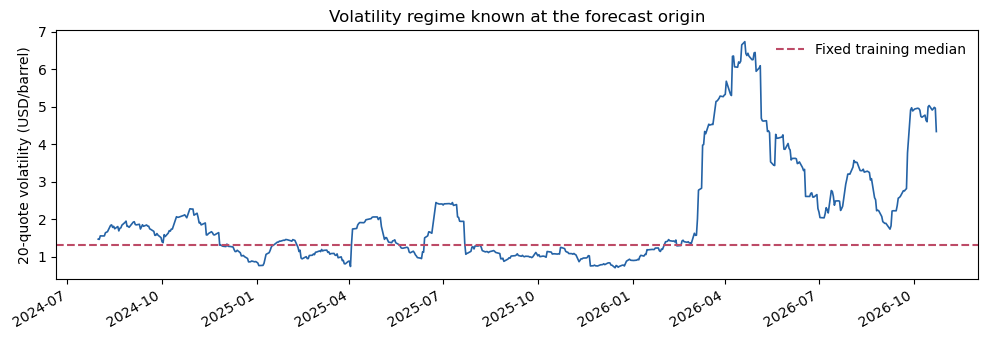

Admitted using initial development information: 45 of 65


,field_id,name,transform,eligible,reason
0,F001,Brent_spot,diff,True,Complete fixed training history and declared t...
1,F002,US_Gulf_gasoline_spot,diff,True,Complete fixed training history and declared t...
2,F003,WTI_M1_futures,diff,True,Complete fixed training history and declared t...
3,F004,WTI_M2_futures,diff,True,Complete fixed training history and declared t...
4,F005,Broad_US_dollar_index,logreturn,True,Complete fixed training history and declared t...
...,...,...,...,...,...
60,F067,US_Baa_Treasury_10Y_spread,diff,True,Complete fixed training history and declared t...
61,F068,SG_crude_imports_daily_average,diff,True,Complete fixed training history and declared t...
62,F074,US_crude_net_imports,diff,True,Complete fixed training history and declared t...
63,F075,US_SPR_stocks,diff,True,Complete fixed training history and declared t...


In [13]:
cfg["CODE_VERSION"] = "82bc8f4ca6f3e816b745ec8cb1f2bf6ab88fd100460f25af9e5db6893abbb3ae"
cfg["FACTOR_CODE_SHA"] = "eece48ac8605b01c72030cf43d1071962d98ec9e512f9385478a349c39261c2a"

raw, field_metadata = load_existing_oil_data(DATA_SOURCE)
print("Read", len(raw), "quote dates and", len(field_metadata), "candidate factors plus WTI.")
admission_cfg = dict(cfg)
admission_cfg["VAL_START"] = str((pd.Timestamp(cfg["ML_SELECTION_END"]) + pd.Timedelta(days=1)).date())
pool_panel, eligible_fields, field_audit, transform_map = prepare_feature_pool(
    raw, field_metadata, admission_cfg, OUTPUT_DIR / "00_field_audit")
cfg["TRANSFORMS"] = transform_map
panel, regimes, regime_threshold = prepare_data(raw, cfg, OUTPUT_DIR)
assert panel.index.equals(pool_panel.index)
print("Admitted using initial development information:", len(eligible_fields), "of", len(field_metadata))
display(field_audit[["field_id","name","transform","eligible","reason"]])
export_table(pd.DataFrame([{"package":p,"version":metadata.version(p)} for p in requirements]), OUTPUT_DIR / "00_data" / "runtime_versions.csv")

#### Order Check

In [14]:
%run -i "WTI_Order_Selection_Addon.py"

# Compare VAR orders p = 1,...,10.
# VARX and its reference-VAR labels share the selected order.
var_order_selection = select_wti_var_order(globals())

,p,eligible,mean_window_BIC,mean_window_AIC,maximum_companion_radius,successful_windows,reason,rank
0,3,True,1.076712,0.984075,0.623905,2,eligible,1
1,4,True,1.094494,0.975389,0.661615,2,eligible,2
2,5,True,1.123275,0.977702,0.665049,2,eligible,3
3,2,True,1.128107,1.061938,0.331998,2,eligible,4
4,6,True,1.158140,0.986100,0.666995,2,eligible,5
5,7,True,1.191433,0.992925,0.728050,2,eligible,6
6,8,True,1.222175,0.997199,0.792489,2,eligible,7
7,9,True,1.253941,1.002498,0.809055,2,eligible,8
8,10,True,1.289758,1.011846,0.799255,2,eligible,9
9,1,True,1.537050,1.497348,0.073030,2,eligible,10


Order-selection tables: D:\Study\NUS Documentation\Coursework\2026 Semester 1\QF5210\Group project\WTI_Independent_ML_Results\00_order_selection
Selected VAR(3); VARX and its causal reference-VAR labels use the same p.
Applied to cfg.


## 3. Independent XGBoost input selection

The input-screening policy follows the supplied reference script: retain every admitted nonannual field for which at least one of four Pearson correlations has absolute value at least 0.1. The four quantities are `Corr(X(s), P(s))`, `Corr(X(s), P(s+5))`, `Corr(X(s), P(s+10))`, and `Corr(X(s), log(P(s+10)/P(s)))`. Log-return pairs require positive prices. All price and field data are truncated at `ML_SELECTION_END` **before** the forward shifts, so the screen cannot use later outcomes. Admission and current availability are assessed at that initial-development cutoff.

All passing fields form the **candidate pool** (42 in the current supplied data). For each model target separately, a univariate-field XGBoost uses that field's past 1–5 semantic-state values. Every field receives the same declared base tree settings, chronological folds, Rolling500/Expanding windows and target dates. Rank by the average fold/window RMSE relative to the zero-signal predictor; lower is better. The **12 eligible fields with lowest individual CV error** are selected, with field ID as the deterministic tie-breaker. Insufficient eligible fields raises an explicit error; there is no fallback to fewer than 12 inputs.

The selected 12 fields then enter **one joint XGBoost generator**. For each separate target, compare the reference script's four parameter profiles: original, shallow regularized, medium regularized and low variance, using the same chronological fold/window score. A fitted-mean predictor is also reported. There is no subsequent pruning or return to the complete 42-field input set. The complete field ranking, individual fold losses, selected 12-field lists and joint-model parameter losses are exported. This ranks individual predictive performance; it does not claim the globally optimal joint subset of 12 among all possible combinations. These are development selection scores, not an untouched performance test; no improvement over RW is imposed.

This version adds the requested **ML performance-based selection of 12 fields** to the reference-style candidate screen. It retains the existing recursive-60 model and 1–5 past-quote semantic inputs rather than copying the reference's direct h=1–23 design. All correlation screening, field ranking and parameter selection stay within the initial development prefix. Main validation and test outcomes do not influence these field choices.

Each downstream model receives **one scalar column generated jointly from its 12 selected fields**, not 12 columns. The two generators independently select fields, learn parameters and generate factor paths. Latest-origin fit details separately record selected inputs and fields actually used in tree splits; an input need not be used in every fitted tree model.

The reference VAR uses only data preceding each label, with a minimum of 250 equation targets and at most 500. Its residual labels become available only after their WTI targets are observed.

In [15]:
states, factor_targets, reference_log = make_factor_inputs(panel, eligible_fields, transform_map, cfg)
export_table(reference_log.reset_index(), OUTPUT_DIR / "01_ml_selection" / "causal_reference_VAR_labels.csv")
ml_choices, ml_selection_report = select_ml_factors(
    states, factor_targets, eligible_fields, field_metadata, cfg, OUTPUT_DIR / "01_ml_selection", raw_panel=panel)
cfg["ML_CHOICES"] = ml_choices
cfg["FEATURE_FREEZE_DATE"] = str(max(pd.Timestamp(v["selection_cutoff"]) for v in ml_choices.values()).date())
cfg["FS_VAL_END"] = cfg["FEATURE_FREEZE_DATE"]
first_test = np.flatnonzero(panel.index >= pd.Timestamp(cfg["TEST_START"]))[0]
cfg["EARLIEST_TEST_ORIGIN"] = str(panel.index[first_test - cfg["H"]].date())
assert pd.Timestamp(cfg["FEATURE_FREEZE_DATE"]) < pd.Timestamp(cfg["EARLIEST_TEST_ORIGIN"])
for family in ("Hybrid", "VARX"):
    assert len(ml_choices[family]["fields"]) == cfg["ML_KEEP_FIELDS"]
    print(family, "joint generator input fields:", ml_choices[family]["fields"],
          "->", ml_choices[family]["factor_name"], "(one scalar column)")
display(ml_selection_report["summary"])
display(ml_selection_report["field_ranking"].loc[lambda x:x.selected,
        ["family","rank","field_id","name","cv_RMSE_to_zero"]])
print("All candidate rankings, field-level fold losses and joint-model CV tables: 01_ml_selection/")

Hybrid: ranking all 42 candidate fields by chronological XGBoost prediction error; retaining exactly 12.
Hybrid: ranked 42/42 fields.
Hybrid: selected 12 fields jointly | original | CV RMSE/zero=1.019649
Hybrid: selected 12 fields jointly | shallow_regularized | CV RMSE/zero=1.018338
Hybrid: selected 12 fields jointly | medium_regularized | CV RMSE/zero=1.026154
Hybrid: selected 12 fields jointly | low_variance | CV RMSE/zero=1.010626
Hybrid: selected exactly 12 fields ['F029', 'F074', 'F075', 'F019', 'F017', 'F044', 'F028', 'F047', 'F045', 'F021', 'F030', 'F031'] -> ONE scalar X_ARIMAX | elapsed 3.5s
VARX: ranking all 42 candidate fields by chronological XGBoost prediction error; retaining exactly 12.
VARX: ranked 42/42 fields.
VARX: selected 12 fields jointly | original | CV RMSE/zero=1.021399
VARX: selected 12 fields jointly | shallow_regularized | CV RMSE/zero=1.020516
VARX: selected 12 fields jointly | medium_regularized | CV RMSE/zero=1.032593
VARX: selected 12 fields jointly | l

,family,factor,parameter_set,fields,n_candidate_fields,n_fields,n_inputs,n_output_factors,n_parameter_candidates,cv_RMSE_to_zero,cv_RMSE_to_mean,beats_zero_baseline,selection_cutoff,status
0,Hybrid,X_ARIMAX,low_variance,F029|F074|F075|F019|F017|F044|F028|F047|F045|F...,42,12,60,1,4,1.010626,1.009752,False,2013-12-31,top-field ML factor retained; benchmark advant...
1,VARX,X_VARX,low_variance,F047|F028|F075|F074|F053|F019|F029|F068|F065|F...,42,12,60,1,4,1.009970,1.007939,False,2013-12-31,top-field ML factor retained; benchmark advant...


,family,rank,field_id,name,cv_RMSE_to_zero
0,Hybrid,1,F029,SG_refining_IIP_SA,0.998275
1,Hybrid,2,F074,US_crude_net_imports,1.002290
2,Hybrid,3,F075,US_SPR_stocks,1.003370
3,Hybrid,4,F019,SP500,1.004101
4,Hybrid,5,F017,US_refinery_utilization,1.004945
5,Hybrid,6,F044,Copper_monthly,1.005432
6,Hybrid,7,F028,SG_petroleum_reexport_share,1.005573
7,Hybrid,8,F047,OPECplus_crude_production,1.005673
8,Hybrid,9,F045,Iron_ore_monthly,1.006213
9,Hybrid,10,F021,US_5Y_breakeven_inflation,1.006968


All candidate rankings, field-level fold losses and joint-model CV tables: 01_ml_selection/


## 4. Forward cross-fitted historical scalar factors

After field selection is frozen, each generator is refitted every 20 quotes. For each historical target, its factor comes from a model trained on earlier target labels, using input states from earlier quotes. The factors used to fit the mean models are therefore predictions rather than in-sample ML fitted values. Rolling500 and Expanding maintain separate generator histories while sharing that family's selected inputs.

Unknown future auxiliary field states are separately forecast recursively by XGBoost. At a new origin, the factor generator is fitted on the origin's available labels and applied to the observed/predicted lag states for all 60 steps. This supporting state forecast makes the multi-step factor path feasible without inserting future actual inputs. Supporting state models retain the declared base tree settings; the scalar generator uses its independently CV-selected profile.

A supporting Rolling500 state model uses that field's last 500 **observed target labels** through the origin; its actual first/last label dates and label age are reported. This permits a previously admitted field that later stops reporting to remain an explicit forecast input without using future availability to revise the frozen field list. Its future values are hypothetical ML continuations from older observations, not refreshed source observations. Expanding uses all past observed labels. These supporting histories can span more than 500 calendar quotes; the mean model's exact 500 equation targets and the scalar generator's own rolling target policy are unchanged.

Original missing values stay missing. XGBoost uses native missing routing; no backward filling is added. Insufficient label/state history remains an explicit failure. Provenance and missing-input counts are exported.

OOF VARX | Rolling500: block 1/160 | elapsed 0.1s
OOF VARX | Rolling500: block 50/160 | elapsed 2.5s
OOF VARX | Rolling500: block 100/160 | elapsed 4.9s
OOF VARX | Rolling500: block 150/160 | elapsed 7.6s
OOF VARX | Rolling500: block 160/160 | elapsed 8.2s
OOF VARX | Expanding: block 1/160 | elapsed 0.1s
OOF VARX | Expanding: block 50/160 | elapsed 5.0s
OOF VARX | Expanding: block 100/160 | elapsed 12.2s
OOF VARX | Expanding: block 150/160 | elapsed 21.5s
OOF VARX | Expanding: block 160/160 | elapsed 23.6s
Common mean-model equation start: 2014-01-02


,family,window,factor_name,fields,lags,selection_cutoff,first_oof_target,last_oof_target,n_oof,failed_blocks,refit_every_quotes,minimum_train,native_missing_feature_rows
0,Hybrid,Rolling500,X_ARIMAX,F029 | F074 | F075 | F019 | F017 | F044 | F028...,1 | 2 | 3 | 4 | 5,2013-12-31,2014-01-02,2026-10-23,3197,0,20,250,130
1,Hybrid,Expanding,X_ARIMAX,F029 | F074 | F075 | F019 | F017 | F044 | F028...,1 | 2 | 3 | 4 | 5,2013-12-31,2014-01-02,2026-10-23,3197,0,20,250,130
2,VARX,Rolling500,X_VARX,F047 | F028 | F075 | F074 | F053 | F019 | F029...,1 | 2 | 3 | 4 | 5,2013-12-31,2014-01-02,2026-10-23,3197,0,20,250,130
3,VARX,Expanding,X_VARX,F047 | F028 | F075 | F074 | F053 | F019 | F029...,1 | 2 | 3 | 4 | 5,2013-12-31,2014-01-02,2026-10-23,3197,0,20,250,130


Selected predictor availability (source gaps are retained, not filled):


,generator,field,name,last_nonmissing_quote,missing_last_500_quotes,latest_value_available
0,Hybrid,F029,SG_refining_IIP_SA,2026-04-17,131,False
1,Hybrid,F074,US_crude_net_imports,2026-10-23,0,True
2,Hybrid,F075,US_SPR_stocks,2026-10-23,0,True
3,Hybrid,F019,SP500,2026-10-23,0,True
4,Hybrid,F017,US_refinery_utilization,2026-10-23,0,True
5,Hybrid,F044,Copper_monthly,2026-10-23,0,True
6,Hybrid,F028,SG_petroleum_reexport_share,2026-10-23,0,True
7,Hybrid,F047,OPECplus_crude_production,2026-10-23,0,True
8,Hybrid,F045,Iron_ore_monthly,2026-10-23,0,True
9,Hybrid,F021,US_5Y_breakeven_inflation,2026-10-23,0,True


,model_family,effective_mean_model,endogenous_fields,external_fields,ML_input_fields,note
0,VAR,VAR(3) on WTI and Brent changes,WTI | F001,none,none,Matched no-factor baseline for VARX.
1,VARX,VARX(3) + one independent ML factor,WTI | F001,X_VARX,F047 | F028 | F075 | F074 | F053 | F019 | F029...,XGBoost learns causal reference-VAR WTI residu...
2,Hybrid,"ARIMAX(1,0,1) on WTI changes + one independent...",WTI,X_ARIMAX,F029 | F074 | F075 | F019 | F017 | F044 | F028...,XGBoost learns next-quote WTI changes; histori...
3,ARIMA,"ARMA(1,1) on WTI changes",WTI,none,none,"Explicit no-factor baseline, separate from the..."
4,RW,Zero-drift Random Walk,WTI,none,NaN,Flat point path; GARCH supplies conditional un...


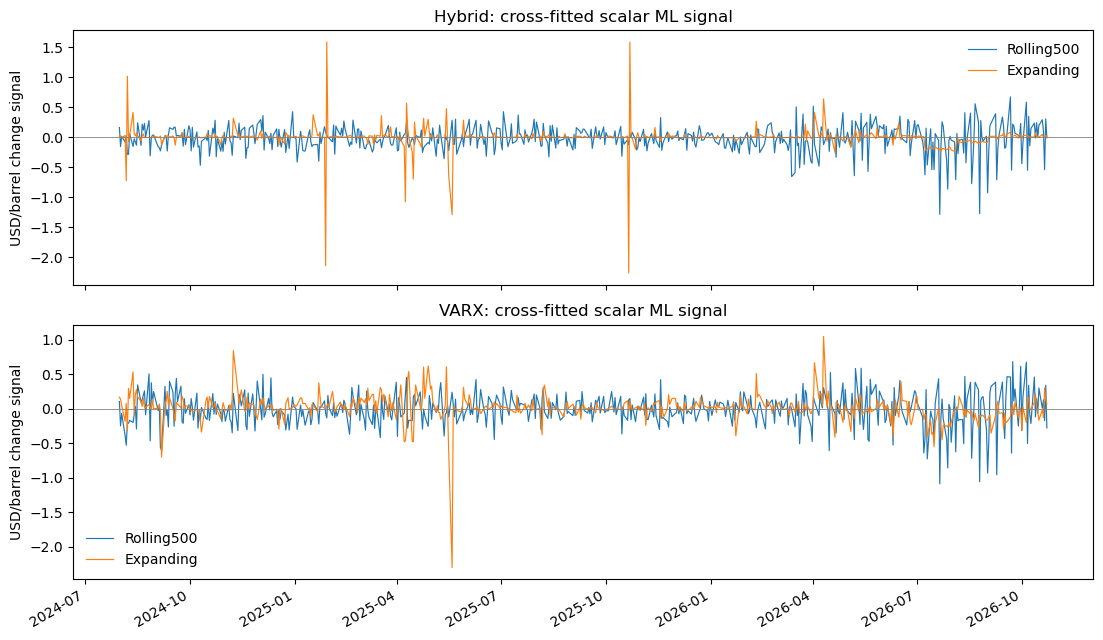

Matched mean-equation start: 2014-01-02
ML field choices and all factor model fits precede the dates whose signals they generate.


In [16]:
factor_store = build_factor_store(states, factor_targets, ml_choices, cfg, OUTPUT_DIR / "02_ml_factors")
assert pd.Timestamp(cfg["MEAN_START"]) > pd.Timestamp(cfg["FEATURE_FREEZE_DATE"])
history_audit = pd.read_csv(OUTPUT_DIR / "02_ml_factors" / "factor_history_audit.csv")
display(history_audit.drop(columns=["signature"]))
cfg["FACTOR_STORE_FINGERPRINT"] = {f"{k[0]} | {k[1]}":v for k,v in factor_store["signatures"].items()}
selected_input_status = []
name_lookup = field_metadata.set_index("field_id")["name"].to_dict()
for family, choice in ml_choices.items():
    for field in choice["fields"]:
        values = panel[field]
        selected_input_status.append({"generator":family,"field":field,"name":name_lookup.get(field,field),
            "last_nonmissing_quote":values.last_valid_index(),
            "missing_last_500_quotes":int(values.tail(cfg["ROLLING_WINDOW"]).isna().sum()),
            "latest_value_available":bool(pd.notna(values.iloc[-1]))})
selected_input_status = pd.DataFrame(selected_input_status)
export_table(selected_input_status, OUTPUT_DIR / "02_ml_factors" / "selected_input_availability.csv")
print("Selected predictor availability (source gaps are retained, not filled):")
display(selected_input_status)
export_table(describe_mean_specifications(cfg), OUTPUT_DIR / "model_specifications.csv")
display(describe_mean_specifications(cfg))
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for ax, family in zip(axes, ("Hybrid", "VARX")):
    for window in ("Rolling500", "Expanding"):
        s = factor_store["oof"][(family, window)]["factor"].loc[cfg["VAL_START"]:]
        ax.plot(s.index, s, lw=0.85, label=window)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(f"{family}: cross-fitted scalar ML signal")
    ax.set_ylabel("USD/barrel change signal")
    ax.legend(frameon=False)
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_ml_factors" / "historical_scalar_factors.png", dpi=150)
if cfg["SHOW_PLOTS"]: plt.show()
plt.close(fig)
print("Matched mean-equation start:", cfg["MEAN_START"])
print("ML field choices and all factor model fits precede the dates whose signals they generate.")

In [17]:
# Compare ARIMAX p,q = 0,...,3 using historical X_ARIMAX.
# d=0 because WTI has already been differenced once.
arimax_order_selection = select_wti_arimax_order(globals())

ARIMAX order scan 1/32: (0,0,0) | Rolling500 | ok
ARIMAX order scan 2/32: (0,0,0) | Expanding | ok
ARIMAX order scan 3/32: (0,0,1) | Rolling500 | ok
ARIMAX order scan 4/32: (0,0,1) | Expanding | ok
ARIMAX order scan 5/32: (0,0,2) | Rolling500 | ok
ARIMAX order scan 6/32: (0,0,2) | Expanding | ok
ARIMAX order scan 7/32: (0,0,3) | Rolling500 | ok
ARIMAX order scan 8/32: (0,0,3) | Expanding | ok
ARIMAX order scan 9/32: (1,0,0) | Rolling500 | ok
ARIMAX order scan 10/32: (1,0,0) | Expanding | ok
ARIMAX order scan 11/32: (1,0,1) | Rolling500 | ok
ARIMAX order scan 12/32: (1,0,1) | Expanding | ok
ARIMAX order scan 13/32: (1,0,2) | Rolling500 | ok
ARIMAX order scan 14/32: (1,0,2) | Expanding | ok
ARIMAX order scan 15/32: (1,0,3) | Rolling500 | ok
ARIMAX order scan 16/32: (1,0,3) | Expanding | ok
ARIMAX order scan 17/32: (2,0,0) | Rolling500 | ok
ARIMAX order scan 18/32: (2,0,0) | Expanding | ok
ARIMAX order scan 19/32: (2,0,1) | Rolling500 | ok
ARIMAX order scan 20/32: (2,0,1) | Expanding | ok

,p,d,q,eligible,mean_BIC_per_observation,complexity,successful_windows,reason,rank
0,0,0,1,True,2.843707,1,2,eligible,1
1,1,0,0,True,2.846588,1,2,eligible,2
2,1,0,1,True,2.847809,2,2,eligible,3
3,0,0,2,True,2.848308,2,2,eligible,4
4,2,0,0,True,2.849161,2,2,eligible,5
5,0,0,3,True,2.850515,3,2,eligible,6
6,2,0,1,True,2.851067,3,2,eligible,7
7,1,0,2,True,2.851442,3,2,eligible,8
8,3,0,0,True,2.851747,3,2,eligible,9
9,1,0,3,True,2.858022,4,2,eligible,10


Order-selection tables: D:\Study\NUS Documentation\Coursework\2026 Semester 1\QF5210\Group project\WTI_Independent_ML_Results\00_order_selection
Selected ARIMAX(0, 0, 1) on WTI changes + X_ARIMAX; the no-X ARIMA uses the same order.
Applied to cfg.


## 5. Full recursive mean paths and GARCH

The fixed genuine VAR backbone is WTI and Brent changes. VARX adds only `X_VARX`. Hybrid ARIMAX adds only `X_ARIMAX`. ARIMA is an explicit no-factor ablation, with the same WTI-change equation and matched mean history. Every ML-labelled model always invokes its nonempty factor generator; failure is reported rather than replaced with a baseline.

For every origin, all models generate 60 steps from that origin's information. Actual future quotes are used only later for scoring. GARCH is fitted to each mean model's residuals. Price uncertainty propagates cumulative mean-model impulse responses, and combinations preserve fitted residual cross-correlation. The bands condition on the forecast factor paths.

In [33]:
predictions, fit_log, payloads = fit_origins(panel, regimes, cfg, OUTPUT_DIR)
assert predictions.groupby(["model","origin_date"]).size().eq(cfg["H"]).all()
print("Every stored model/origin has all 60 path positions, including explicit NaNs for failures.")
display(predictions.loc[predictions.model.eq("RW") & predictions.split.eq("test")]
        .groupby("horizon").size().reindex(cfg["KEY_HORIZONS"]).rename("Test targets").to_frame())
latest_ml_usage = []
latest_fit_rows = fit_log.loc[fit_log.origin_date.eq(panel.index[-1]) & fit_log.status.eq("ok")]
for row in latest_fit_rows.itertuples():
    if not row.model.startswith(("Hybrid |", "VARX |")):
        continue
    details = json.loads(row.details)
    latest_ml_usage.append({"model":row.model,
        "n_output_factors":details["generated_factor_count"],
        "n_selected_fields":details["factor_selected_field_count"],
        "n_active_split_fields":details["factor_active_split_field_count"],
        "selected_fields":" | ".join(details["factor_input_fields"]),
        "active_split_fields":" | ".join(details["factor_active_split_fields"])})
latest_ml_usage = pd.DataFrame(latest_ml_usage)
export_table(latest_ml_usage, OUTPUT_DIR / "02_ml_factors" / "latest_generator_field_usage.csv")
print("Latest scalar-generator fits: selected inputs versus fields actually used in tree splits")
display(latest_ml_usage)
print("Split usage is a fit diagnostic; it does not establish causal effects or an improvement over RW.")

Origins 1/557 | 2024-07-31 | 9/9 fitted | elapsed 0.0 min
Origins 10/557 | 2024-08-13 | 9/9 fitted | elapsed 0.5 min
Origins 20/557 | 2024-08-27 | 9/9 fitted | elapsed 1.0 min
Origins 30/557 | 2024-09-11 | 9/9 fitted | elapsed 1.5 min
Origins 40/557 | 2024-09-25 | 9/9 fitted | elapsed 2.0 min
Origins 50/557 | 2024-10-09 | 9/9 fitted | elapsed 2.5 min
Origins 60/557 | 2024-10-24 | 9/9 fitted | elapsed 3.0 min
Origins 70/557 | 2024-11-07 | 9/9 fitted | elapsed 3.5 min
Origins 80/557 | 2024-11-22 | 9/9 fitted | elapsed 4.0 min
Origins 90/557 | 2024-12-09 | 9/9 fitted | elapsed 4.5 min
Origins 100/557 | 2024-12-23 | 9/9 fitted | elapsed 5.0 min
Origins 110/557 | 2025-01-08 | 9/9 fitted | elapsed 5.5 min
Origins 120/557 | 2025-01-24 | 9/9 fitted | elapsed 6.0 min
Origins 130/557 | 2025-02-07 | 9/9 fitted | elapsed 6.5 min
Origins 140/557 | 2025-02-24 | 9/9 fitted | elapsed 7.0 min
Origins 150/557 | 2025-03-10 | 9/9 fitted | elapsed 7.5 min
Origins 160/557 | 2025-03-24 | 9/9 fitted | elapsed

,model,status,N_origins
0,ARIMA | Expanding,ok,557
1,ARIMA | Rolling500,ok,557
2,Hybrid | Expanding,ok,557
3,Hybrid | Rolling500,ok,557
4,RW,ok,557
5,VAR | Expanding,ok,557
6,VAR | Rolling500,ok,557
7,VARX | Expanding,ok,557
8,VARX | Rolling500,ok,557


Every stored model/origin has all 60 path positions, including explicit NaNs for failures.


,Test targets
horizon,
1,17
5,17
20,17
60,17


Latest scalar-generator fits: selected inputs versus fields actually used in tree splits


,model,n_output_factors,n_selected_fields,n_active_split_fields,selected_fields,active_split_fields
0,VARX | Rolling500,1,12,4,F047 | F028 | F074 | F019 | F075 | F053 | F029...,F074 | F019 | F075 | F065
1,VARX | Expanding,1,12,9,F047 | F028 | F074 | F019 | F075 | F053 | F029...,F028 | F074 | F019 | F075 | F053 | F029 | F044...
2,Hybrid | Rolling500,1,12,6,F029 | F074 | F075 | F019 | F017 | F044 | F028...,F029 | F074 | F075 | F019 | F017 | F021
3,Hybrid | Expanding,1,12,9,F029 | F074 | F075 | F019 | F017 | F044 | F028...,F029 | F074 | F075 | F019 | F017 | F044 | F028...


Split usage is a fit diagnostic; it does not establish causal effects or an improvement over RW.


## 6. Matched no-factor ablation

This section directly compares VARX against its matched VAR and ARIMAX against its matched ARIMA. Compact Overall tables are displayed here; the exported test and validation CSVs contain Overall, High and Low. Full regime tables and figures appear in the following window-comparison sections. This is where the incremental downstream value of each learned factor can be assessed; good factor CV performance alone does not establish improved oil-price forecasting.

In [34]:
for family, baseline in (("VARX","VAR"), ("Hybrid","ARIMA")):
    for window in ("Rolling500", "Expanding"):
        models = [f"{baseline} | {window}", f"{family} | {window}", "RW"]
        folder = OUTPUT_DIR / "03_factor_ablation" / f"{family}_{window}"
        for split in ("test", "validation"):
            m = paired_metrics(predictions, models, split=split, key_horizons=cfg["KEY_HORIZONS"])
            export_table(m, folder / f"{split}_metrics.csv")
            focus = m.loc[m.regime.eq("Overall") & m.horizon.isin(cfg["KEY_HORIZONS"]),
                          ["model","horizon","N","N_expected","RMSE","MAPE","MAE","Coverage95","Width95","status"]]
            print(f"{family} factor ablation | {window} | {split.upper()}")
            display(focus.round(4).reset_index(drop=True))

VARX factor ablation | Rolling500 | TEST


,model,horizon,N,N_expected,RMSE,MAPE,MAE,Coverage95,Width95,status
0,VAR | Rolling500,1,17,17,3.2086,2.3749,2.4480,94.1176,16.6157,ok
1,VARX | Rolling500,1,17,17,3.1740,2.3522,2.4286,94.1176,16.3285,ok
2,RW,1,17,17,3.2174,2.3974,2.4624,94.1176,17.0258,ok
3,VAR | Rolling500,5,17,17,6.5946,4.5156,4.6871,100.0000,38.2956,ok
4,VARX | Rolling500,5,17,17,6.5994,4.6183,4.7903,94.1176,37.6495,ok
5,RW,5,17,17,6.7346,4.5698,4.7471,100.0000,41.7187,ok
6,VAR | Rolling500,20,17,17,9.3685,7.4478,7.6219,100.0000,50.7953,ok
7,VARX | Rolling500,20,17,17,9.5188,7.5352,7.7198,100.0000,50.7220,ok
8,RW,20,17,17,9.4479,7.4943,7.7118,100.0000,51.7846,ok
9,VAR | Rolling500,60,17,17,19.1607,18.2597,18.4648,100.0000,83.3393,ok


VARX factor ablation | Rolling500 | VALIDATION


,model,horizon,N,N_expected,RMSE,MAPE,MAE,Coverage95,Width95,status
0,VAR | Rolling500,1,497,497,2.4255,1.9923,1.5254,94.1650,7.4702,ok
1,VARX | Rolling500,1,497,497,2.4287,1.9935,1.5269,94.1650,7.4624,ok
2,RW,1,497,497,2.3799,1.9678,1.5055,94.1650,7.5588,ok
3,VAR | Rolling500,5,493,493,5.1752,4.5630,3.5231,91.6836,15.8833,ok
4,VARX | Rolling500,5,493,493,5.1716,4.5567,3.5185,91.6836,15.8562,ok
5,RW,5,493,493,5.0967,4.5347,3.4906,93.1034,16.6978,ok
6,VAR | Rolling500,20,478,478,9.7833,8.0585,6.2470,93.0962,30.2458,ok
7,VARX | Rolling500,20,478,478,9.7708,8.0442,6.2324,92.6778,30.1815,ok
8,RW,20,478,478,9.5933,8.0362,6.2006,93.7238,32.5320,ok
9,VAR | Rolling500,60,438,438,17.3533,13.6961,11.0923,86.0731,47.1762,ok


VARX factor ablation | Expanding | TEST


,model,horizon,N,N_expected,RMSE,MAPE,MAE,Coverage95,Width95,status
0,VAR | Expanding,1,17,17,3.3311,2.4508,2.5308,94.1176,16.3204,ok
1,VARX | Expanding,1,17,17,3.3309,2.4506,2.5306,94.1176,16.3192,ok
2,RW,1,17,17,3.2174,2.3974,2.4624,94.1176,17.0258,ok
3,VAR | Expanding,5,17,17,6.5101,4.4299,4.6225,94.1176,31.8790,ok
4,VARX | Expanding,5,17,17,6.5102,4.4301,4.6227,94.1176,31.8780,ok
5,RW,5,17,17,6.7346,4.5698,4.7471,100.0000,41.7187,ok
6,VAR | Expanding,20,17,17,9.0114,7.2064,7.4080,100.0000,42.6450,ok
7,VARX | Expanding,20,17,17,9.0123,7.2070,7.4087,100.0000,42.6433,ok
8,RW,20,17,17,9.4479,7.4943,7.7118,100.0000,51.7846,ok
9,VAR | Expanding,60,17,17,19.5238,18.7482,18.9759,100.0000,76.4817,ok


... (6 outputs left out)

Hybrid factor ablation | Expanding | TEST


,model,horizon,N,N_expected,RMSE,MAPE,MAE,Coverage95,Width95,status
0,ARIMA | Expanding,1,17,17,3.3312,2.4738,2.5495,94.1176,16.3198,ok
1,Hybrid | Expanding,1,17,17,3.3312,2.4722,2.5480,94.1176,16.3208,ok
2,RW,1,17,17,3.2174,2.3974,2.4624,94.1176,17.0258,ok
3,ARIMA | Expanding,5,17,17,6.4545,4.4207,4.6166,94.1176,31.2773,ok
4,Hybrid | Expanding,5,17,17,6.4614,4.4251,4.6215,94.1176,31.2876,ok
5,RW,5,17,17,6.7346,4.5698,4.7471,100.0000,41.7187,ok
6,ARIMA | Expanding,20,17,17,8.7982,7.0415,7.2391,100.0000,40.7610,ok
7,Hybrid | Expanding,20,17,17,8.8105,7.0483,7.2473,100.0000,40.7527,ok
8,RW,20,17,17,9.4479,7.4943,7.7118,100.0000,51.7846,ok
9,ARIMA | Expanding,60,17,17,19.6392,18.8919,19.1173,100.0000,73.8191,ok


Hybrid factor ablation | Expanding | VALIDATION


,model,horizon,N,N_expected,RMSE,MAPE,MAE,Coverage95,Width95,status
0,ARIMA | Expanding,1,497,497,2.4197,2.0126,1.5413,94.1650,8.0963,ok
1,Hybrid | Expanding,1,497,497,2.4198,2.0114,1.5405,94.1650,8.0959,ok
2,RW,1,497,497,2.3799,1.9678,1.5055,94.1650,7.5588,ok
3,ARIMA | Expanding,5,493,493,5.1454,4.5447,3.5083,91.4807,14.7651,ok
4,Hybrid | Expanding,5,493,493,5.1445,4.5454,3.5086,91.4807,14.7682,ok
5,RW,5,493,493,5.0967,4.5347,3.4906,93.1034,16.6978,ok
6,ARIMA | Expanding,20,478,478,9.6549,8.0114,6.1941,92.2594,27.9428,ok
7,Hybrid | Expanding,20,478,478,9.6509,8.0063,6.1904,92.2594,27.9569,ok
8,RW,20,478,478,9.5933,8.0362,6.2006,93.7238,32.5320,ok
9,ARIMA | Expanding,60,438,438,16.8143,13.3690,10.7871,86.5297,46.9700,ok


## 7. VAR versus ML-factor VARX and window selection

The original test-based model-selection sequence is retained. Independent ML field choices remain frozen; this section selects downstream windows and family only. Both model families remain visible in the ablation tables, even if the no-factor VAR wins.

Selected on TEST mean RMSE/RW at h=1,5,20,60: VAR | Rolling500.
Selected on TEST mean RMSE/RW at h=1,5,20,60: VARX | Rolling500.
Selected on TEST mean RMSE/RW at h=1,5,20,60: VARX | Rolling500.


,model,eligible,mean_RMSE_to_RW,minimum_common_coverage,minimum_own_coverage,minimum_N,reason,rank
0,VARX | Rolling500,True,0.988651,1.0,1.0,17,eligible,1
1,VAR | Rolling500,True,0.992710,1.0,1.0,17,eligible,2


Retained VAR family: VARX
VARX + GARCH: window comparison | Overall


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,RW,17,17,17,0,3.217,2.397,2.462,35.294,0.261,17,17,94.118,17.026,ok,ok
1,1,VARX | Expanding,17,17,17,0,3.331,2.451,2.531,64.706,0.646,17,17,94.118,16.319,ok,ok
2,1,VARX | Rolling500,17,17,17,0,3.174,2.352,2.429,58.824,0.582,17,17,94.118,16.328,ok,ok
3,5,RW,17,17,17,0,6.735,4.570,4.747,35.294,0.261,17,17,100.000,41.719,ok,ok
4,5,VARX | Expanding,17,17,17,0,6.510,4.430,4.623,52.941,0.528,17,17,94.118,31.878,ok,ok
5,5,VARX | Rolling500,17,17,17,0,6.599,4.618,4.790,52.941,0.485,17,17,94.118,37.650,ok,ok
6,20,RW,17,17,17,0,9.448,7.494,7.712,35.294,0.261,17,17,100.000,51.785,ok,ok
7,20,VARX | Expanding,17,17,17,0,9.012,7.207,7.409,64.706,0.636,17,17,100.000,42.643,ok,ok
8,20,VARX | Rolling500,17,17,17,0,9.519,7.535,7.720,64.706,0.393,17,17,100.000,50.722,ok,ok
9,60,RW,17,17,17,0,19.108,18.247,18.485,0.000,0.000,17,17,100.000,89.199,ok,ok


VARX + GARCH: window comparison | High


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,RW,17,17,17,0,3.217,2.397,2.462,35.294,0.261,17,17,94.118,17.026,ok,ok
1,1,VARX | Expanding,17,17,17,0,3.331,2.451,2.531,64.706,0.646,17,17,94.118,16.319,ok,ok
2,1,VARX | Rolling500,17,17,17,0,3.174,2.352,2.429,58.824,0.582,17,17,94.118,16.328,ok,ok
3,5,RW,17,17,17,0,6.735,4.570,4.747,35.294,0.261,17,17,100.000,41.719,ok,ok
4,5,VARX | Expanding,17,17,17,0,6.510,4.430,4.623,52.941,0.528,17,17,94.118,31.878,ok,ok
5,5,VARX | Rolling500,17,17,17,0,6.599,4.618,4.790,52.941,0.485,17,17,94.118,37.650,ok,ok
6,20,RW,17,17,17,0,9.448,7.494,7.712,35.294,0.261,17,17,100.000,51.785,ok,ok
7,20,VARX | Expanding,17,17,17,0,9.012,7.207,7.409,64.706,0.636,17,17,100.000,42.643,ok,ok
8,20,VARX | Rolling500,17,17,17,0,9.519,7.535,7.720,64.706,0.393,17,17,100.000,50.722,ok,ok
9,60,RW,17,17,17,0,19.108,18.247,18.485,0.000,0.000,17,17,100.000,89.199,ok,ok


VARX + GARCH: window comparison | Low


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
1,1,VARX | Expanding,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
2,1,VARX | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
3,5,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
4,5,VARX | Expanding,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
5,5,VARX | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
6,20,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
7,20,VARX | Expanding,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
8,20,VARX | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
9,60,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations


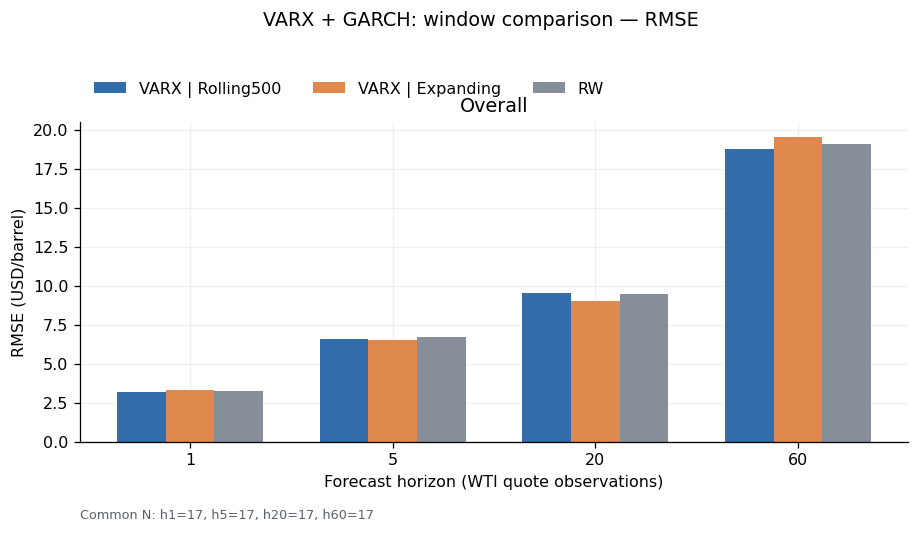

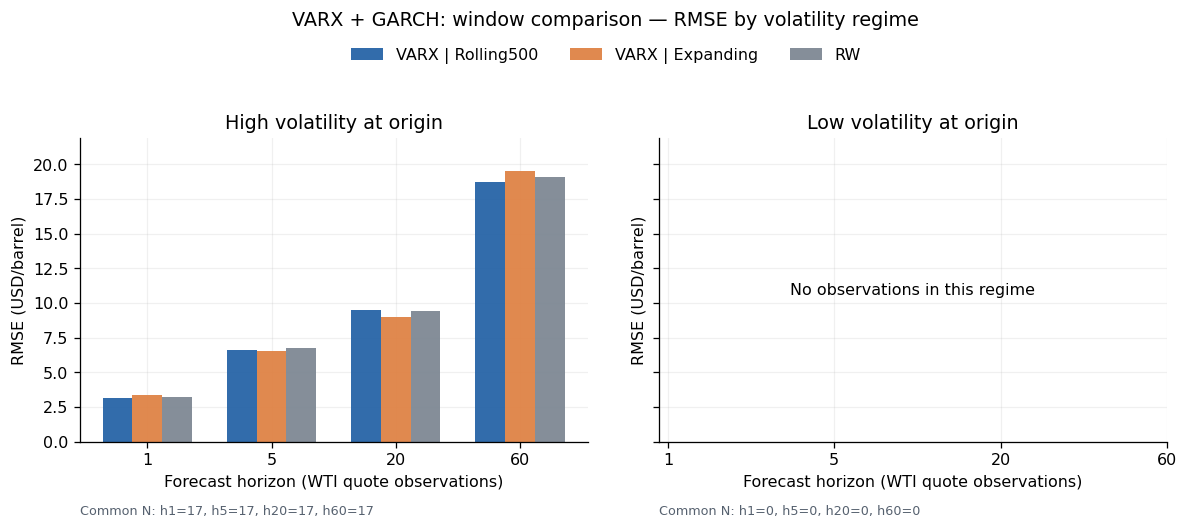

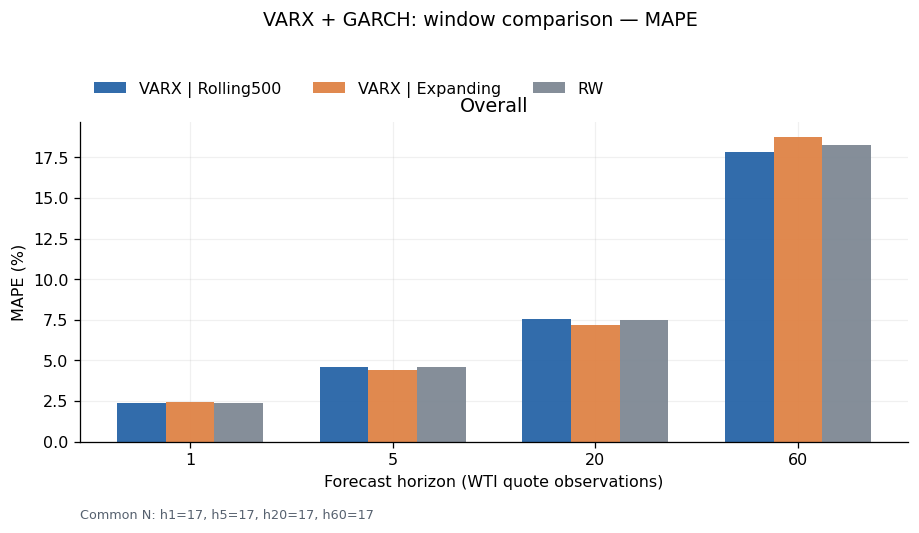

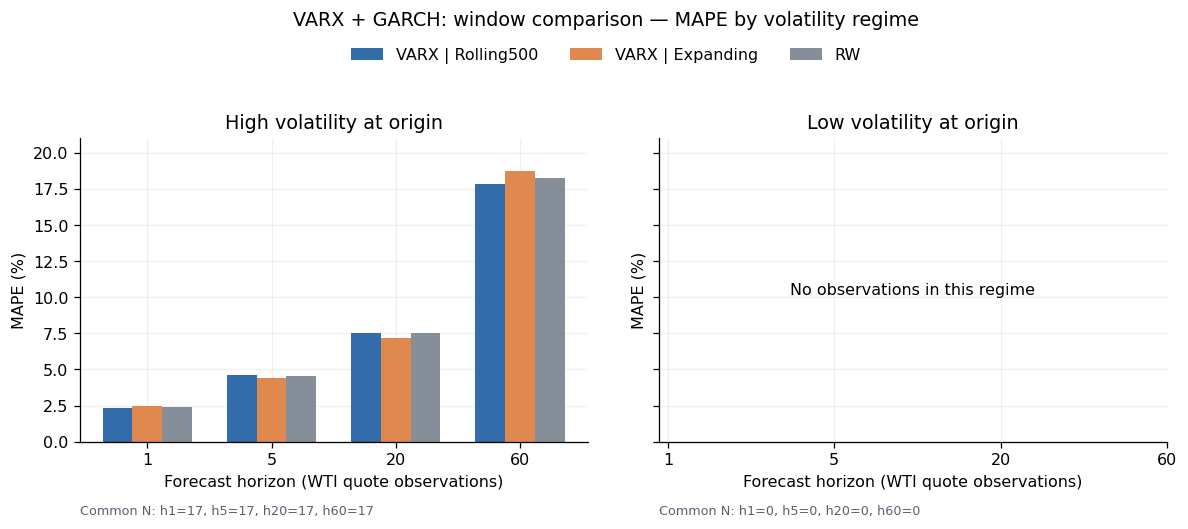

VARX + GARCH: window comparison | VALIDATION reference | Overall


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,RW,497,497,497,0,2.380,1.968,1.506,48.692,0.327,497,497,94.165,7.559,ok,ok
1,1,VARX | Expanding,497,497,497,0,2.416,2.001,1.531,52.515,0.525,497,497,93.763,8.067,ok,ok
2,1,VARX | Rolling500,497,497,497,0,2.429,1.993,1.527,48.491,0.483,497,497,94.165,7.462,ok,ok
3,5,RW,493,493,493,0,5.097,4.535,3.491,49.290,0.330,493,493,93.103,16.698,ok,ok
4,5,VARX | Expanding,493,493,493,0,5.142,4.548,3.510,51.116,0.509,493,493,91.886,15.045,ok,ok
5,5,VARX | Rolling500,493,493,493,0,5.172,4.557,3.518,49.493,0.477,493,493,91.684,15.856,ok,ok
6,20,RW,478,478,478,0,9.593,8.036,6.201,56.067,0.359,478,478,93.724,32.532,ok,ok
7,20,VARX | Expanding,478,478,478,0,9.648,8.012,6.195,51.255,0.460,478,478,92.469,29.238,ok,ok
8,20,VARX | Rolling500,478,478,478,0,9.771,8.044,6.232,50.837,0.476,478,478,92.678,30.182,ok,ok
9,60,RW,438,438,438,0,16.623,13.416,10.763,57.763,0.366,438,438,86.986,50.730,ok,ok


VARX + GARCH: window comparison | VALIDATION reference | High


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,RW,276,276,276,0,3.014,2.457,2.002,49.275,0.330,276,276,93.478,9.738,ok,ok
1,1,VARX | Expanding,276,276,276,0,3.061,2.500,2.036,51.812,0.518,276,276,92.754,10.705,ok,ok
2,1,VARX | Rolling500,276,276,276,0,3.082,2.498,2.036,48.913,0.489,276,276,93.116,9.584,ok,ok
3,5,RW,272,272,272,0,6.346,5.593,4.601,51.838,0.341,272,272,91.912,21.280,ok,ok
4,5,VARX | Expanding,272,272,272,0,6.414,5.640,4.647,50.735,0.504,272,272,92.279,19.950,ok,ok
5,5,VARX | Rolling500,272,272,272,0,6.462,5.661,4.666,49.632,0.490,272,272,90.441,20.105,ok,ok
6,20,RW,257,257,257,0,12.104,9.933,8.175,56.031,0.359,257,257,90.661,40.533,ok,ok
7,20,VARX | Expanding,257,257,257,0,12.186,9.935,8.187,49.416,0.473,257,257,89.494,38.699,ok,ok
8,20,VARX | Rolling500,257,257,257,0,12.385,10.152,8.352,42.023,0.413,257,257,88.716,37.714,ok,ok
9,60,RW,217,217,217,0,15.720,13.304,10.568,57.143,0.364,217,217,92.166,59.547,ok,ok


VARX + GARCH: window comparison | VALIDATION reference | Low


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,RW,221,221,221,0,1.179,1.357,0.886,47.964,0.324,221,221,95.023,4.838,ok,ok
1,1,VARX | Expanding,221,221,221,0,1.193,1.377,0.900,53.394,0.534,221,221,95.023,4.774,ok,ok
2,1,VARX | Rolling500,221,221,221,0,1.183,1.364,0.891,47.964,0.472,221,221,95.475,4.812,ok,ok
3,5,RW,221,221,221,0,2.895,3.232,2.124,46.154,0.316,221,221,94.570,11.058,ok,ok
4,5,VARX | Expanding,221,221,221,0,2.891,3.204,2.110,51.584,0.514,221,221,91.403,9.008,ok,ok
5,5,VARX | Rolling500,221,221,221,0,2.876,3.198,2.106,49.321,0.451,221,221,93.213,10.627,ok,ok
6,20,RW,221,221,221,0,5.357,5.831,3.904,56.109,0.359,221,221,97.285,23.228,ok,ok
7,20,VARX | Expanding,221,221,221,0,5.352,5.777,3.878,53.394,0.420,221,221,95.928,18.236,ok,ok
8,20,VARX | Rolling500,221,221,221,0,5.302,5.593,3.768,61.086,0.531,221,221,97.285,21.422,ok,ok
9,60,RW,221,221,221,0,17.465,13.525,10.954,58.371,0.369,221,221,81.900,42.073,ok,ok


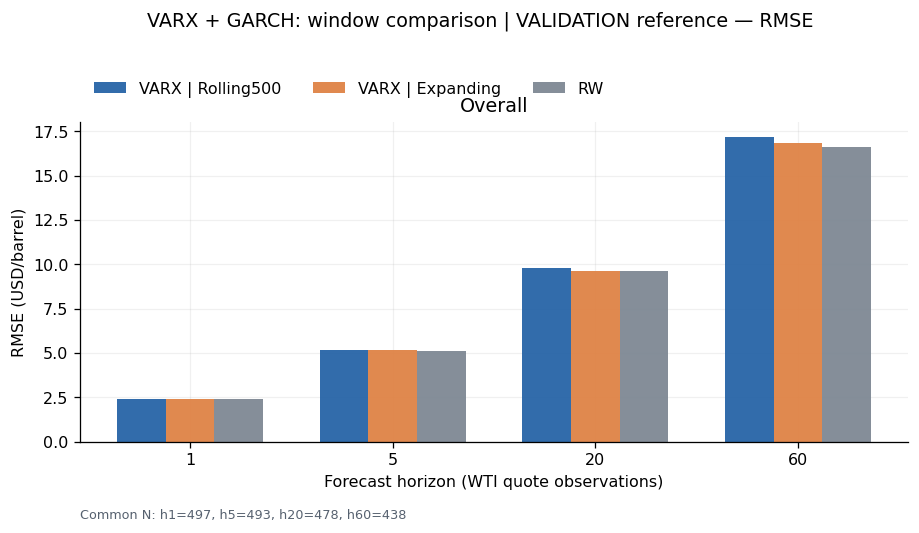

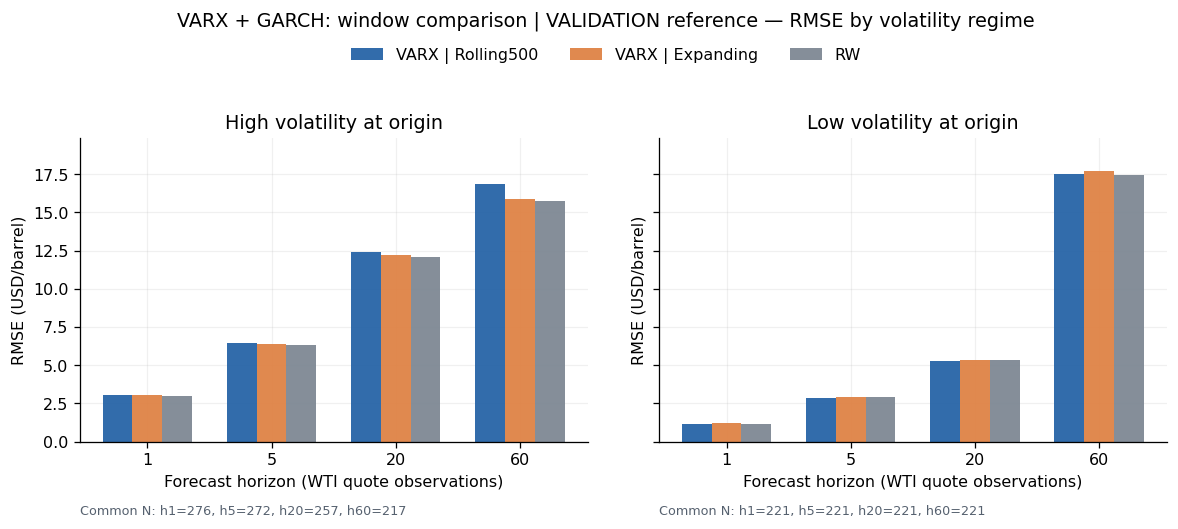

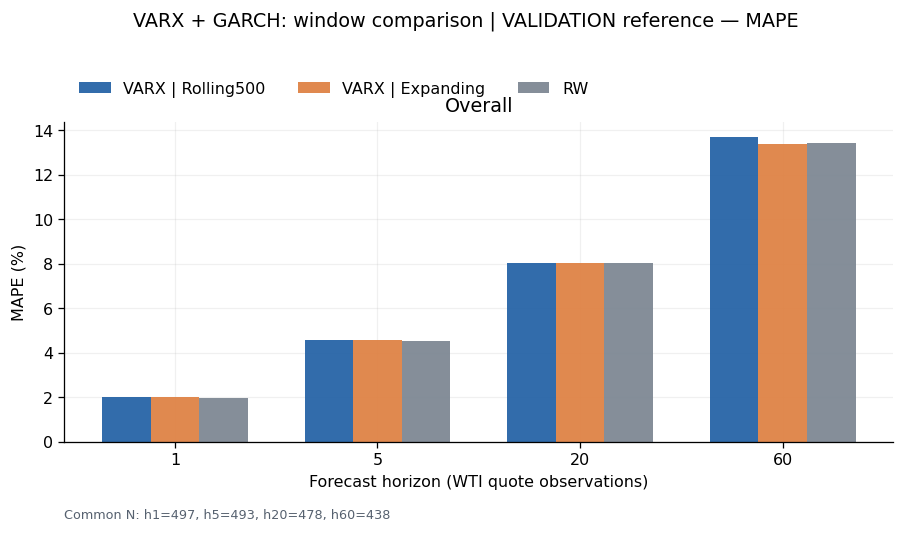

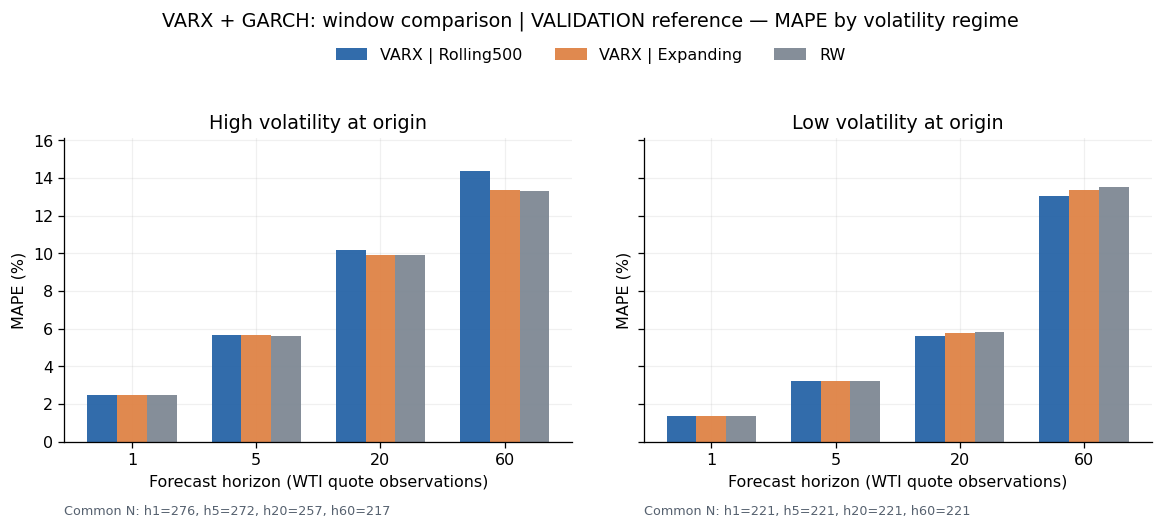

VALIDATION overall reference ranking of the same model set (does not change TEST selection):


,model,eligible,mean_RMSE_to_RW,minimum_common_coverage,minimum_own_coverage,minimum_N,reason,rank
0,RW,True,1.000000,1.0,1.0,438,eligible,1
1,VARX | Expanding,True,1.010492,1.0,1.0,438,eligible,2
2,VARX | Rolling500,True,1.021933,1.0,1.0,438,eligible,3


,model,eligible,mean_RMSE_to_RW,minimum_common_coverage,minimum_own_coverage,minimum_N,reason,rank
0,VARX | Rolling500,True,0.988651,1.0,1.0,17,eligible,1
1,VARX | Expanding,True,0.994786,1.0,1.0,17,eligible,2


Selected on TEST mean RMSE/RW at h=1,5,20,60: VARX | Rolling500.


In [35]:
screen = OUTPUT_DIR / "04_window_comparison" / "VAR_VARX_screen"
var_window, _, var_rank = compare_and_select(predictions, ["VAR | Rolling500","VAR | Expanding"], cfg, screen / "VAR", "VAR prescreen", present=False)
varx_window, _, varx_rank = compare_and_select(predictions, ["VARX | Rolling500","VARX | Expanding"], cfg, screen / "VARX", "ML-factor VARX prescreen", present=False)
selected_var, _, family_ranking = compare_and_select(predictions, [var_window,varx_window], cfg, screen / "family", "VAR versus ML-factor VARX", present=False)
VAR_FAMILY = selected_var.split(" | ")[0]
display(family_ranking)
print("Retained VAR family:", VAR_FAMILY)
var_best, var_metrics, var_ranking = compare_and_select(
    predictions, [f"{VAR_FAMILY} | Rolling500",f"{VAR_FAMILY} | Expanding"], cfg,
    OUTPUT_DIR / "04_window_comparison" / VAR_FAMILY,
    f"{VAR_FAMILY} + GARCH: window comparison")

## 8. ARIMAX with its independent ML factor: window comparison

Both windows use the ARIMAX generator's selected fields. They have separate cross-fitted factor histories and origin fits. Test plots appear first; validation Overall/High/Low figures and the validation reference ranking follow in the same section.

ARIMAX + independent XGBoost factor + GARCH | Overall


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,Hybrid | Expanding,17,17,17,0,3.331,2.472,2.548,52.941,0.514,17,17,94.118,16.321,ok,ok
1,1,Hybrid | Rolling500,17,17,17,0,3.231,2.408,2.481,58.824,0.588,17,17,94.118,16.603,ok,ok
2,1,RW,17,17,17,0,3.217,2.397,2.462,35.294,0.261,17,17,94.118,17.026,ok,ok
3,5,Hybrid | Expanding,17,17,17,0,6.461,4.425,4.621,52.941,0.528,17,17,94.118,31.288,ok,ok
4,5,Hybrid | Rolling500,17,17,17,0,6.738,4.719,4.913,52.941,0.528,17,17,94.118,37.230,ok,ok
5,5,RW,17,17,17,0,6.735,4.570,4.747,35.294,0.261,17,17,100.000,41.719,ok,ok
6,20,Hybrid | Expanding,17,17,17,0,8.810,7.048,7.247,64.706,0.646,17,17,100.000,40.753,ok,ok
7,20,Hybrid | Rolling500,17,17,17,0,9.253,7.108,7.343,47.059,0.440,17,17,100.000,44.468,ok,ok
8,20,RW,17,17,17,0,9.448,7.494,7.712,35.294,0.261,17,17,100.000,51.785,ok,ok
9,60,Hybrid | Expanding,17,17,17,0,19.703,18.957,19.184,11.765,0.105,17,17,100.000,73.674,ok,ok


ARIMAX + independent XGBoost factor + GARCH | High


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,Hybrid | Expanding,17,17,17,0,3.331,2.472,2.548,52.941,0.514,17,17,94.118,16.321,ok,ok
1,1,Hybrid | Rolling500,17,17,17,0,3.231,2.408,2.481,58.824,0.588,17,17,94.118,16.603,ok,ok
2,1,RW,17,17,17,0,3.217,2.397,2.462,35.294,0.261,17,17,94.118,17.026,ok,ok
3,5,Hybrid | Expanding,17,17,17,0,6.461,4.425,4.621,52.941,0.528,17,17,94.118,31.288,ok,ok
4,5,Hybrid | Rolling500,17,17,17,0,6.738,4.719,4.913,52.941,0.528,17,17,94.118,37.230,ok,ok
5,5,RW,17,17,17,0,6.735,4.570,4.747,35.294,0.261,17,17,100.000,41.719,ok,ok
6,20,Hybrid | Expanding,17,17,17,0,8.810,7.048,7.247,64.706,0.646,17,17,100.000,40.753,ok,ok
7,20,Hybrid | Rolling500,17,17,17,0,9.253,7.108,7.343,47.059,0.440,17,17,100.000,44.468,ok,ok
8,20,RW,17,17,17,0,9.448,7.494,7.712,35.294,0.261,17,17,100.000,51.785,ok,ok
9,60,Hybrid | Expanding,17,17,17,0,19.703,18.957,19.184,11.765,0.105,17,17,100.000,73.674,ok,ok


ARIMAX + independent XGBoost factor + GARCH | Low


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,Hybrid | Expanding,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
1,1,Hybrid | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
2,1,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
3,5,Hybrid | Expanding,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
4,5,Hybrid | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
5,5,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
6,20,Hybrid | Expanding,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
7,20,Hybrid | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
8,20,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
9,60,Hybrid | Expanding,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations


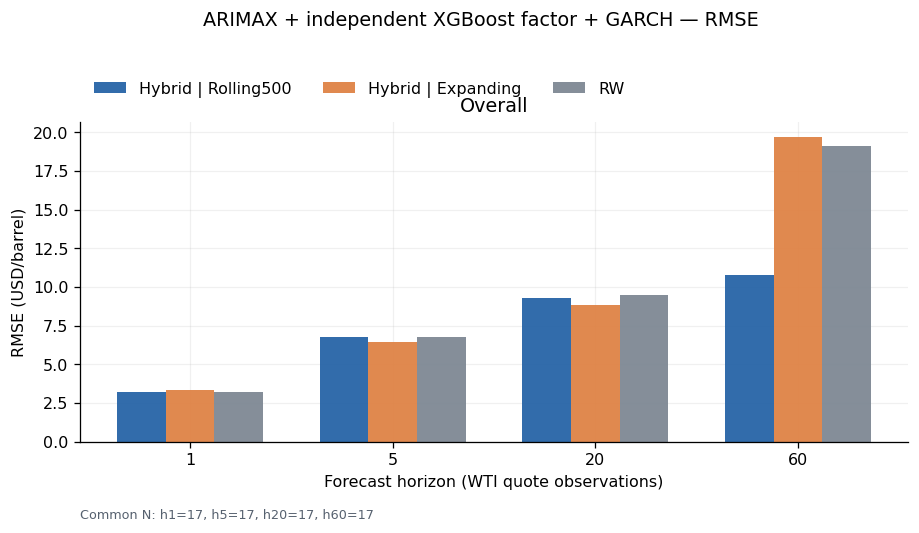

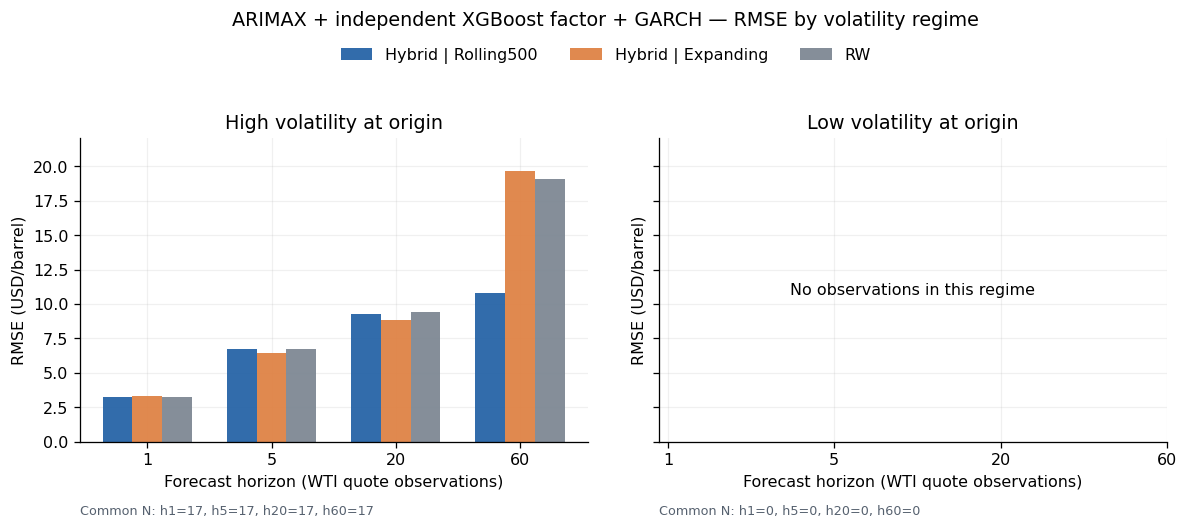

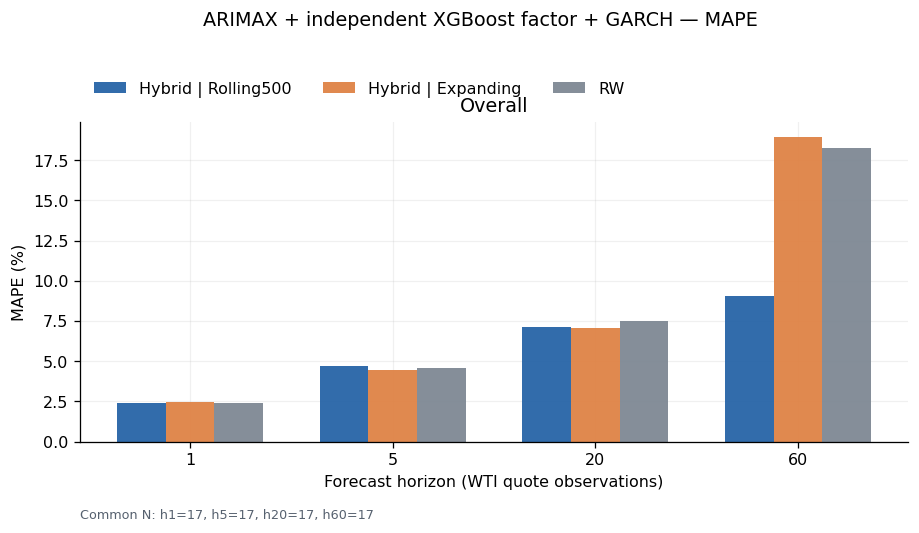

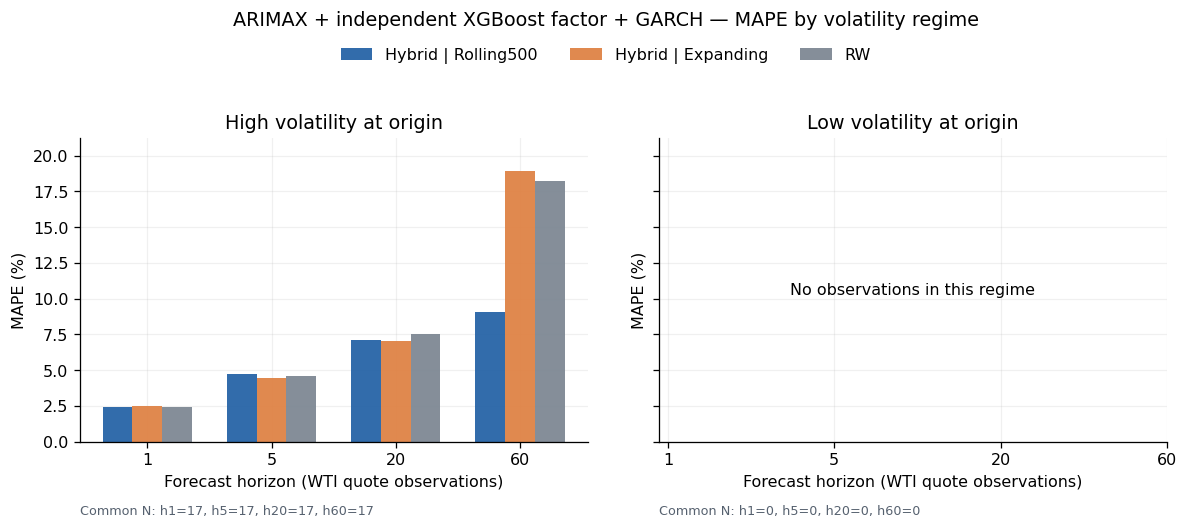

ARIMAX + independent XGBoost factor + GARCH | VALIDATION reference | Overall


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,Hybrid | Expanding,497,497,497,0,2.420,2.011,1.540,51.911,0.519,497,497,94.165,8.096,ok,ok
1,1,Hybrid | Rolling500,497,497,497,0,2.410,1.980,1.515,45.272,0.449,497,497,94.165,7.496,ok,ok
2,1,RW,497,497,497,0,2.380,1.968,1.506,48.692,0.327,497,497,94.165,7.559,ok,ok
3,5,Hybrid | Expanding,493,493,493,0,5.145,4.545,3.509,53.955,0.538,493,493,91.481,14.768,ok,ok
4,5,Hybrid | Rolling500,493,493,493,0,5.123,4.574,3.511,50.101,0.472,493,493,91.684,16.212,ok,ok
5,5,RW,493,493,493,0,5.097,4.535,3.491,49.290,0.330,493,493,93.103,16.698,ok,ok
6,20,Hybrid | Expanding,478,478,478,0,9.651,8.006,6.190,52.929,0.498,478,478,92.259,27.957,ok,ok
7,20,Hybrid | Rolling500,478,478,478,0,9.661,7.894,6.098,54.393,0.493,478,478,91.213,30.079,ok,ok
8,20,RW,478,478,478,0,9.593,8.036,6.201,56.067,0.359,478,478,93.724,32.532,ok,ok
9,60,Hybrid | Expanding,438,438,438,0,16.808,13.363,10.782,55.023,0.407,438,438,86.530,47.016,ok,ok


ARIMAX + independent XGBoost factor + GARCH | VALIDATION reference | High


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,Hybrid | Expanding,276,276,276,0,3.066,2.521,2.055,51.449,0.514,276,276,93.478,10.753,ok,ok
1,1,Hybrid | Rolling500,276,276,276,0,3.054,2.473,2.014,46.739,0.467,276,276,93.478,9.633,ok,ok
2,1,RW,276,276,276,0,3.014,2.457,2.002,49.275,0.330,276,276,93.478,9.738,ok,ok
3,5,Hybrid | Expanding,272,272,272,0,6.418,5.642,4.648,53.676,0.535,272,272,91.912,19.605,ok,ok
4,5,Hybrid | Rolling500,272,272,272,0,6.371,5.646,4.623,52.574,0.514,272,272,90.441,20.600,ok,ok
5,5,RW,272,272,272,0,6.346,5.593,4.601,51.838,0.341,272,272,91.912,21.280,ok,ok
6,20,Hybrid | Expanding,257,257,257,0,12.198,9.936,8.188,51.362,0.500,257,257,89.494,37.013,ok,ok
7,20,Hybrid | Rolling500,257,257,257,0,12.098,9.717,7.990,54.086,0.513,257,257,87.549,37.584,ok,ok
8,20,RW,257,257,257,0,12.104,9.933,8.175,56.031,0.359,257,257,90.661,40.533,ok,ok
9,60,Hybrid | Expanding,217,217,217,0,15.837,13.374,10.653,52.074,0.429,217,217,92.166,60.511,ok,ok


ARIMAX + independent XGBoost factor + GARCH | VALIDATION reference | Low


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,Hybrid | Expanding,221,221,221,0,1.194,1.376,0.898,52.489,0.525,221,221,95.023,4.777,ok,ok
1,1,Hybrid | Rolling500,221,221,221,0,1.190,1.364,0.891,43.439,0.417,221,221,95.023,4.828,ok,ok
2,1,RW,221,221,221,0,1.179,1.357,0.886,47.964,0.324,221,221,95.023,4.838,ok,ok
3,5,Hybrid | Expanding,221,221,221,0,2.890,3.196,2.106,54.299,0.542,221,221,90.950,8.816,ok,ok
4,5,Hybrid | Rolling500,221,221,221,0,2.931,3.255,2.142,47.059,0.408,221,221,93.213,10.812,ok,ok
5,5,RW,221,221,221,0,2.895,3.232,2.124,46.154,0.316,221,221,94.570,11.058,ok,ok
6,20,Hybrid | Expanding,221,221,221,0,5.332,5.762,3.868,54.751,0.485,221,221,95.475,17.426,ok,ok
7,20,Hybrid | Rolling500,221,221,221,0,5.628,5.774,3.897,54.751,0.455,221,221,95.475,21.351,ok,ok
8,20,RW,221,221,221,0,5.357,5.831,3.904,56.109,0.359,221,221,97.285,23.228,ok,ok
9,60,Hybrid | Expanding,221,221,221,0,17.710,13.353,10.909,57.919,0.367,221,221,80.995,33.766,ok,ok


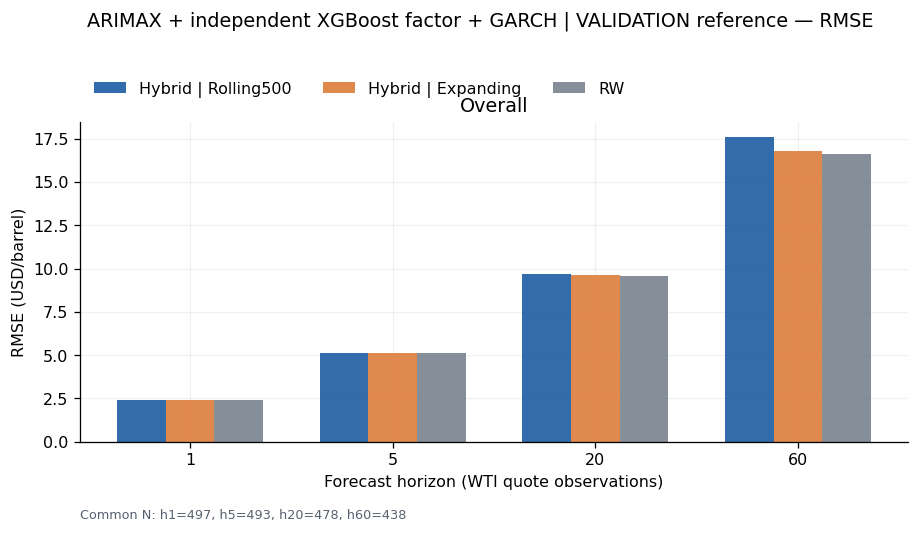

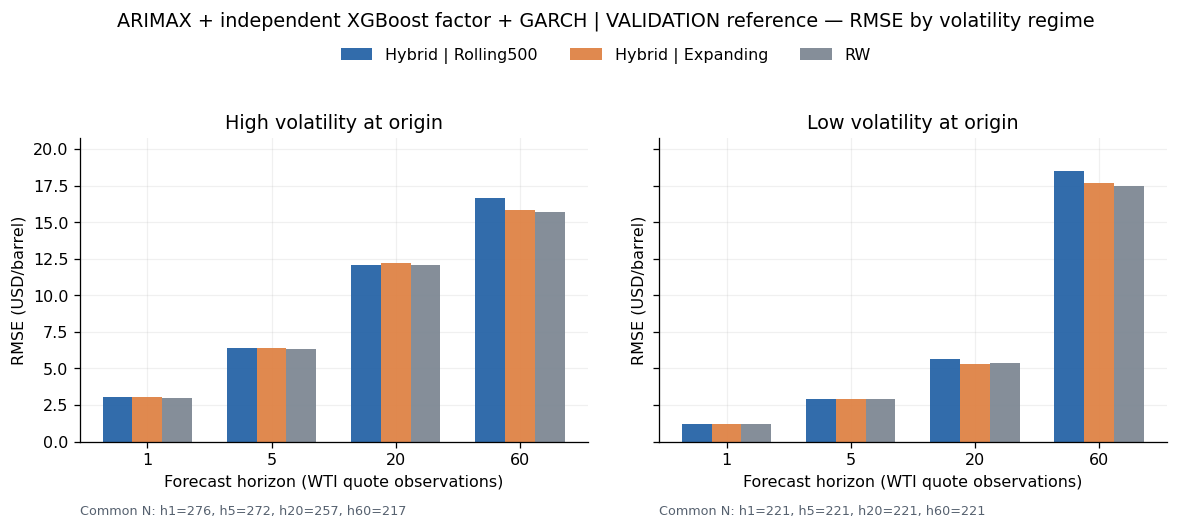

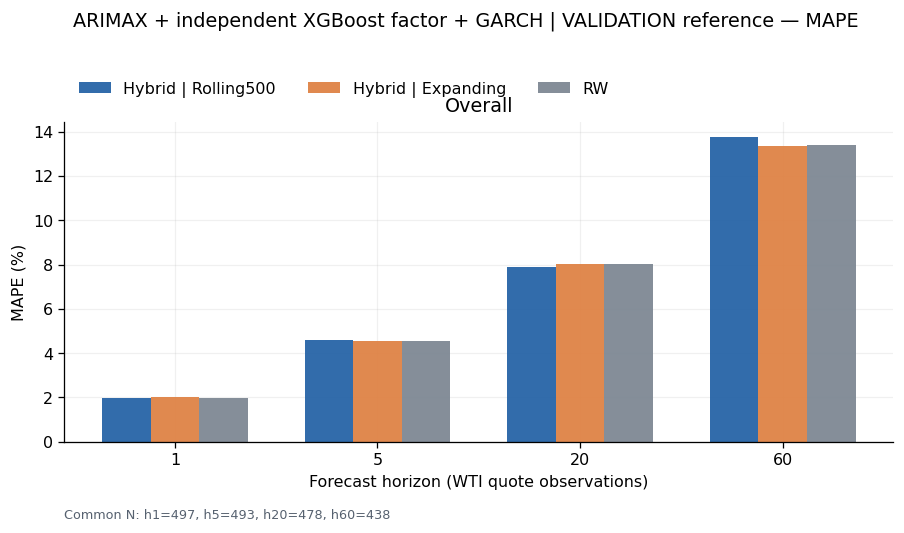

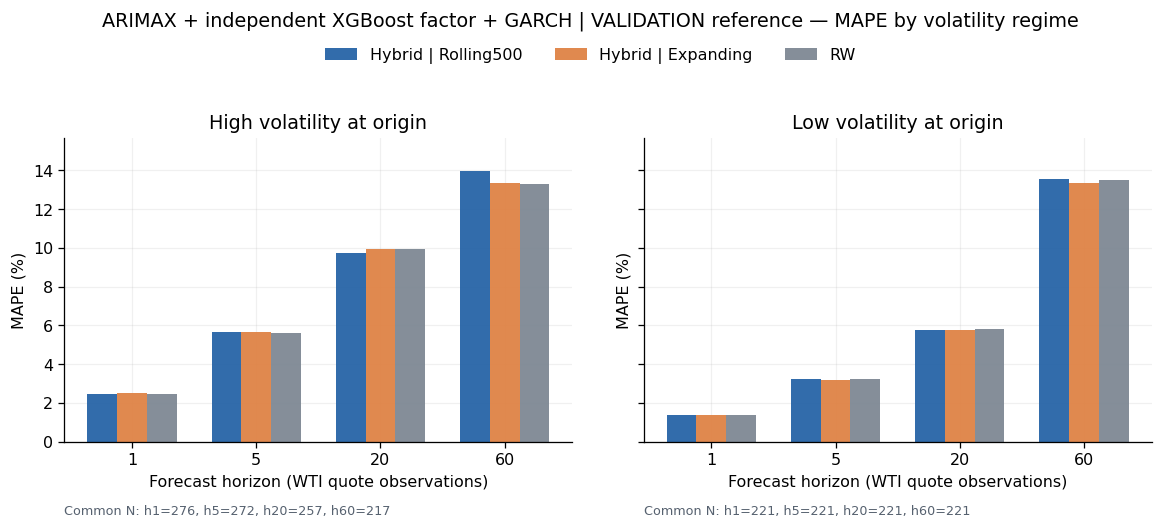

VALIDATION overall reference ranking of the same model set (does not change TEST selection):


,model,eligible,mean_RMSE_to_RW,minimum_common_coverage,minimum_own_coverage,minimum_N,reason,rank
0,RW,True,1.000000,1.0,1.0,438,eligible,1
1,Hybrid | Expanding,True,1.010810,1.0,1.0,438,eligible,2
2,Hybrid | Rolling500,True,1.021234,1.0,1.0,438,eligible,3


,model,eligible,mean_RMSE_to_RW,minimum_common_coverage,minimum_own_coverage,minimum_N,reason,rank
0,Hybrid | Rolling500,True,0.886997,1.0,1.0,17,eligible,1
1,Hybrid | Expanding,True,0.989616,1.0,1.0,17,eligible,2


Selected on TEST mean RMSE/RW at h=1,5,20,60: Hybrid | Rolling500.


In [36]:
hybrid_best, hybrid_metrics, hybrid_ranking = compare_and_select(
    predictions, ["Hybrid | Rolling500","Hybrid | Expanding"], cfg,
    OUTPUT_DIR / "04_window_comparison" / "Hybrid",
    "ARIMAX + independent XGBoost factor + GARCH")

## 9. Equal Weight and DMSFE

Equal Weight uses 50/50 component weights. DMSFE weights each horizon using only earlier matured forecast errors, with theta = 0.9. Empty eligible error history gives equal weights. Component models are selected using test, so the complete comparison remains retrospective even though the weight updates are causal.

Equal Weight and DMSFE | TEST | Overall


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,17,17,17,0,3.195,2.382,2.456,70.588,0.702,17,17,94.118,16.444,ok,ok
1,1,Equal Weight,17,17,17,0,3.194,2.380,2.455,70.588,0.702,17,17,94.118,16.443,ok,ok
2,1,RW,17,17,17,0,3.217,2.397,2.462,35.294,0.261,17,17,94.118,17.026,ok,ok
3,5,DMSFE,17,17,17,0,6.663,4.650,4.834,64.706,0.636,17,17,94.118,37.368,ok,ok
4,5,Equal Weight,17,17,17,0,6.660,4.646,4.830,64.706,0.636,17,17,94.118,37.377,ok,ok
5,5,RW,17,17,17,0,6.735,4.570,4.747,35.294,0.261,17,17,100.000,41.719,ok,ok
6,20,DMSFE,17,17,17,0,9.312,7.283,7.496,64.706,0.646,17,17,100.000,47.018,ok,ok
7,20,Equal Weight,17,17,17,0,9.330,7.314,7.524,58.824,0.564,17,17,100.000,47.477,ok,ok
8,20,RW,17,17,17,0,9.448,7.494,7.712,35.294,0.261,17,17,100.000,51.785,ok,ok
9,60,DMSFE,17,17,17,0,13.228,12.062,12.343,100.000,0.500,17,17,100.000,74.717,ok,ok


Equal Weight and DMSFE | TEST | High


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,17,17,17,0,3.195,2.382,2.456,70.588,0.702,17,17,94.118,16.444,ok,ok
1,1,Equal Weight,17,17,17,0,3.194,2.380,2.455,70.588,0.702,17,17,94.118,16.443,ok,ok
2,1,RW,17,17,17,0,3.217,2.397,2.462,35.294,0.261,17,17,94.118,17.026,ok,ok
3,5,DMSFE,17,17,17,0,6.663,4.650,4.834,64.706,0.636,17,17,94.118,37.368,ok,ok
4,5,Equal Weight,17,17,17,0,6.660,4.646,4.830,64.706,0.636,17,17,94.118,37.377,ok,ok
5,5,RW,17,17,17,0,6.735,4.570,4.747,35.294,0.261,17,17,100.000,41.719,ok,ok
6,20,DMSFE,17,17,17,0,9.312,7.283,7.496,64.706,0.646,17,17,100.000,47.018,ok,ok
7,20,Equal Weight,17,17,17,0,9.330,7.314,7.524,58.824,0.564,17,17,100.000,47.477,ok,ok
8,20,RW,17,17,17,0,9.448,7.494,7.712,35.294,0.261,17,17,100.000,51.785,ok,ok
9,60,DMSFE,17,17,17,0,13.228,12.062,12.343,100.000,0.500,17,17,100.000,74.717,ok,ok


Equal Weight and DMSFE | TEST | Low


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
1,1,Equal Weight,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
2,1,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
3,5,DMSFE,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
4,5,Equal Weight,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
5,5,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
6,20,DMSFE,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
7,20,Equal Weight,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
8,20,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
9,60,DMSFE,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations


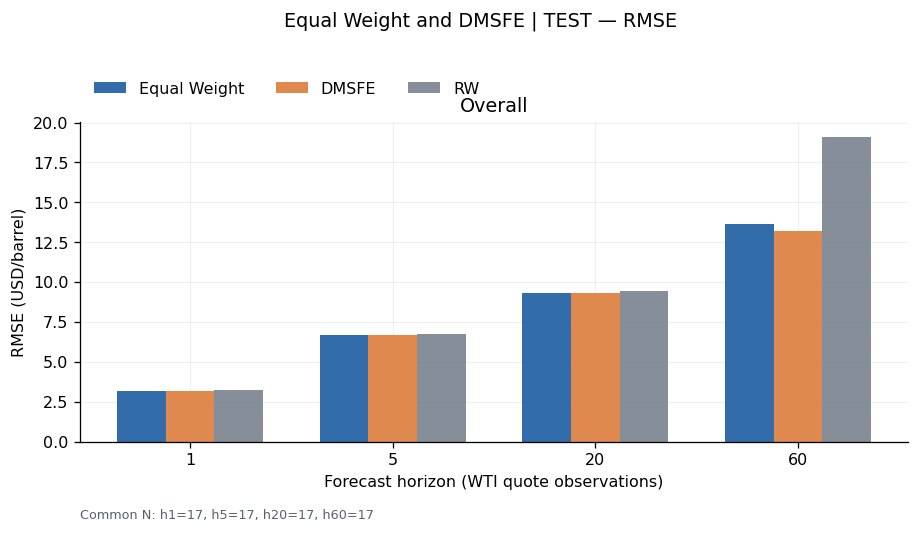

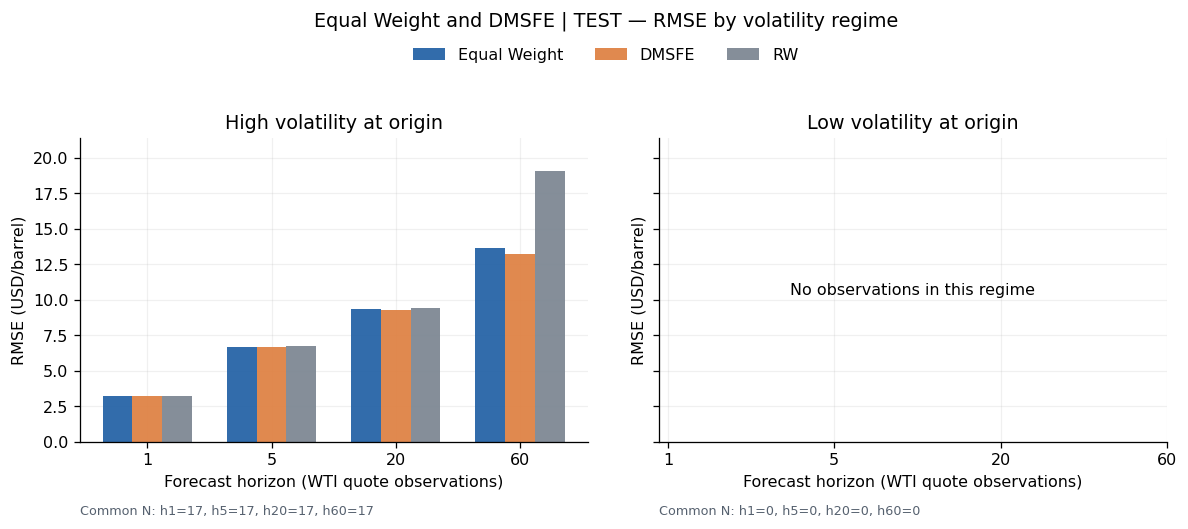

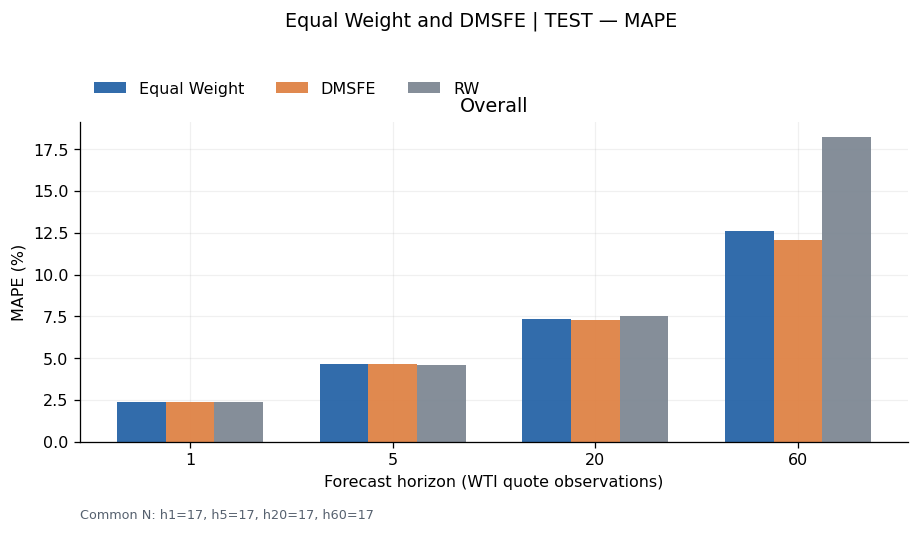

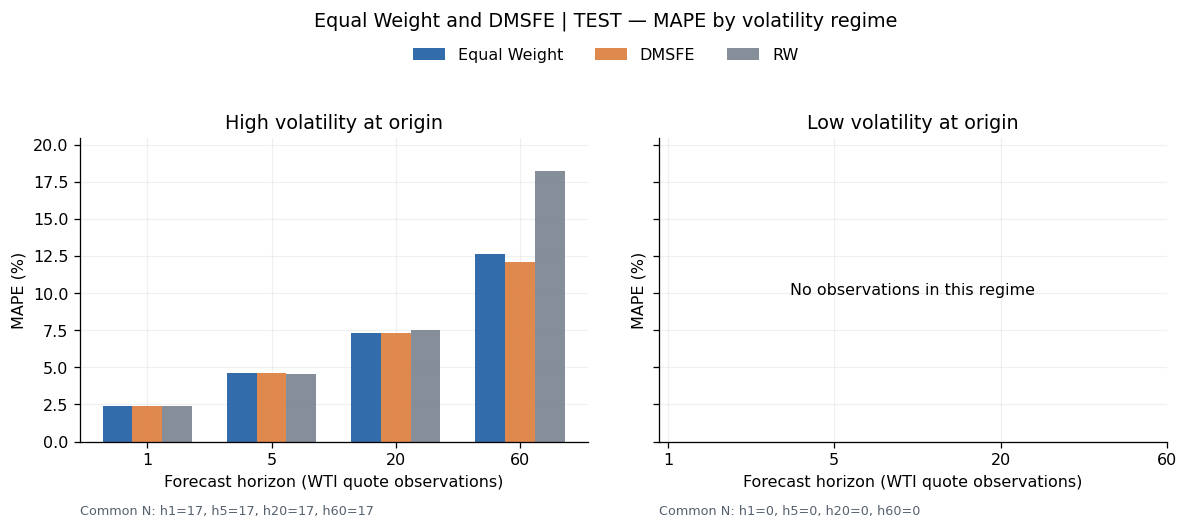

Equal Weight and DMSFE | VALIDATION | Overall


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,497,497,497,0,2.414,1.982,1.517,47.686,0.476,497,497,94.165,7.465,ok,ok
1,1,Equal Weight,497,497,497,0,2.414,1.981,1.516,47.686,0.476,497,497,94.165,7.466,ok,ok
2,1,RW,497,497,497,0,2.380,1.968,1.506,48.692,0.327,497,497,94.165,7.559,ok,ok
3,5,DMSFE,493,493,493,0,5.138,4.559,3.510,49.087,0.464,493,493,91.886,15.997,ok,ok
4,5,Equal Weight,493,493,493,0,5.135,4.558,3.509,48.884,0.463,493,493,91.886,15.999,ok,ok
5,5,RW,493,493,493,0,5.097,4.535,3.491,49.290,0.330,493,493,93.103,16.698,ok,ok
6,20,DMSFE,478,478,478,0,9.650,7.918,6.124,52.929,0.480,478,478,92.050,30.028,ok,ok
7,20,Equal Weight,478,478,478,0,9.668,7.929,6.134,53.138,0.483,478,478,92.050,30.050,ok,ok
8,20,RW,478,478,478,0,9.593,8.036,6.201,56.067,0.359,478,478,93.724,32.532,ok,ok
9,60,DMSFE,438,438,438,0,17.345,13.710,11.085,47.717,0.407,438,438,86.073,46.526,ok,ok


Equal Weight and DMSFE | VALIDATION | High


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,276,276,276,0,3.061,2.478,2.019,47.826,0.478,276,276,93.116,9.590,ok,ok
1,1,Equal Weight,276,276,276,0,3.061,2.478,2.019,47.826,0.478,276,276,93.116,9.591,ok,ok
2,1,RW,276,276,276,0,3.014,2.457,2.002,49.275,0.330,276,276,93.478,9.738,ok,ok
3,5,DMSFE,272,272,272,0,6.404,5.646,4.638,51.103,0.501,272,272,90.441,20.307,ok,ok
4,5,Equal Weight,272,272,272,0,6.400,5.644,4.637,50.735,0.498,272,272,90.441,20.309,ok,ok
5,5,RW,272,272,272,0,6.346,5.593,4.601,51.838,0.341,272,272,91.912,21.280,ok,ok
6,20,DMSFE,257,257,257,0,12.154,9.859,8.108,50.973,0.491,257,257,87.549,37.525,ok,ok
7,20,Equal Weight,257,257,257,0,12.177,9.873,8.120,50.973,0.491,257,257,87.549,37.562,ok,ok
8,20,RW,257,257,257,0,12.104,9.933,8.175,56.031,0.359,257,257,90.661,40.533,ok,ok
9,60,DMSFE,217,217,217,0,16.638,14.182,11.260,38.710,0.343,217,217,90.323,56.138,ok,ok


Equal Weight and DMSFE | VALIDATION | Low


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,221,221,221,0,1.185,1.362,0.889,47.511,0.465,221,221,95.475,4.812,ok,ok
1,1,Equal Weight,221,221,221,0,1.185,1.362,0.889,47.511,0.465,221,221,95.475,4.813,ok,ok
2,1,RW,221,221,221,0,1.179,1.357,0.886,47.964,0.324,221,221,95.023,4.838,ok,ok
3,5,DMSFE,221,221,221,0,2.900,3.220,2.120,46.606,0.405,221,221,93.665,10.692,ok,ok
4,5,Equal Weight,221,221,221,0,2.900,3.221,2.121,46.606,0.405,221,221,93.665,10.695,ok,ok
5,5,RW,221,221,221,0,2.895,3.232,2.124,46.154,0.316,221,221,94.570,11.058,ok,ok
6,20,DMSFE,221,221,221,0,5.442,5.661,3.818,55.204,0.442,221,221,97.285,21.310,ok,ok
7,20,Equal Weight,221,221,221,0,5.455,5.669,3.824,55.656,0.451,221,221,97.285,21.313,ok,ok
8,20,RW,221,221,221,0,5.357,5.831,3.904,56.109,0.359,221,221,97.285,23.228,ok,ok
9,60,DMSFE,221,221,221,0,18.012,13.247,10.912,56.561,0.467,221,221,81.900,37.089,ok,ok


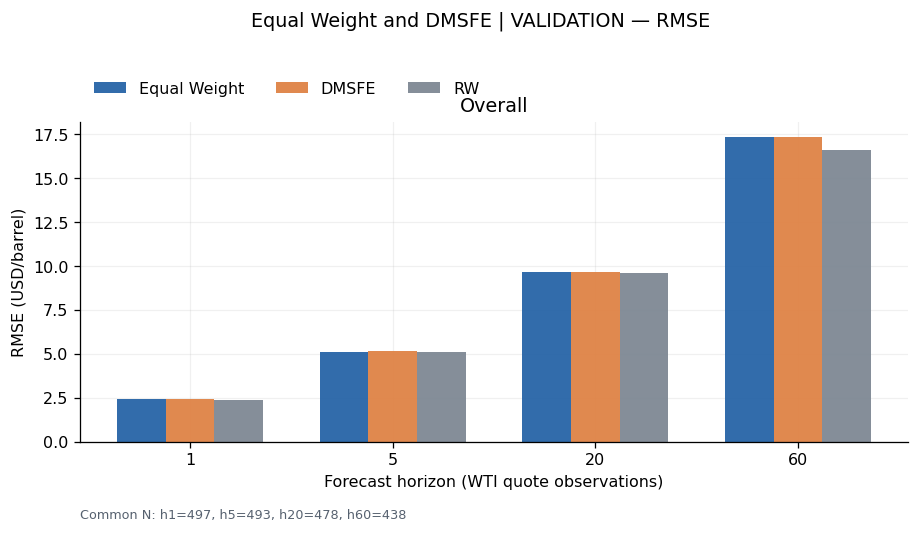

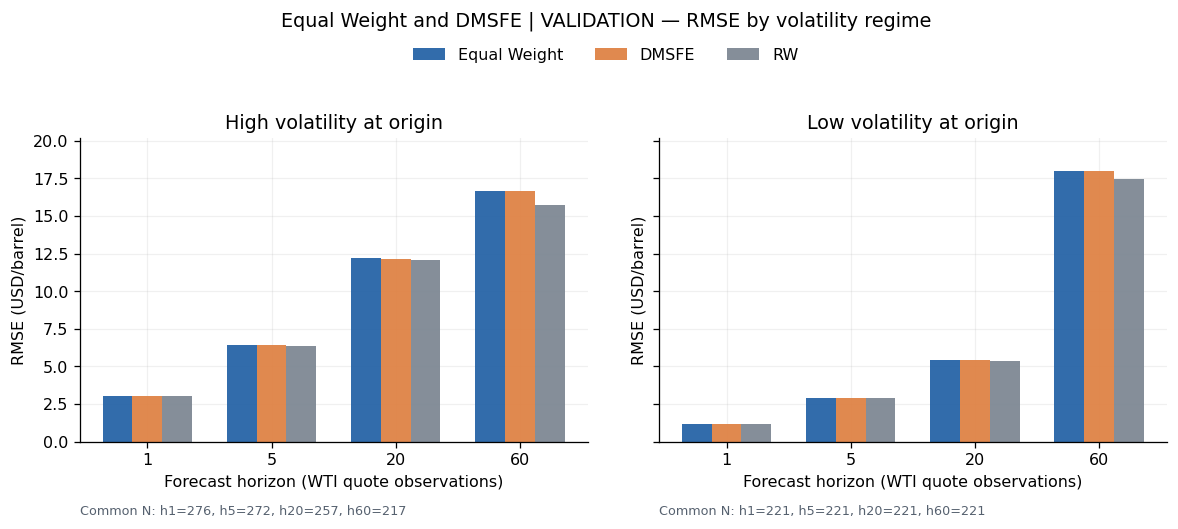

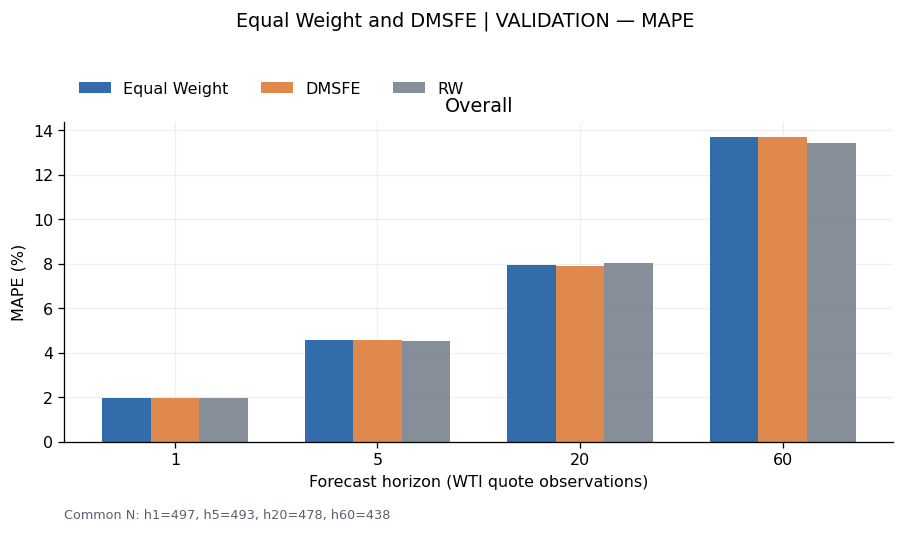

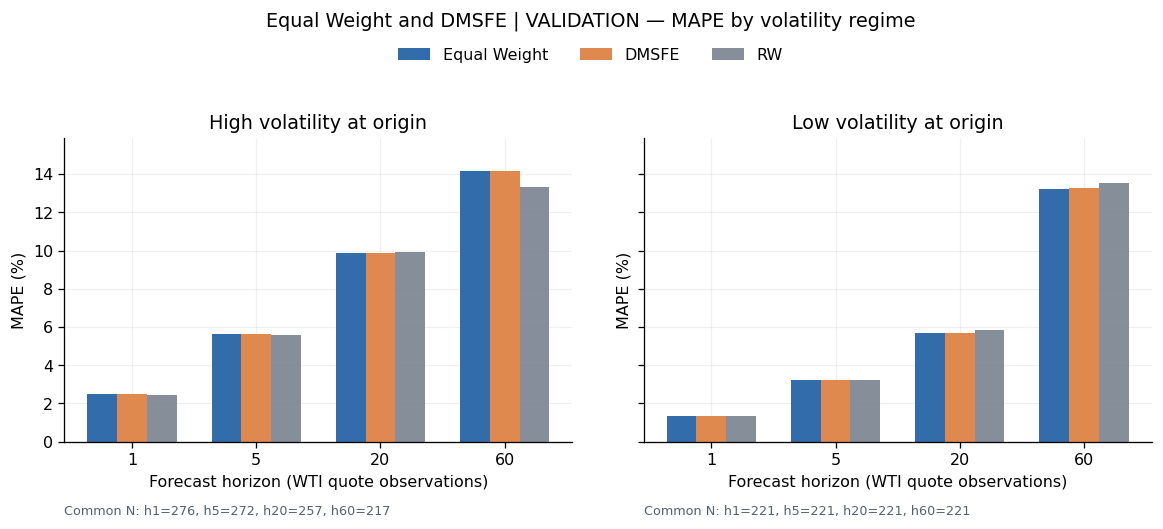

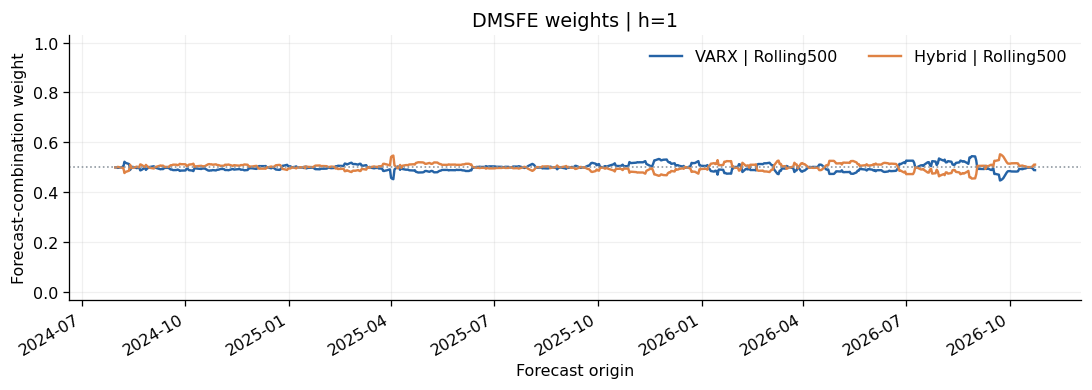

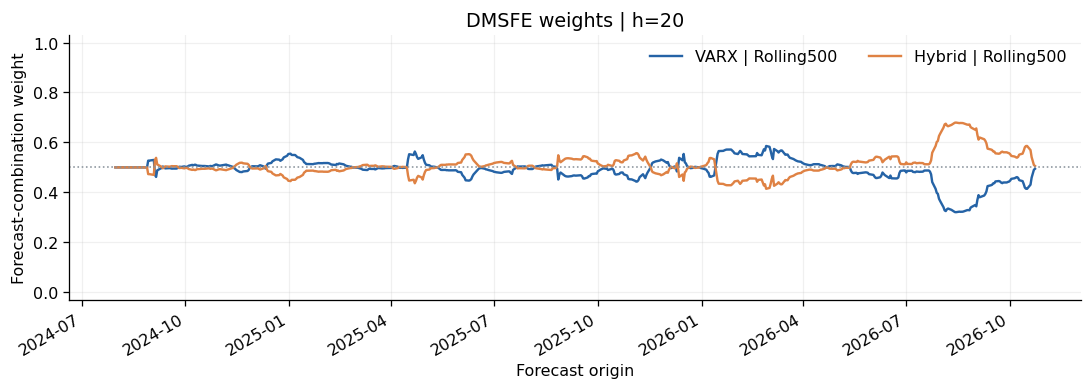

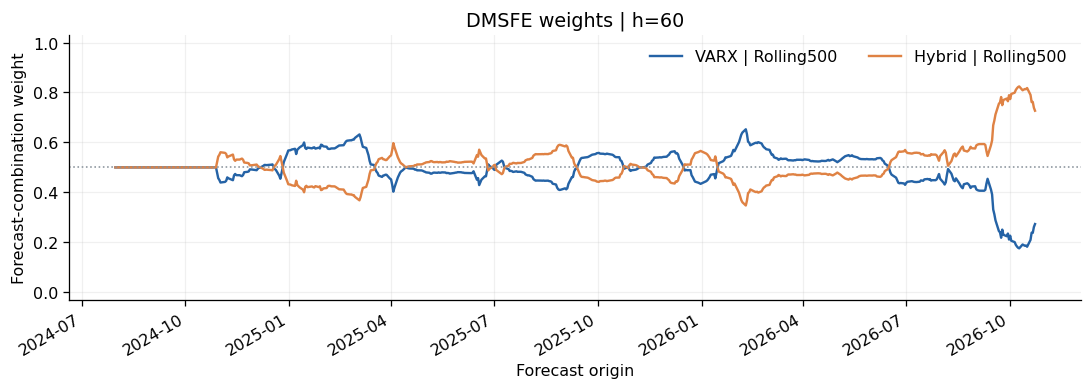

In [37]:
combination_predictions, combination_weights = make_combinations(predictions, payloads, var_best, hybrid_best, cfg)
all_predictions = pd.concat([predictions, combination_predictions], ignore_index=True)
for split in ("test", "validation"):
    models = ["Equal Weight","DMSFE","RW"]
    m = paired_metrics(all_predictions, models, split=split)
    plot_stage(m, models, OUTPUT_DIR / "05_combinations" / split,
               f"Equal Weight and DMSFE | {split.upper()}", show=cfg["SHOW_PLOTS"])
plot_weights(combination_weights, OUTPUT_DIR / "05_combinations" / "weights", model_a=var_best, model_b=hybrid_best, horizons=(1,20,60), show=cfg["SHOW_PLOTS"])

## 10. Final five-model comparison

Compare the selected VAR-family window, selected ARIMAX window, Equal Weight, DMSFE and RW. The ranking averages RMSE/RW equally over h = 1, 5, 20 and 60 on matched observations. The displayed validation ranking evaluates the same component set and does not overwrite the test-selected winner.

Final five-model comparison | Overall


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,17,17,17,0,3.195,2.382,2.456,70.588,0.702,17,17,94.118,16.444,ok,ok
1,1,Equal Weight,17,17,17,0,3.194,2.380,2.455,70.588,0.702,17,17,94.118,16.443,ok,ok
2,1,Hybrid | Rolling500,17,17,17,0,3.231,2.408,2.481,58.824,0.588,17,17,94.118,16.603,ok,ok
3,1,RW,17,17,17,0,3.217,2.397,2.462,35.294,0.261,17,17,94.118,17.026,ok,ok
4,1,VARX | Rolling500,17,17,17,0,3.174,2.352,2.429,58.824,0.582,17,17,94.118,16.328,ok,ok
5,5,DMSFE,17,17,17,0,6.663,4.650,4.834,64.706,0.636,17,17,94.118,37.368,ok,ok
6,5,Equal Weight,17,17,17,0,6.660,4.646,4.830,64.706,0.636,17,17,94.118,37.377,ok,ok
7,5,Hybrid | Rolling500,17,17,17,0,6.738,4.719,4.913,52.941,0.528,17,17,94.118,37.230,ok,ok
8,5,RW,17,17,17,0,6.735,4.570,4.747,35.294,0.261,17,17,100.000,41.719,ok,ok
9,5,VARX | Rolling500,17,17,17,0,6.599,4.618,4.790,52.941,0.485,17,17,94.118,37.650,ok,ok


Final five-model comparison | High


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,17,17,17,0,3.195,2.382,2.456,70.588,0.702,17,17,94.118,16.444,ok,ok
1,1,Equal Weight,17,17,17,0,3.194,2.380,2.455,70.588,0.702,17,17,94.118,16.443,ok,ok
2,1,Hybrid | Rolling500,17,17,17,0,3.231,2.408,2.481,58.824,0.588,17,17,94.118,16.603,ok,ok
3,1,RW,17,17,17,0,3.217,2.397,2.462,35.294,0.261,17,17,94.118,17.026,ok,ok
4,1,VARX | Rolling500,17,17,17,0,3.174,2.352,2.429,58.824,0.582,17,17,94.118,16.328,ok,ok
5,5,DMSFE,17,17,17,0,6.663,4.650,4.834,64.706,0.636,17,17,94.118,37.368,ok,ok
6,5,Equal Weight,17,17,17,0,6.660,4.646,4.830,64.706,0.636,17,17,94.118,37.377,ok,ok
7,5,Hybrid | Rolling500,17,17,17,0,6.738,4.719,4.913,52.941,0.528,17,17,94.118,37.230,ok,ok
8,5,RW,17,17,17,0,6.735,4.570,4.747,35.294,0.261,17,17,100.000,41.719,ok,ok
9,5,VARX | Rolling500,17,17,17,0,6.599,4.618,4.790,52.941,0.485,17,17,94.118,37.650,ok,ok


Final five-model comparison | Low


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
1,1,Equal Weight,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
2,1,Hybrid | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
3,1,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
4,1,VARX | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
5,5,DMSFE,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
6,5,Equal Weight,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
7,5,Hybrid | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
8,5,RW,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations
9,5,VARX | Rolling500,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,no observations,no observations


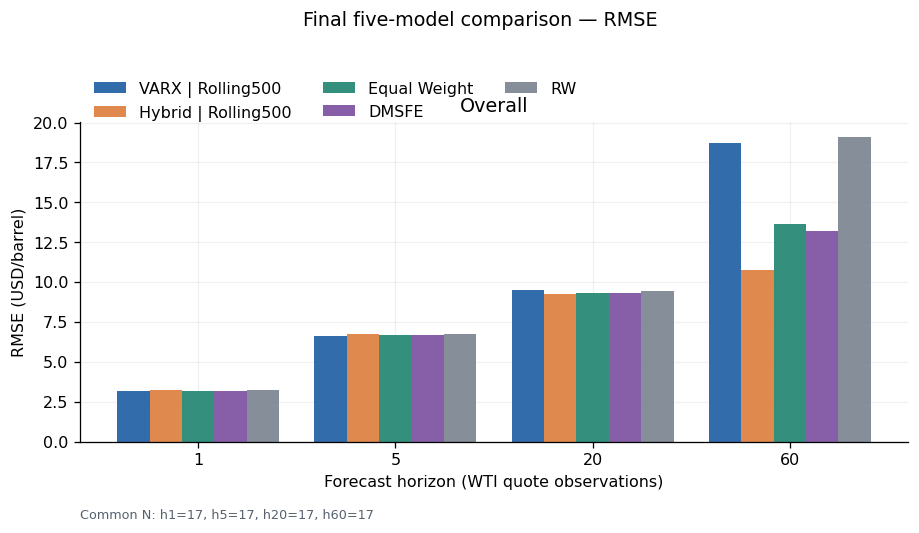

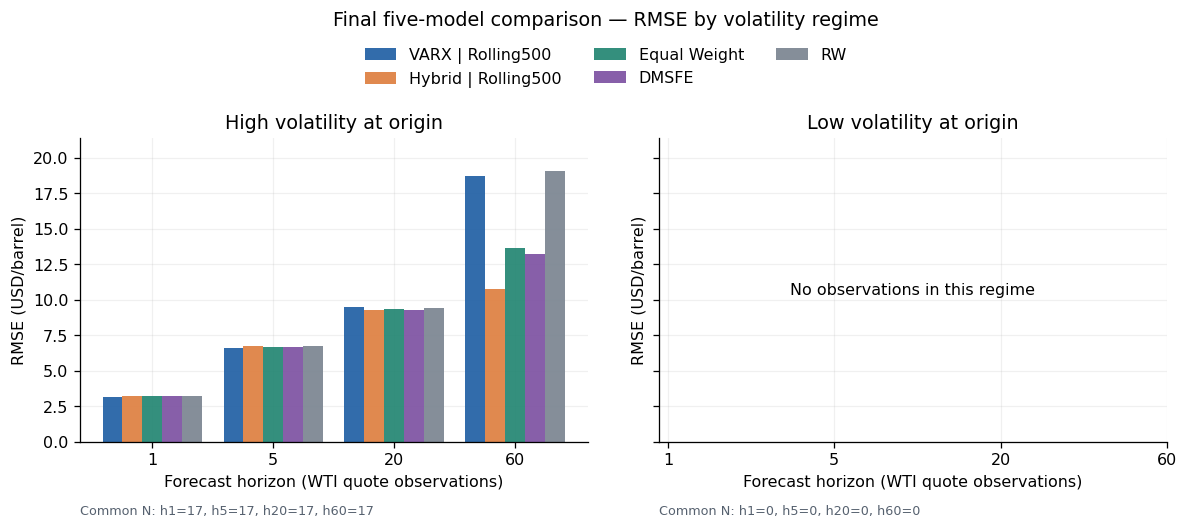

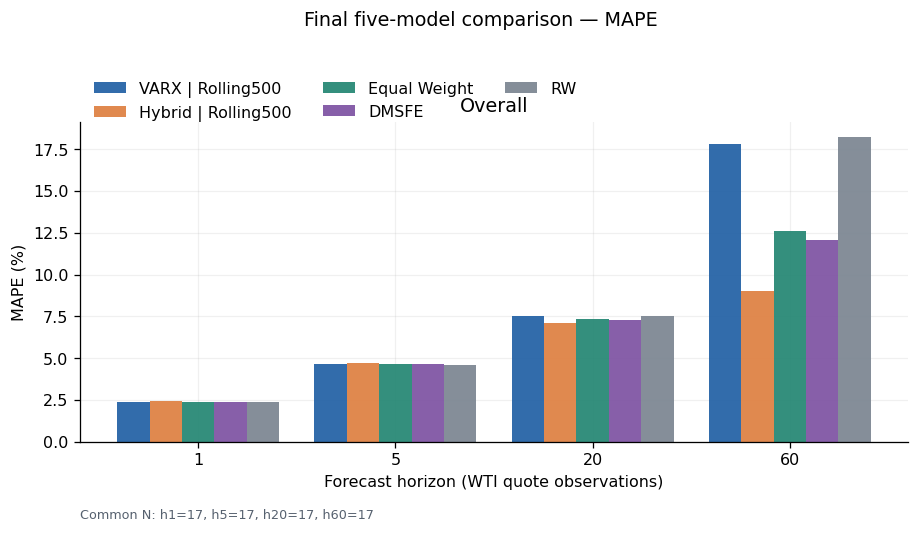

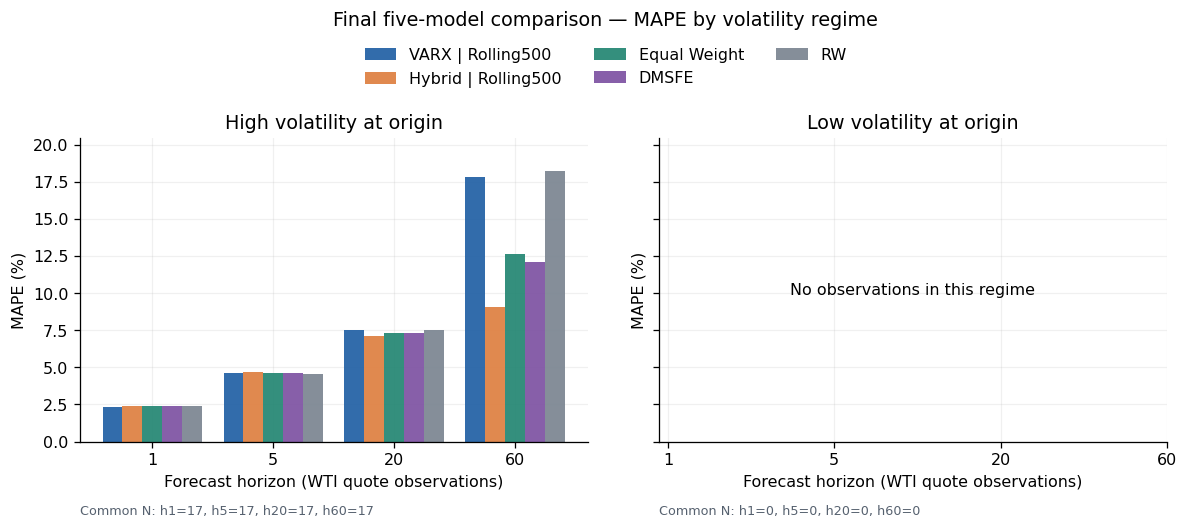

Final five-model comparison | VALIDATION reference | Overall


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,497,497,497,0,2.414,1.982,1.517,47.686,0.476,497,497,94.165,7.465,ok,ok
1,1,Equal Weight,497,497,497,0,2.414,1.981,1.516,47.686,0.476,497,497,94.165,7.466,ok,ok
2,1,Hybrid | Rolling500,497,497,497,0,2.410,1.980,1.515,45.272,0.449,497,497,94.165,7.496,ok,ok
3,1,RW,497,497,497,0,2.380,1.968,1.506,48.692,0.327,497,497,94.165,7.559,ok,ok
4,1,VARX | Rolling500,497,497,497,0,2.429,1.993,1.527,48.491,0.483,497,497,94.165,7.462,ok,ok
5,5,DMSFE,493,493,493,0,5.138,4.559,3.510,49.087,0.464,493,493,91.886,15.997,ok,ok
6,5,Equal Weight,493,493,493,0,5.135,4.558,3.509,48.884,0.463,493,493,91.886,15.999,ok,ok
7,5,Hybrid | Rolling500,493,493,493,0,5.123,4.574,3.511,50.101,0.472,493,493,91.684,16.212,ok,ok
8,5,RW,493,493,493,0,5.097,4.535,3.491,49.290,0.330,493,493,93.103,16.698,ok,ok
9,5,VARX | Rolling500,493,493,493,0,5.172,4.557,3.518,49.493,0.477,493,493,91.684,15.856,ok,ok


Final five-model comparison | VALIDATION reference | High


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,276,276,276,0,3.061,2.478,2.019,47.826,0.478,276,276,93.116,9.590,ok,ok
1,1,Equal Weight,276,276,276,0,3.061,2.478,2.019,47.826,0.478,276,276,93.116,9.591,ok,ok
2,1,Hybrid | Rolling500,276,276,276,0,3.054,2.473,2.014,46.739,0.467,276,276,93.478,9.633,ok,ok
3,1,RW,276,276,276,0,3.014,2.457,2.002,49.275,0.330,276,276,93.478,9.738,ok,ok
4,1,VARX | Rolling500,276,276,276,0,3.082,2.498,2.036,48.913,0.489,276,276,93.116,9.584,ok,ok
5,5,DMSFE,272,272,272,0,6.404,5.646,4.638,51.103,0.501,272,272,90.441,20.307,ok,ok
6,5,Equal Weight,272,272,272,0,6.400,5.644,4.637,50.735,0.498,272,272,90.441,20.309,ok,ok
7,5,Hybrid | Rolling500,272,272,272,0,6.371,5.646,4.623,52.574,0.514,272,272,90.441,20.600,ok,ok
8,5,RW,272,272,272,0,6.346,5.593,4.601,51.838,0.341,272,272,91.912,21.280,ok,ok
9,5,VARX | Rolling500,272,272,272,0,6.462,5.661,4.666,49.632,0.490,272,272,90.441,20.105,ok,ok


Final five-model comparison | VALIDATION reference | Low


,horizon,model,N,N_expected,n_available,n_missing,RMSE,MAPE,MAE,DA,F1,n_interval,n_interval_available,Coverage95,Width95,status,interval_status
0,1,DMSFE,221,221,221,0,1.185,1.362,0.889,47.511,0.465,221,221,95.475,4.812,ok,ok
1,1,Equal Weight,221,221,221,0,1.185,1.362,0.889,47.511,0.465,221,221,95.475,4.813,ok,ok
2,1,Hybrid | Rolling500,221,221,221,0,1.190,1.364,0.891,43.439,0.417,221,221,95.023,4.828,ok,ok
3,1,RW,221,221,221,0,1.179,1.357,0.886,47.964,0.324,221,221,95.023,4.838,ok,ok
4,1,VARX | Rolling500,221,221,221,0,1.183,1.364,0.891,47.964,0.472,221,221,95.475,4.812,ok,ok
5,5,DMSFE,221,221,221,0,2.900,3.220,2.120,46.606,0.405,221,221,93.665,10.692,ok,ok
6,5,Equal Weight,221,221,221,0,2.900,3.221,2.121,46.606,0.405,221,221,93.665,10.695,ok,ok
7,5,Hybrid | Rolling500,221,221,221,0,2.931,3.255,2.142,47.059,0.408,221,221,93.213,10.812,ok,ok
8,5,RW,221,221,221,0,2.895,3.232,2.124,46.154,0.316,221,221,94.570,11.058,ok,ok
9,5,VARX | Rolling500,221,221,221,0,2.876,3.198,2.106,49.321,0.451,221,221,93.213,10.627,ok,ok


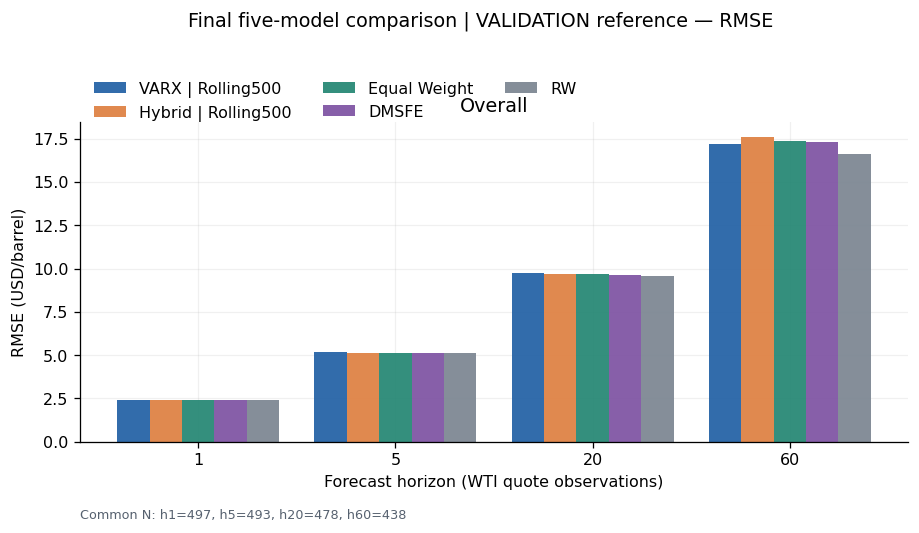

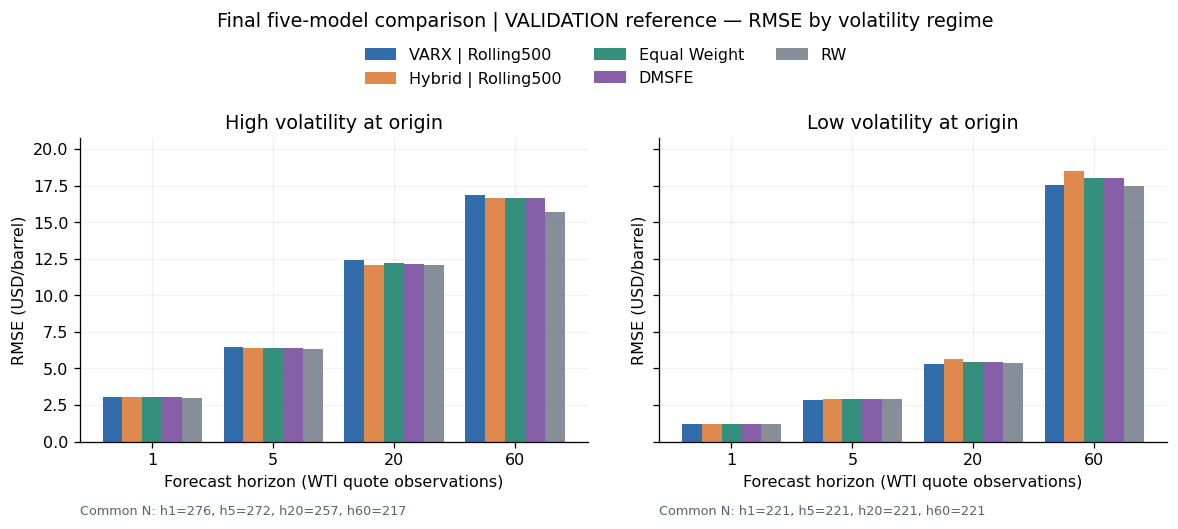

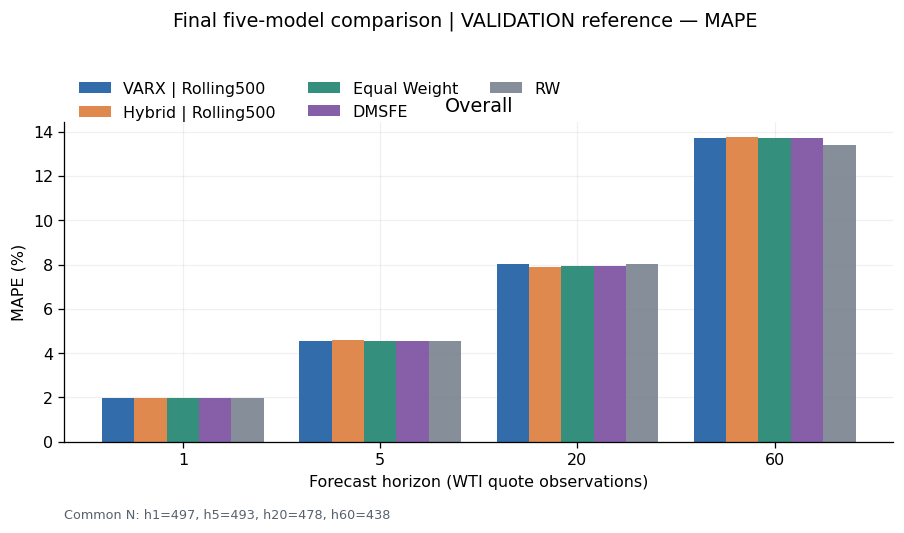

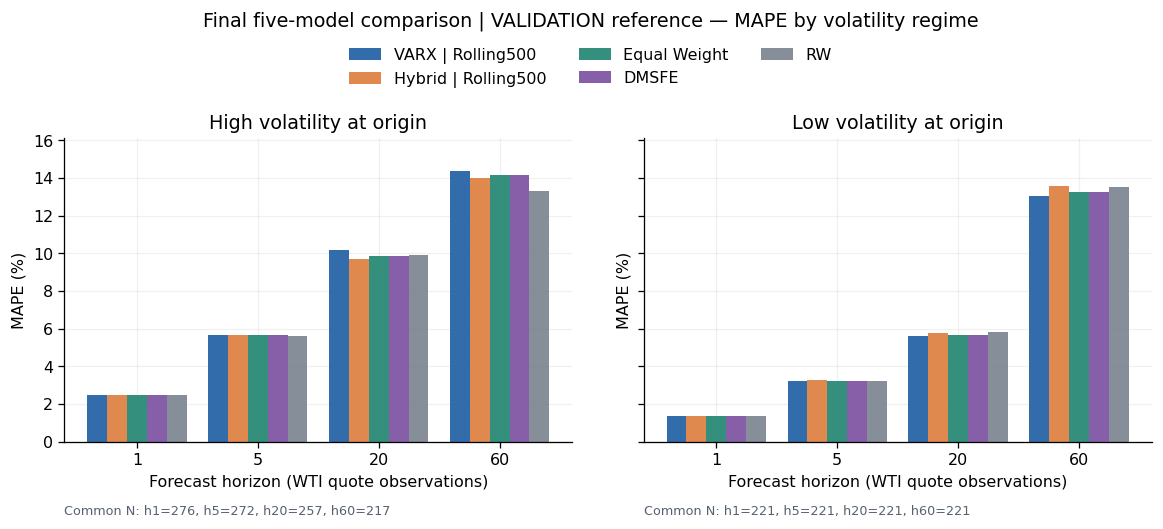

VALIDATION overall reference ranking of the same model set (does not change TEST selection):


,model,eligible,mean_RMSE_to_RW,minimum_common_coverage,minimum_own_coverage,minimum_N,reason,rank
0,RW,True,1.000000,1.0,1.0,438,eligible,1
1,DMSFE,True,1.017944,1.0,1.0,438,eligible,2
2,Equal Weight,True,1.018653,1.0,1.0,438,eligible,3
3,Hybrid | Rolling500,True,1.021234,1.0,1.0,438,eligible,4
4,VARX | Rolling500,True,1.021933,1.0,1.0,438,eligible,5


,model,eligible,mean_RMSE_to_RW,minimum_common_coverage,minimum_own_coverage,minimum_N,reason,rank
0,Hybrid | Rolling500,True,0.886997,1.0,1.0,17,eligible,1
1,DMSFE,True,0.915118,1.0,1.0,17,eligible,2
2,Equal Weight,True,0.921075,1.0,1.0,17,eligible,3
3,VARX | Rolling500,True,0.988651,1.0,1.0,17,eligible,4
4,RW,True,1.000000,1.0,1.0,17,eligible,5


Selected on TEST mean RMSE/RW at h=1,5,20,60: Hybrid | Rolling500.
Final TEST-selected model: Hybrid | Rolling500


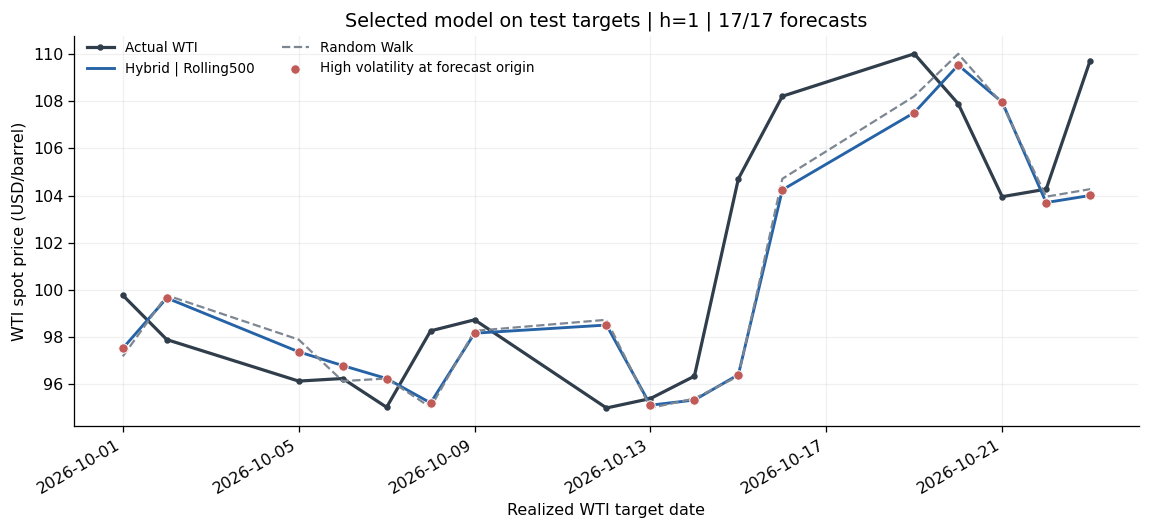

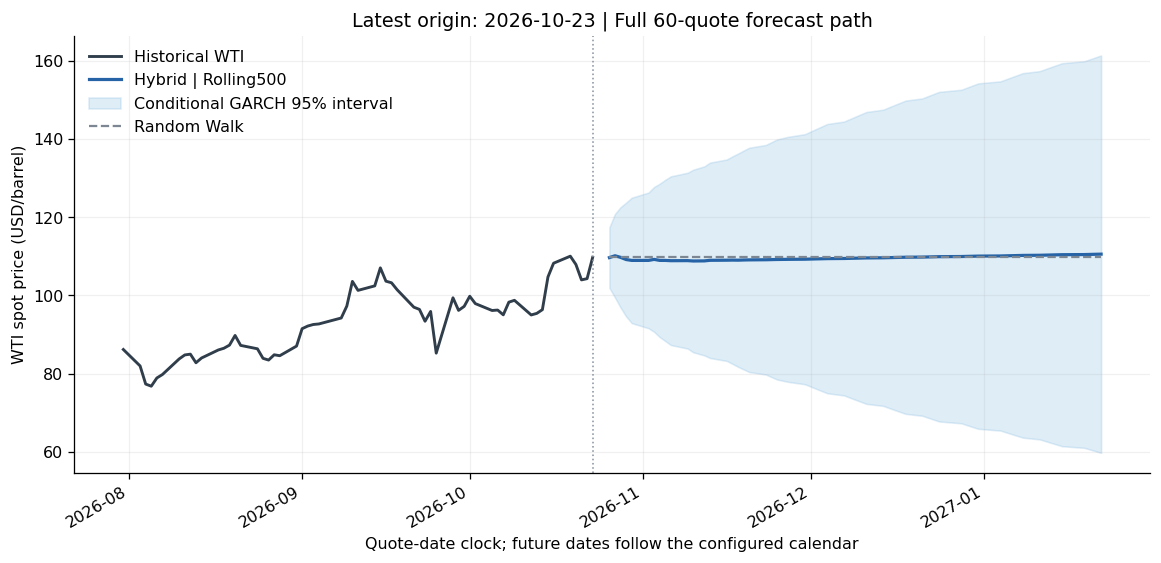

Selected model: complete point path; GARCH interval complete (first and last rows)


,horizon,target_date,pred,lower95,upper95,date_status
300480,1,2026-10-26,109.650,101.906,117.394,projected US federal business date
300481,2,2026-10-27,110.119,99.423,120.814,projected US federal business date
300482,3,2026-10-28,109.704,96.869,122.539,projected US federal business date
300483,4,2026-10-29,109.146,94.584,123.709,projected US federal business date
300484,5,2026-10-30,108.928,92.892,124.964,projected US federal business date
300535,56,2027-01-15,110.388,61.449,159.328,projected US federal business date
300536,57,2027-01-19,110.424,61.021,159.828,projected US federal business date
300537,58,2027-01-20,110.460,60.596,160.325,projected US federal business date
300538,59,2027-01-21,110.496,60.173,160.819,projected US federal business date
300539,60,2027-01-22,110.532,59.754,161.311,projected US federal business date


Forecast comparison saved: D:\Study\NUS Documentation\Coursework\2026 Semester 1\QF5210\Group project\WTI_Independent_ML_Results


In [38]:
final_candidates = [var_best, hybrid_best, "Equal Weight", "DMSFE", "RW"]
winner, final_metrics, final_ranking = compare_and_select(
    all_predictions, final_candidates, cfg, OUTPUT_DIR / "06_final", "Final five-model comparison")
print("Final TEST-selected model:", winner)
plot_test_fit(all_predictions, winner, OUTPUT_DIR / "06_final" / "test_fit", show=cfg["SHOW_PLOTS"])
summary = finish_outputs(all_predictions, combination_weights,
    {"VAR_family":VAR_FAMILY,"VAR_window":var_best,"Hybrid_window":hybrid_best},
    winner, panel, cfg, OUTPUT_DIR)

## 11. Trading diagnostic

The original simple strategy and costs are retained: predicted return above +0.5% enters long; below −0.5% enters short; otherwise cash. Positions do not overlap, and each active trade pays 5 bps at entry and exit. Entry and exit must both lie inside the October test. Longer holding periods can therefore have no complete trade. The default displayed holding period is 5 quotes; tables cover 1–60.

This uses spot-price-change proxies and test-selected models. It is a retrospective diagnostic, without futures rolls, margin or executable fills. High/Low is determined at the entry origin.

Trading proxy: test-selected winner; ±0.50% threshold, 5.0 bps each way.
High/Low results use entry regime and hold cash outside that regime. All 1–60 holding periods are exported.


,horizon,strategy,regime,N_intervals,N_active_trades,net_return_pct,max_drawdown_pct,win_rate_pct,annualized_daily_Sharpe_approx,status
0,5,Hybrid | Rolling500,Overall,3,2,-6.365349,-14.246100,50.000000,NaN,OK
1,5,Hybrid | Rolling500,High,3,2,-6.365349,-14.246100,50.000000,NaN,OK
2,5,Hybrid | Rolling500,Low,0,0,NaN,NaN,NaN,NaN,No complete non-overlapping interval with entr...
3,5,Random Walk,Overall,3,0,0.000000,0.000000,NaN,NaN,Cash: no active signals
4,5,Random Walk,High,3,0,0.000000,0.000000,NaN,NaN,Cash: no active signals
5,5,Random Walk,Low,0,0,NaN,NaN,NaN,NaN,No complete non-overlapping interval with entr...
6,5,Always long (matched intervals),Overall,3,3,4.201538,-5.511213,33.333333,NaN,OK
7,5,Always long (matched intervals),High,3,3,4.201538,-5.511213,33.333333,NaN,OK
8,5,Always long (matched intervals),Low,0,0,NaN,NaN,NaN,NaN,No complete non-overlapping interval with entr...


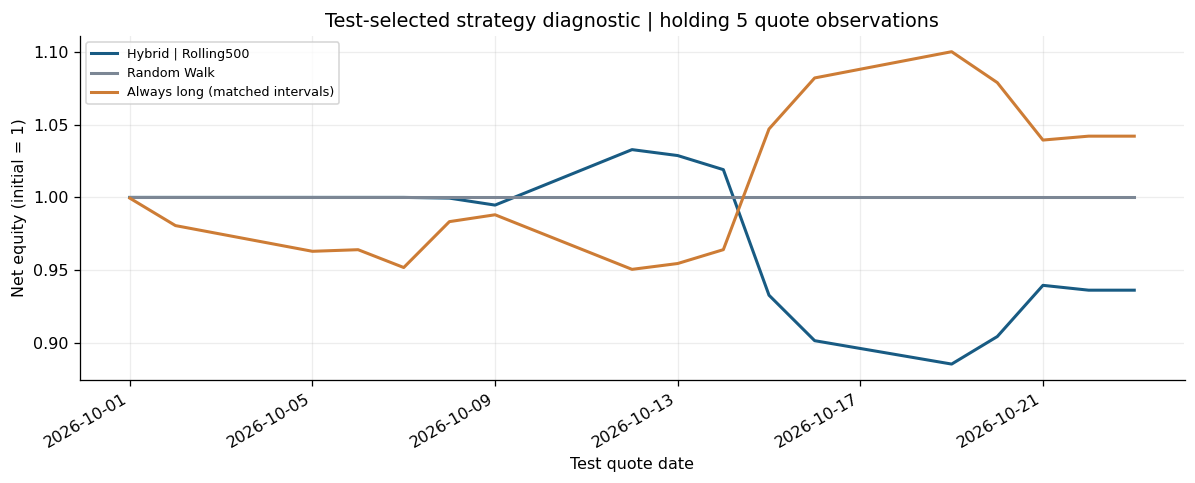

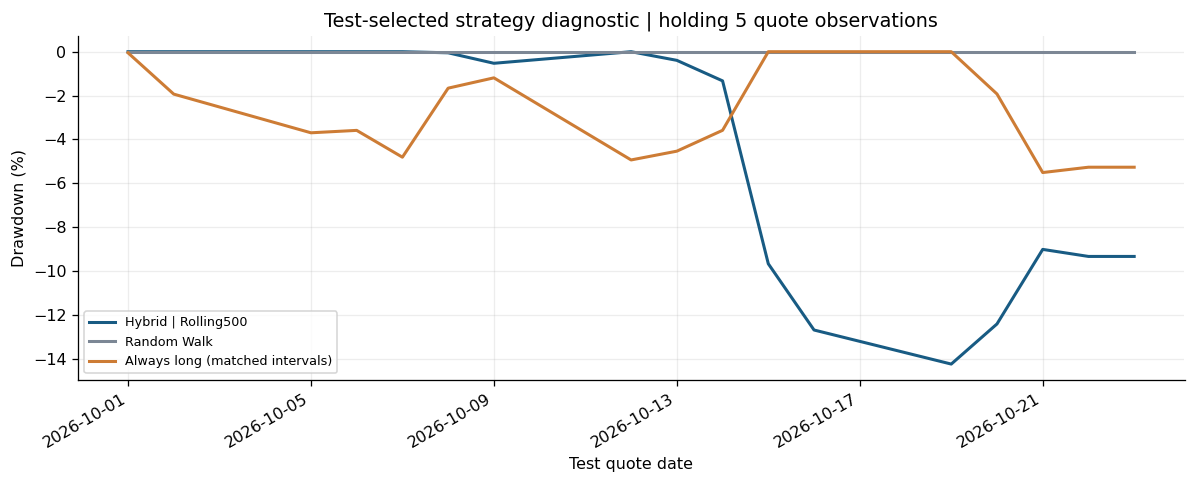

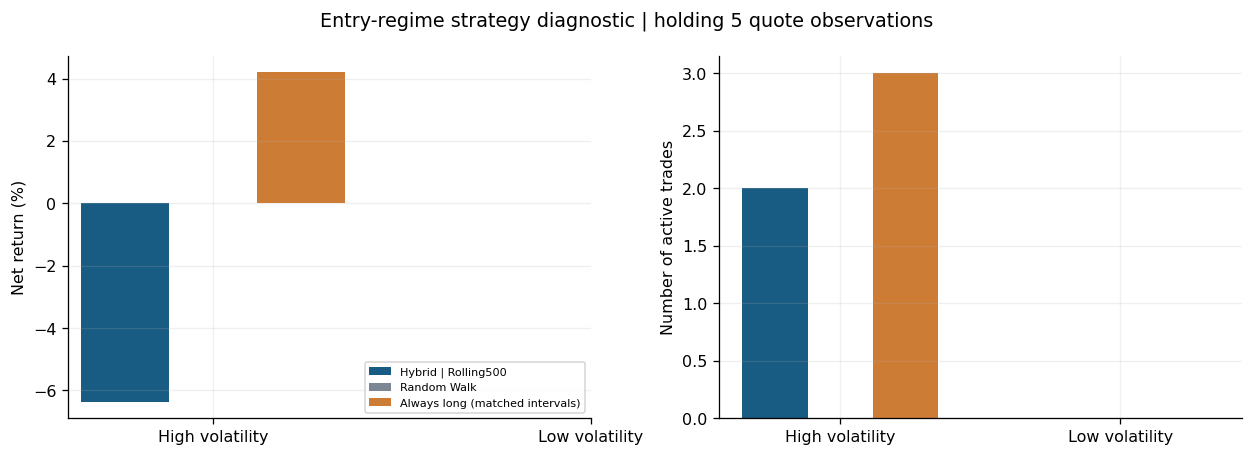

In [39]:
trade_results = run_trading(all_predictions, panel, winner, cfg, OUTPUT_DIR / "07_trading")

## 12. Timing and output checks

High/Low uses the trailing 20-quote standard deviation of WTI dollar changes and a median frozen before the main validation period. Under this source calendar the October test origins may all be High, leaving Low test N = 0; longer validation reference results are displayed separately.

Source data retain their supplied as-of adjustments and revised research vintages; historical first-release vintages are not reconstructed. The price clock assumes the origin WTI observation is known. Future dates are projected business dates, not a verified future EIA release calendar.

In [40]:
for family in ("Hybrid", "VARX"):
    assert len(ml_choices[family]["fields"]) == cfg["ML_KEEP_FIELDS"]
    for window in ("Rolling500", "Expanding"):
        frame = factor_store["oof"][(family,window)]
        good = frame.factor.notna()
        dates = frame.index[good]
        assert (dates > pd.Timestamp(ml_choices[family]["selection_cutoff"])).all()
        assert (pd.to_datetime(frame.loc[good,"fit_last_target"]).to_numpy() < dates.to_numpy()).all()
        assert (pd.to_datetime(frame.loc[good,"last_feature_date"]).to_numpy() < dates.to_numpy()).all()
test_rows = all_predictions.loc[all_predictions.split.eq("test")]
assert (pd.to_datetime(test_rows.feature_freeze_date) < test_rows.origin_date).all()
assert all_predictions.groupby(["model","origin_date"]).size().eq(cfg["H"]).all()
print("Timing checks passed: independent multi-field ML inputs; feature freeze before all historical factors; past-only OOF labels/features; full 60-position paths.")
print("Inspect 01_fit/failures.csv and 02_ml_factors/oof_factor_failures.csv for numerical or data failures.")
print("Results directory:", OUTPUT_DIR.resolve())

Timing checks passed: independent multi-field ML inputs; feature freeze before all historical factors; past-only OOF labels/features; full 60-position paths.
Inspect 01_fit/failures.csv and 02_ml_factors/oof_factor_failures.csv for numerical or data failures.
Results directory: D:\Study\NUS Documentation\Coursework\2026 Semester 1\QF5210\Group project\WTI_Independent_ML_Results


| Output | Contents |
|---|---|
| 00_field_audit/ | All 65 fields and initial-development admission decisions |
| 01_ml_selection/ | Separate ML targets, candidate/fold losses, selected input lists |
| 02_ml_factors/ | Four OOF scalar-factor histories, timestamps, missing-input diagnostics |
| 01_fit/ | Complete recursive mean/GARCH forecasts, fit log, latest scalar-factor paths |
| 03_factor_ablation/ | VAR versus VARX; ARIMA versus ARIMAX, matched windows |
| 04_window_comparison/ | Test and validation reference tables/figures/rankings |
| 05_combinations/ | Equal Weight/DMSFE results and causal weight history |
| 06_final/ | Final five-model comparison, including validation reference |
| 07_trading/ | Trading metrics for all holding periods |

This version implements two independent ML-generated scalar regressors. It does not reproduce the earlier exploratory price-level improvement table, which used a different mean-model specification. No predetermined improvement over RW is imposed.

In [42]:
RESULTS_DIR = globals().get("OUTPUT_DIR", "WTI_Independent_ML_Results")
%run -i "WTI_Export_Addon.py"

Five-model export: origin 2026-09-30, h=1 2026-10-01, h=60 2026-12-28.
Calendar-cut copy ends 2026-11-30; no weekend rows or missing predictions are manufactured.
Trading metrics | h=5 | net of original costs | 252 quotes/year | annual rf=0.00%
Return, volatility and drawdown are percentages below; CSVs store decimal fractions. Drawdown is a positive magnitude.


,Annual Return,Annual Sharpe Ratio,Annual Vol,Max Drawdown
strategy,,,,
Always long (matched intervals),84.06%,1.522,46.72%,5.51%
Hybrid | Rolling500,-62.28%,-2.034,43.37%,14.25%
Random Walk,0.00%,N/A,0.00%,0.00%



Additional CSV files: D:\Study\NUS Documentation\Coursework\2026 Semester 1\QF5210\Group project\WTI_Independent_ML_Results\08_additional_exports
 - five_models_all_origins_all_horizons_long.csv
 - five_models_oct01_origin_60_quote_steps.csv
 - five_models_validation_to_60_quote_steps.csv
 - five_models_validation_to_oct01_plus_60_calendar_days.csv
 - trading_annual_metrics_all_horizons.csv
 - trading_annual_metrics_h5.csv
